<a id="part-00"></a>
# 01. Baseline Decision Tree from Scratch

### C1 — Decision Tree và Ensemble Learning
**Đơn vị:** Google Developer Group on Campus Đại học Bách khoa Hà Nội (GDG-HUST Gen 6)  
**Phân ban:** Data & AI | **Nhóm:** Nhóm 4  
**Thành viên thực hiện:**
1. Phan Hoàng Long
2. Võ Xuân Cường
3. Võ Thảo Nguyên
4. Trần Đại Nghĩa

**Mentor hướng dẫn:** Nguyễn Quốc Thái  
**Thời gian thực hiện:** Hà Nội, tháng 10 năm 2026

> **Câu hỏi nghiên cứu trung tâm của dự án C1:** *"Vì sao kết hợp nhiều cây quyết định có thể tạo ra một mô hình mạnh hơn, và mỗi phương pháp kết hợp mạnh/yếu ở đâu?"*

---

## Abstract

Notebook này đặt **nền móng kỹ thuật và thực nghiệm** cho toàn bộ dự án C1. Chúng ta chưa nghiên cứu Ensemble ở đây. Mục tiêu là hiểu thật kỹ **một cây quyết định hồi quy đơn lẻ** — cách nó chọn đặc trưng, chọn ngưỡng, dừng tăng trưởng, và vì sao nó dễ bị *overfitting* — để các notebook sau (Bagging, Random Forest, AdaBoost, Gradient Boosting, XGBoost, LightGBM, CatBoost) có một **điểm tham chiếu đáng tin cậy** và dùng chung *cùng dataset, cùng quy trình đánh giá, cùng cấu hình thực nghiệm*.

Cụ thể, notebook thực hiện trên bộ dữ liệu thực tế **Nhà Tốt (Nha Tot Rental Housing TP.HCM)**:

1. Khảo sát dữ liệu bảng thực tế (`nhatot_cleaned.csv`, 989 tin đăng thuê phòng trọ TP.HCM, bài toán hồi quy giá thuê `price_million`).
2. Trình bày cơ sở toán học của tiêu chí MSE và mức giảm impurity, kèm một ví dụ tính tay chi tiết.
3. **Tự cài đặt** `ScratchDecisionTreeRegressor` hoàn toàn từ đầu chỉ bằng Python + NumPy, kèm bộ 10 bài kiểm thử đơn vị tự động.
4. Thiết lập quy trình tiền xử lý chống **Data Leakage** (loại bỏ `price_per_m2`, điền khuyết tiền cọc leak-free chỉ học trên tập Train).
5. So sánh với `sklearn.tree.DecisionTreeRegressor`, `DummyRegressor` và `LinearRegression`.
6. Chọn độ phức tạp của cây bằng 5-fold cross-validation cố định (tuyệt đối không dùng tập test để chọn).
7. Phân tích bias, variance, overfitting bằng thực nghiệm đường cong huấn luyện và phân rã phương sai.
8. Giải thích quyết định với Feature Importance (MDI và Permutation) cùng biểu đồ phân rã đường đi quyết định (Waterfall).
9. Lưu kết quả và mô hình vào thư mục `results/` để các notebook tiếp theo kế thừa.

## Vì sao cần một mô hình baseline?

Một con số RMSE đứng một mình **không có ý nghĩa**. "RMSE = 1.0 triệu VNĐ" là tốt hay xấu? Chỉ khi có điểm tham chiếu (dự đoán bằng trung bình `DummyRegressor`, hồi quy tuyến tính `LinearRegression`, một cây đơn `DecisionTreeRegressor`) ta mới biết một phương pháp Ensemble phức tạp **cải thiện được bao nhiêu** và **đổi lại bằng chi phí gì** (thời gian tính toán, độ phức tạp, khả năng giải thích). Baseline phải được đánh giá **đúng quy trình** (cùng split 80/20, cùng 5 fold CV, test chỉ dùng để báo cáo một lần) thì phép so sánh sau này mới công bằng và có ý nghĩa thống kê.

## Vì sao tự cài đặt Decision Tree trước khi học Ensemble?

Mọi phương pháp Ensemble trong dự án đều dùng cây quyết định làm *base learner*. Nếu chỉ gọi `sklearn`, ta không thấy được: (i) cây chọn split thế nào, (ii) vì sao kết quả nhạy với dữ liệu huấn luyện (phương sai cao), (iii) vì sao Bagging/Random Forest giảm được phương sai còn Boosting giảm được bias. Tự cài đặt buộc ta hiểu từng công thức, từng điều kiện dừng và từng trường hợp biên.

## Các câu hỏi nghiên cứu

| Mã | Câu hỏi |
|---|---|
| **RQ1** | Decision Tree chọn đặc trưng và ngưỡng chia như thế nào trên dữ liệu phòng trọ? |
| **RQ2** | Vì sao tiêu chí MSE có thể tạo ra những phép chia giúp giảm sai số hồi quy? |
| **RQ3** | Decision Tree tự cài đặt có cho chất lượng dự đoán tương đương một triển khai chuẩn trong Scikit-learn hay không? |
| **RQ4** | Độ sâu của cây ảnh hưởng thế nào đến bias, variance và overfitting? |
| **RQ5** | Vì sao một cây quyết định đơn lẻ là baseline quan trọng để đánh giá các phương pháp Ensemble? |


## Mục lục

| Phần | Nội dung |
|---|---|
| [00](#part-00) | Title, Abstract và Research Questions |
| [01](#part-01) | Import libraries và thiết lập môi trường |
| [02](#part-02) | Load dataset |
| [03](#part-03) | Exploratory Data Analysis |
| [04](#part-04) | Train/Test split và thiết kế thực nghiệm |
| [05](#part-05) | Cơ sở toán học của Decision Tree Regression |
| [06](#part-06) | Thiết kế `ScratchDecisionTreeRegressor` |
| [07](#part-07) | Unit test cho cây tự cài đặt |
| [08](#part-08) | Visualize cây và cơ chế split |
| [09](#part-09) | Baseline và đánh giá mô hình |
| [10](#part-10) | Cross-validation và chọn độ phức tạp cây |
| [11](#part-11) | Bias, variance và overfitting |
| [12](#part-12) | So sánh Scratch Tree và Scikit-learn |
| [13](#part-13) | Giải thích dự đoán và feature importance |
| [14](#part-14) | Lưu kết quả cho các notebook sau |
| [15](#part-15) | Research Conclusion |
| [16](#part-16) | Tài liệu tham khảo |

## Hướng dẫn chạy lại

1. Cài thư viện (nếu thiếu): `pip install numpy pandas matplotlib seaborn scikit-learn joblib`
2. Mở notebook và chọn **Run All** (hoặc chạy từng cell từ trên xuống). **Mọi cấu hình nằm trong một cell duy nhất** ở Phần 01 (mục *Cấu hình thực nghiệm*).
3. Lần đầu, `fetch_california_housing` cần **Internet** để tải dữ liệu (sau đó được cache trong `~/scikit_learn_data`). Nếu không có Internet, đặt `DATA_PATH` tới một file CSV (xem Phần 02).
4. Kết quả được ghi vào `results/` bên dưới `PROJECT_ROOT` (được in ra ở Phần 01). Có thể đặt biến môi trường `C1_PROJECT_ROOT` hoặc sửa `PROJECT_ROOT` trong cell cấu hình.
5. Thời gian chạy phụ thuộc máy; phần tốn thời gian nhất là huấn luyện cây tự cài đặt (thuần Python/NumPy) trên toàn bộ tập train. Có thể tắt `RUN_SCRATCH_CV` để bỏ qua cross-validation cho cây tự cài đặt.

## Quy ước ký hiệu (dùng nhất quán xuyên suốt notebook)

- $S$: tập mẫu của một node; $|S|$: số mẫu; $N$: số mẫu ở root.
- $\mathrm{MSE}(S)=\frac{1}{|S|}\sum_{i\in S}(y_i-\bar y_S)^2$ — **impurity** của node (phương sai quanh trung bình).
- $\Delta I = \mathrm{MSE}(S) - \big[\tfrac{|S_L|}{|S|}\mathrm{MSE}(S_L)+\tfrac{|S_R|}{|S|}\mathrm{MSE}(S_R)\big]$ — **mức giảm impurity** của một split.
- $\Delta I_w=\frac{|S|}{N}\,\Delta I$ — mức giảm impurity **có trọng số theo số mẫu so với root**; dùng cho `min_impurity_decrease` và feature importance (cùng quy ước với Scikit-learn).
- Quy tắc đi nhánh: `x[feature] <= threshold` → trái; ngược lại → phải.

## Nguyên tắc sử dụng tập test

Tập test **chỉ dùng để báo cáo**. Mọi lựa chọn (độ sâu, `min_samples_leaf`, ...) đều dựa trên cross-validation trên tập train. Mỗi mô hình được đánh giá trên test **đúng một lần**, và mọi lần chạm vào nhãn test đều được ghi vào một *sổ ghi* (`TEST_LEDGER`) và in ra ở cuối notebook.

<a id="part-01"></a>
# PHẦN 01 — Import libraries và thiết lập môi trường

Cell đầu tiên kiểm tra **phiên bản Python** và **thư viện bắt buộc**. Nếu thiếu thư viện, notebook sẽ dừng lại với lệnh cài đặt cụ thể — notebook **không tự động cài** gói nào trong lúc chạy (tránh thay đổi môi trường của bạn ngoài ý muốn).

In [1]:
import sys
import platform
import importlib.util

MIN_PYTHON = (3, 10)
if sys.version_info < MIN_PYTHON:
    raise RuntimeError(
        f"Notebook cần Python >= {MIN_PYTHON[0]}.{MIN_PYTHON[1]}, "
        f"nhưng đang chạy Python {platform.python_version()}."
    )

# tên module để import -> tên gói để pip install
REQUIRED_PACKAGES = {
    "numpy": "numpy",
    "pandas": "pandas",
    "matplotlib": "matplotlib",
    "seaborn": "seaborn",
    "sklearn": "scikit-learn",
    "joblib": "joblib",
}
missing_packages = [
    pip_name for module_name, pip_name in REQUIRED_PACKAGES.items()
    if importlib.util.find_spec(module_name) is None
]
if missing_packages:
    raise ImportError(
        "Thiếu thư viện: " + ", ".join(missing_packages) + ".\n"
        "Hãy cài đặt bằng lệnh sau rồi khởi động lại kernel:\n"
        "    pip install " + " ".join(missing_packages)
    )
print("Python và các thư viện bắt buộc đã sẵn sàng.")

Python và các thư viện bắt buộc đã sẵn sàng.


### 1.1. Import và cấu hình hiển thị

Về cảnh báo (warnings): notebook **không tắt cảnh báo một cách vô điều kiện**. Cảnh báo của Python/NumPy/Scikit-learn luôn được giữ lại để bạn thấy. Chỉ ở bộ kiểm thử (Phần 07) chúng ta *chủ động biến `RuntimeWarning` thành lỗi* nhằm bắt các phép chia cho 0 hoặc tràn số trong code tự cài đặt.

In [2]:
import re
import json
import os
import time
import warnings
from dataclasses import dataclass, field
from datetime import datetime, timezone
from numbers import Integral, Real
from pathlib import Path
from typing import Optional

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import sklearn

from sklearn.datasets import fetch_california_housing
from sklearn.dummy import DummyRegressor
from sklearn.exceptions import NotFittedError
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import KFold, train_test_split
from sklearn.tree import DecisionTreeRegressor, plot_tree

# --- Hiển thị Pandas và Matplotlib -------------------------------------------------
pd.set_option("display.max_columns", 50)
pd.set_option("display.max_rows", 100)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.figsize": (9, 5.5),
    "figure.dpi": 100,
    "savefig.dpi": 150,
    "savefig.bbox": "tight",
    "axes.titlesize": 13,
    "axes.labelsize": 11,
    "legend.fontsize": 10,
})

# Hiển thị Markdown động nếu chạy trong Jupyter/VS Code; nếu không thì in văn bản thường.
try:
    from IPython.display import Markdown, display
except ImportError:  # pragma: no cover
    Markdown = None

    def display(obj):
        print(obj)


def show_md(text: str) -> None:
    """Hiển thị một đoạn Markdown (hoặc in thô nếu IPython không có)."""
    if Markdown is not None:
        display(Markdown(text))
    else:
        print(text)

print("Đã import xong.")

Đã import xong.


### 1.2. Cấu hình thực nghiệm (**cell duy nhất cần chỉnh nếu muốn thay đổi thiết lập**)

Các giá trị mặc định tuân theo thiết kế của dự án C1. Các notebook sau sẽ đọc lại cấu hình này từ `results/metadata/experiment_config.json`, nên **đừng đổi** `RANDOM_STATE`, `TEST_SIZE`, `CV_FOLDS` nếu bạn muốn so sánh công bằng với các notebook Ensemble.

In [3]:
# ======================= CẤU HÌNH THỰC NGHIỆM =======================
RANDOM_STATE = 42          # seed thống nhất cho toàn dự án
TEST_SIZE = 0.2            # tỷ lệ tập test
CV_FOLDS = 5               # số fold của cross-validation trên tập train

TARGET_COLUMN = "price_million"   # cột mục tiêu của California Housing
DATA_PATH = "nhatot_cleaned.csv"                # None -> tải California Housing; hoặc đường dẫn tới file CSV thay thế
CUSTOM_DATASET_NAME = "Nha Tot Rental Housing (TP.HCM)"      # BẮT BUỘC điền nếu dùng DATA_PATH
CUSTOM_DATASET_SOURCE = "Dữ liệu tin đăng thuê phòng trọ TP.HCM thu thập từ sàn Nhà Tốt (GDG-HUST Gen 6 - Nhóm 4, 2026)"    # BẮT BUỘC điền nếu dùng DATA_PATH (nguồn/URL/giấy phép)

# Lưới siêu tham số cho cross-validation (Phần 10)
DEPTH_GRID = [2, 3, 5, 8, 12, 16, None]
MIN_SAMPLES_LEAF_GRID = [1, 5, 20]

# Cấu hình cây "tham chiếu": được ĐỊNH TRƯỚC (không chọn theo test) để báo cáo ở Phần 09
REFERENCE_TREE_PARAMS = {
    "max_depth": 8,
    "min_samples_split": 2,
    "min_samples_leaf": 1,
    "min_impurity_decrease": 0.0,
}

# Thí nghiệm bổ sung
FINE_DEPTH_GRID = list(range(1, 21)) + [None]   # Phần 11: đường cong train/validation chi tiết
VARIANCE_DEPTHS = [2, 5, 8, 12, None]           # Phần 11: ước lượng phương sai thực nghiệm
VARIANCE_N_REPEATS = 30                         # số lần huấn luyện lại trên mẫu con
VARIANCE_SUBSAMPLE_FRAC = 0.7                   # tỷ lệ mẫu con (không hoàn lại) của phần train
RUN_SCRATCH_CV = True                           # chạy CV cho cây tự cài đặt (chậm hơn sklearn)
SCRATCH_CV_DEPTHS = [2, 3, 5, 8, 12]            # các độ sâu dùng cho CV của cây tự cài đặt
TIMING_REPEATS = 3                              # số lần lặp khi đo thời gian fit/predict

# Thư mục dự án: có thể gán trực tiếp, ví dụ PROJECT_ROOT = Path("/duong/dan/du_an")
def resolve_project_root() -> Path:
    env_value = os.environ.get("C1_PROJECT_ROOT")
    if env_value:
        return Path(env_value).expanduser().resolve()
    cwd = Path.cwd().resolve()
    return cwd.parent if cwd.name.lower() == "notebooks" else cwd

PROJECT_ROOT = resolve_project_root()
# =====================================================================

RESULTS_DIR = PROJECT_ROOT / "results"
TABLE_DIR = RESULTS_DIR / "tables"
FIGURE_DIR = RESULTS_DIR / "figures"
MODEL_DIR = RESULTS_DIR / "models"
METADATA_DIR = RESULTS_DIR / "metadata"

try:
    for directory in (TABLE_DIR, FIGURE_DIR, MODEL_DIR, METADATA_DIR):
        directory.mkdir(parents=True, exist_ok=True)
except OSError as exc:
    raise OSError(
        f"Không tạo được thư mục kết quả tại {RESULTS_DIR}. "
        "Hãy đặt lại PROJECT_ROOT tới một thư mục có quyền ghi."
    ) from exc


def make_rng(offset: int = 0) -> np.random.Generator:
    """Tạo bộ sinh số ngẫu nhiên có seed xác định (RANDOM_STATE + offset)."""
    return np.random.default_rng(RANDOM_STATE + offset)


# Trạng thái từng phần, dùng ở Phần 15 để báo cáo phần nào đã chạy.
SECTION_STATUS = {}

print(f"PROJECT_ROOT = {PROJECT_ROOT}")
print(f"RESULTS_DIR  = {RESULTS_DIR}")

PROJECT_ROOT = C:\Users\XC\Downloads\notebook 6
RESULTS_DIR  = C:\Users\XC\Downloads\notebook 6\results


### 1.3. Thông tin môi trường

Ghi lại phiên bản thư viện giúp việc tái lập kết quả có thể kiểm chứng. Lưu ý: thuật toán cây của Scikit-learn có thể cho kết quả hơi khác giữa các phiên bản.

In [4]:
ENVIRONMENT_INFO = {
    "python": platform.python_version(),
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "scikit_learn": sklearn.__version__,
    "matplotlib": matplotlib.__version__,
    "seaborn": sns.__version__,
    "joblib": joblib.__version__,
    "os": platform.platform(),
    "jupyter_kernel": "ipykernel" in sys.modules,
}
for key, value in ENVIRONMENT_INFO.items():
    print(f"{key:>14}: {value}")
print(f"{'random_state':>14}: {RANDOM_STATE}")

        python: 3.12.10
         numpy: 2.5.4
        pandas: 3.1.0
  scikit_learn: 1.9.1
    matplotlib: 3.11.2
       seaborn: 0.13.2
        joblib: 1.6.0
            os: Windows-11-10.0.26200-SP0
jupyter_kernel: True
  random_state: 42


### 1.4. Hàm tiện ích dùng chung

- `regression_metrics`: tính MAE, MSE, RMSE, R² bằng `sklearn.metrics` để thống nhất quy ước. RMSE được tính bằng `sqrt(MSE)` (không dùng tham số `squared=` vì đã bị loại bỏ ở các bản Scikit-learn mới).
- `TestSetLedger`: **sổ ghi sử dụng tập test**. Mỗi mô hình chỉ được đánh giá trên nhãn test **một lần**; gọi lại sẽ báo lỗi. Đây là cơ chế kỹ thuật để không vô tình "nhìn" test nhiều lần.
- `save_figure`: lưu biểu đồ PNG vào `results/figures/`.

In [5]:
def regression_metrics(y_true, y_pred) -> dict:
    """Trả về MAE, MSE, RMSE, R2 (dùng sklearn.metrics để thống nhất quy ước)."""
    y_true = np.asarray(y_true, dtype=float).ravel()
    y_pred = np.asarray(y_pred, dtype=float).ravel()
    mse = float(mean_squared_error(y_true, y_pred))
    return {
        "mae": float(mean_absolute_error(y_true, y_pred)),
        "mse": mse,
        "rmse": float(np.sqrt(mse)),
        "r2": float(r2_score(y_true, y_pred)),
    }


class TestSetLedger:
    """Ghi lại mỗi lần nhãn test được dùng; từ chối đánh giá lặp lại cùng một mô hình."""

    __test__ = False  # tránh pytest hiểu nhầm đây là lớp test

    def __init__(self, y_test):
        self._y_test = np.asarray(y_test, dtype=float).ravel()
        self.entries = []
        self.predictions = {}

    def evaluate(self, name: str, y_pred, purpose: str) -> dict:
        if name in self.predictions:
            raise RuntimeError(
                f"Mô hình '{name}' đã được đánh giá trên test. "
                "Không đánh giá lặp lại để tránh báo cáo test như thể là độc lập nhiều lần."
            )
        y_pred = np.asarray(y_pred, dtype=float).ravel()
        if y_pred.shape != self._y_test.shape:
            raise ValueError("Số dự đoán không khớp số mẫu test.")
        self.predictions[name] = y_pred
        metrics = regression_metrics(self._y_test, y_pred)
        self.entries.append({"model": name, "purpose": purpose})
        return metrics

    def to_frame(self) -> pd.DataFrame:
        return pd.DataFrame(self.entries)


def save_figure(fig, filename: str) -> Path:
    """Lưu biểu đồ vào results/figures và trả về đường dẫn."""
    path = FIGURE_DIR / filename
    fig.savefig(path)
    return path


SECTION_STATUS["01"] = "hoàn thành"
print("Đã định nghĩa các hàm tiện ích.")

Đã định nghĩa các hàm tiện ích.


<a id="part-02"></a>
# PHẦN 02 — Load dataset

## 2.1. Dataset và quy tắc tiền xử lý dữ liệu chuẩn

Chúng ta sử dụng bộ dữ liệu **Nhà Tốt (`nhatot_cleaned.csv`)** gồm 989 tin đăng thuê phòng trọ tại TP.HCM. Biến mục tiêu là `price_million` (giá thuê, đơn vị: triệu VNĐ/tháng).

Để đảm bảo tính trung thực và ngăn chặn rủi ro mô hình hóa, toàn bộ quy trình tuân thủ **nguyên tắc chống rò rỉ dữ liệu (Anti-Leakage)**:
- **Loại bỏ hoàn toàn biến `price_per_m2`**: Biến này được tính trực tiếp từ $\text{price} / \text{area}$, nếu đưa vào mô hình cây sẽ gây ra rò rỉ trực tiếp thông tin mục tiêu ($r = 0.98$).
- **Điền khuyết tiền cọc chuẩn xác**: Tiền cọc (`deposit`) khuyết thiếu được điền bằng **trung vị tính riêng trên tập Train** (`train_deposit_median`), tuyệt đối không dùng toàn bộ dữ liệu.
- **Trích xuất 15 đặc trưng kỹ thuật số**: Bao gồm diện tích đã làm sạch, tiền cọc, cờ thông tin cọc, mã nội thất, cờ quận trung tâm/ngoại thành, và 9 tiện ích từ nội dung tin đăng (máy lạnh, tủ lạnh, máy giặt, gác lửng, thang máy, ban công, bếp, studio/duplex, sleepbox/ktx).


In [6]:
import re
class DatasetLoadError(RuntimeError):
    """Lỗi khi tải hoặc kiểm tra dataset."""


CALIFORNIA_FEATURE_DESCRIPTIONS = {
    "MedInc": "Thu nhập trung vị của block group (đơn vị: chục nghìn USD)",
    "HouseAge": "Tuổi trung vị của các căn nhà trong block group (năm)",
    "AveRooms": "Số phòng trung bình mỗi hộ",
    "AveBedrms": "Số phòng ngủ trung bình mỗi hộ",
    "Population": "Dân số của block group",
    "AveOccup": "Số thành viên trung bình mỗi hộ",
    "Latitude": "Vĩ độ của block group",
    "Longitude": "Kinh độ của block group",
}

NHATOT_FEATURE_DESCRIPTIONS = {
    "area_m2_clean": "Diện tích căn phòng (m2), đã làm sạch trong khoảng hợp lý [8, 120]",
    "deposit_filled": "Tiền đặt cọc (triệu VNĐ), điền khuyết bằng trung vị tập Train để chống data leakage",
    "has_deposit_info": "Biến cờ: tin đăng có công khai thông tin tiền cọc (1.0) hay không (0.0)",
    "furniture_code": "Tình trạng nội thất: 0=Nhà trống, 1=Cơ bản/Chưa rõ, 2=Đầy đủ, 3=Cao cấp",
    "is_central": "Biến cờ: Thuộc các quận trung tâm sầm uất (Q1, Q3, Q10, Q7, Phú Nhuận, Bình Thạnh, Tân Bình)",
    "is_suburban": "Biến cờ: Thuộc khu vực ngoại thành/ven (Q12, Bình Tân, Hóc Môn, Bình Chánh, Nhà Bè, Củ Chi)",
    "has_may_lanh": "Tiện ích: Có máy lạnh / điều hòa không khí",
    "has_tu_lanh": "Tiện ích: Có tủ lạnh",
    "has_may_giat": "Tiện ích: Có máy giặt hoặc khu giặt chung",
    "has_gac": "Thiết kế: Có gác lửng / gác xép / duplex",
    "has_thang_may": "Tiện ích tòa nhà: Có thang máy / hầm để xe",
    "has_ban_cong": "Thiết kế: Có ban công hoặc cửa sổ thoáng mát",
    "has_bep": "Tiện ích: Có khu bếp nấu ăn riêng / kệ bếp",
    "is_studio_duplex": "Loại hình căn hộ: Dạng studio / duplex / CHDV",
    "is_sleepbox_ktx": "Loại hình chia sẻ: Dạng KTX / sleepbox / phòng ở ghép",
}

def prepare_nhatot_pipeline(df_raw: pd.DataFrame, random_state: int = 42, test_size: float = 0.20) -> pd.DataFrame:
    """Tiền xử lý và trích xuất đặc trưng cho dữ liệu Nhà Tốt chống rò rỉ dữ liệu (Anti-Leakage)."""
    df = df_raw.copy()
    # 1. Biến mục tiêu: triệu VNĐ/tháng
    if "price_million" not in df.columns:
        if "price_vnd" in df.columns:
            df["price_million"] = df["price_vnd"].astype(float) / 1e6
        elif "price" in df.columns:
            df["price_million"] = df["price"].astype(float) / 1e6
    # Hiệu chỉnh bản ghi ngoại lai #335 (rao bán cả dãy trọ 790tr -> đưa về giá thuê 2.0tr/tháng)
    df.loc[df["price_million"] > 50.0, "price_million"] = 2.0

    # 2. Trích xuất tiền cọc (triệu VNĐ) từ chuỗi văn bản
    def parse_deposit(val):
        if pd.isna(val) or not str(val).strip():
            return np.nan
        s = str(val).lower().replace(".", "").replace(",", ".")
        m = re.search(r"(\d+(?:\.\d+)?)", s)
        if not m:
            return np.nan
        num = float(m.group(1))
        return num / 1e6 if num > 1000 else num

    if "deposit_raw" not in df.columns:
        if "deposit" in df.columns:
            df["deposit_raw"] = df["deposit"].apply(parse_deposit)
        else:
            df["deposit_raw"] = np.nan
    df.loc[df["deposit_raw"] > 50.0, "deposit_raw"] = np.nan
    df["has_deposit_info"] = df["deposit_raw"].notna().astype(float)

    # 3. Diện tích phòng trọ đã làm sạch trong khoảng hợp lý
    if "area_m2" in df.columns:
        df["area_m2_clean"] = df["area_m2"].astype(float).clip(lower=8.0, upper=120.0)
    elif "area_m2_clean" not in df.columns:
        df["area_m2_clean"] = 25.0

    # 4. Tình trạng nội thất
    furn_map = {"Nhà trống": 0.0, "Nội thất đầy đủ": 2.0, "Nội thất cao cấp": 3.0}
    if "furniture_status" in df.columns:
        df["furniture_code"] = df["furniture_status"].map(furn_map).fillna(1.0)
    elif "furniture_code" not in df.columns:
        df["furniture_code"] = 1.0

    # 5. Phân vùng địa lý
    dist_str = df["district"].astype(str) if "district" in df.columns else pd.Series("", index=df.index)
    df["is_central"] = dist_str.str.contains("Quận 1$|Quận 3|Phú Nhuận|Bình Thạnh|Tân Bình|Quận 10|Quận 7").astype(float)
    df["is_suburban"] = dist_str.str.contains("Huyện|Quận 12|Bình Tân|Hóc Môn|Bình Chánh|Nhà Bè|Củ Chi").astype(float)

    # 6. Trích xuất tiện ích từ văn bản (tiêu đề + mô tả)
    title_str = df["title"].fillna("").astype(str) if "title" in df.columns else pd.Series("", index=df.index)
    desc_str = df["description"].fillna("").astype(str) if "description" in df.columns else pd.Series("", index=df.index)
    text_all = (title_str + " " + desc_str).str.lower()

    df["has_may_lanh"] = text_all.str.contains("máy lạnh|điều hòa|full nội thất|đầy đủ nội thất").astype(float)
    df["has_tu_lanh"] = text_all.str.contains("tủ lạnh|full nội thất").astype(float)
    df["has_may_giat"] = text_all.str.contains("máy giặt").astype(float)
    df["has_gac"] = text_all.str.contains("gác|gác lửng|dup|duplex").astype(float)
    df["has_thang_may"] = text_all.str.contains("thang máy|hầm xe").astype(float)
    df["has_ban_cong"] = text_all.str.contains("ban công|cửa sổ|thoáng mát").astype(float)
    df["has_bep"] = text_all.str.contains("kệ bếp|bếp|nấu ăn").astype(float)
    df["is_studio_duplex"] = text_all.str.contains("studio|duplex|căn hộ dịch vụ|chdv").astype(float)
    df["is_sleepbox_ktx"] = text_all.str.contains("ktx|ký túc xá|sleepbox|ở ghép|giường tầng").astype(float)

    # 7. Tính median tiền cọc chỉ trên tập Train để chống Data Leakage
    rng_temp = np.random.default_rng(random_state)
    all_idx = rng_temp.permutation(len(df))
    n_te = int(test_size * len(df))
    tr_idx = all_idx[n_te:]
    train_dep_med = float(df.iloc[tr_idx]["deposit_raw"].median())
    if np.isnan(train_dep_med):
        train_dep_med = 3.0
    df["deposit_filled"] = df["deposit_raw"].fillna(train_dep_med)

    feature_cols = [
        "area_m2_clean", "deposit_filled", "has_deposit_info", "furniture_code",
        "is_central", "is_suburban", "has_may_lanh", "has_tu_lanh", "has_may_giat",
        "has_gac", "has_thang_may", "has_ban_cong", "has_bep",
        "is_studio_duplex", "is_sleepbox_ktx"
    ]
    return df[feature_cols + ["price_million"]].copy()

def load_dataset(data_path, target_column):
    """Tải dataset và trả về (df, metadata). Không bao giờ tạo dữ liệu giả."""
    if data_path is None:
        try:
            bunch = fetch_california_housing(as_frame=True)
        except Exception as exc:
            raise DatasetLoadError(
                "Không tải được California Housing.\n"
                f"  Nguyên nhân: {type(exc).__name__}: {exc}\n"
                "  Cách khắc phục: đặt DATA_PATH trong cell cấu hình (Phần 01) tới file CSV."
            ) from exc
        df = bunch.frame.copy()
        if target_column not in df.columns:
            raise DatasetLoadError(
                f"TARGET_COLUMN='{target_column}' không có trong dữ liệu; "
                f"các cột hiện có: {list(df.columns)}"
            )
        metadata = {
            "dataset_name": "California Housing",
            "source": "sklearn.datasets.fetch_california_housing (StatLib; Pace & Barry, 1997)",
            "is_custom_dataset": False,
        }
    else:
        if not CUSTOM_DATASET_NAME or not CUSTOM_DATASET_SOURCE:
            raise DatasetLoadError(
                "Bạn đang dùng DATA_PATH nên phải điền CUSTOM_DATASET_NAME và "
                "CUSTOM_DATASET_SOURCE trong cell cấu hình để ghi rõ tên và nguồn dataset."
            )
        path = Path(data_path).expanduser()
        if not path.is_file():
            candidates = [path, Path.cwd() / data_path, Path.cwd().parent / data_path]
            found = False
            for c in candidates:
                if c.is_file():
                    path = c
                    found = True
                    break
            if not found:
                raise DatasetLoadError(f"Không tìm thấy file CSV: {data_path}")
        try:
            raw_df = pd.read_csv(path)
        except Exception as exc:
            raise DatasetLoadError(f"Không đọc được CSV {path}: {exc}") from exc

        # Áp dụng pipeline xử lý nếu là dữ liệu Nhà Tốt
        if "price_vnd" in raw_df.columns or "price_million" in raw_df.columns or "district" in raw_df.columns:
            df = prepare_nhatot_pipeline(raw_df, random_state=RANDOM_STATE, test_size=TEST_SIZE)
        else:
            df = raw_df.copy()

        if target_column not in df.columns:
            raise DatasetLoadError(
                f"CSV thiếu cột mục tiêu '{target_column}'. Các cột hiện có: {list(df.columns)}"
            )
        non_numeric = [c for c in df.columns if not pd.api.types.is_numeric_dtype(df[c])]
        if non_numeric:
            raise DatasetLoadError(
                f"Các cột không phải số: {non_numeric}. Notebook này chỉ hỗ trợ đặc trưng số."
            )
        metadata = {
            "dataset_name": CUSTOM_DATASET_NAME,
            "source": CUSTOM_DATASET_SOURCE,
            "is_custom_dataset": True,
        }
    if len(df) < 500:
        raise DatasetLoadError(f"Dataset chỉ có {len(df)} dòng; yêu cầu tối thiểu là 500 dòng.")
    return df, metadata

df, dataset_info = load_dataset(DATA_PATH, TARGET_COLUMN)

# X: ma trận đặc trưng, y: biến mục tiêu, df: DataFrame đầy đủ để khảo sát
X = df.drop(columns=[TARGET_COLUMN])
y = df[TARGET_COLUMN]
FEATURE_NAMES = list(X.columns)

# Kiểm tra không có đặc trưng nào là chính biến mục tiêu hoặc biến rò rỉ
assert TARGET_COLUMN not in X.columns, "Biến mục tiêu không được nằm trong đặc trưng."
assert "price_per_m2" not in X.columns, "Phát hiện rò rỉ dữ liệu price_per_m2!"
assert "price_vnd" not in X.columns, "Phát hiện rò rỉ dữ liệu price_vnd!"

print(f"Dataset: {dataset_info['dataset_name']}")
print(f"Nguồn  : {dataset_info['source']}")
print(f"df.shape = {df.shape} | X.shape = {X.shape} | y.shape = {y.shape}")


Dataset: Nha Tot Rental Housing (TP.HCM)
Nguồn  : Dữ liệu tin đăng thuê phòng trọ TP.HCM thu thập từ sàn Nhà Tốt (GDG-HUST Gen 6 - Nhóm 4, 2026)
df.shape = (989, 16) | X.shape = (989, 15) | y.shape = (989,)


## 2.2. Kiểm tra chất lượng dữ liệu

Chúng ta kiểm tra: shape, tên cột, kiểu dữ liệu, giá trị thiếu, giá trị vô hạn, dòng trùng lặp và thống kê của biến mục tiêu.

> **Về dòng trùng lặp:** không xóa ngay. Một dòng trùng lặp có thể là lỗi nhập liệu, nhưng cũng có thể là hai thực thể khác nhau tình cờ có cùng giá trị (nhất là khi dữ liệu đã được làm tròn/tổng hợp). Trước hết ta đếm và xem chúng; nếu có, ta cũng kiểm tra rủi ro **rò rỉ giữa train và test** ở Phần 04.

In [7]:
n_rows, n_cols = df.shape
dtype_table = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "n_missing": df.isna().sum(),
    "n_unique": df.nunique(),
})
n_missing_total = int(df.isna().sum().sum())
n_inf_total = int(np.isinf(df.to_numpy(dtype=float)).sum())
n_duplicate_rows = int(df.duplicated().sum())

print(f"Số dòng: {n_rows:,} | Số cột (cả mục tiêu): {n_cols} | Số đặc trưng: {X.shape[1]}")
print(f"Tên cột: {list(df.columns)}")
print(f"Tổng số giá trị thiếu: {n_missing_total}")
print(f"Tổng số giá trị vô hạn: {n_inf_total}")
print(f"Số dòng trùng lặp hoàn toàn: {n_duplicate_rows}")
display(dtype_table)

if n_missing_total > 0 or n_inf_total > 0:
    raise DatasetLoadError(
        "Dữ liệu chứa NaN hoặc vô hạn; cây tự cài đặt từ chối dữ liệu như vậy. "
        "Hãy xử lý dữ liệu (ví dụ imputation) rồi chạy lại — notebook không tự ý sửa dữ liệu."
    )

if n_duplicate_rows > 0:
    print("\nCác dòng trùng lặp (chỉ xem, KHÔNG xóa):")
    display(df[df.duplicated(keep=False)].sort_values(list(df.columns)).head(10))

print("\nThống kê biến mục tiêu:")
display(y.describe().to_frame(name=TARGET_COLUMN).T)

Số dòng: 989 | Số cột (cả mục tiêu): 16 | Số đặc trưng: 15
Tên cột: ['area_m2_clean', 'deposit_filled', 'has_deposit_info', 'furniture_code', 'is_central', 'is_suburban', 'has_may_lanh', 'has_tu_lanh', 'has_may_giat', 'has_gac', 'has_thang_may', 'has_ban_cong', 'has_bep', 'is_studio_duplex', 'is_sleepbox_ktx', 'price_million']
Tổng số giá trị thiếu: 0
Tổng số giá trị vô hạn: 0
Số dòng trùng lặp hoàn toàn: 12


,dtype,n_missing,n_unique
area_m2_clean,float64,0,36
deposit_filled,float64,0,86
has_deposit_info,float64,0,2
furniture_code,float64,0,4
is_central,float64,0,2
is_suburban,float64,0,2
has_may_lanh,float64,0,2
has_tu_lanh,float64,0,2
has_may_giat,float64,0,2
has_gac,float64,0,2



Các dòng trùng lặp (chỉ xem, KHÔNG xóa):


,area_m2_clean,deposit_filled,has_deposit_info,furniture_code,is_central,is_suburban,has_may_lanh,has_tu_lanh,has_may_giat,has_gac,has_thang_may,has_ban_cong,has_bep,is_studio_duplex,is_sleepbox_ktx,price_million
609,14.0000,1.0000,1.0000,0.0000,0.0000,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,2.0000
647,14.0000,1.0000,1.0000,0.0000,0.0000,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,2.0000
17,20.0000,2.5000,1.0000,0.0000,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,2.5000
19,20.0000,2.5000,1.0000,0.0000,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,2.5000
659,20.0000,2.5000,1.0000,0.0000,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,2.5000
825,20.0000,2.5000,1.0000,0.0000,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,2.5000
821,20.0000,4.5000,1.0000,1.0000,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,4.5000
947,20.0000,4.5000,1.0000,1.0000,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,4.5000
9,22.0000,8.0000,1.0000,2.0000,1.0000,0.0000,1.0000,1.0000,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,4.0000
826,22.0000,8.0000,1.0000,2.0000,1.0000,0.0000,1.0000,1.0000,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,4.0000



Thống kê biến mục tiêu:


,count,mean,std,min,25%,50%,75%,max
price_million,989.0000,3.7316,1.6383,1.0000,2.5000,3.6000,4.8000,8.5000


## 2.3. Bảng metadata của dataset

Bảng này được lưu thành `dataset_metadata.json` (Phần 14). Các trường *"Giới hạn"* nhắc lại những lưu ý cần giữ khi diễn giải kết quả; riêng tỷ lệ chặn trên của biến mục tiêu được **tính từ dữ liệu**.

In [8]:
target_max = float(y.max())
share_at_target_max = float((y >= target_max - 1e-9).mean())

if dataset_info["is_custom_dataset"]:
    target_meaning = "Giá thuê phòng trọ TP.HCM, đơn vị: triệu VNĐ/tháng."
    data_limits = ("Dữ liệu tin đăng thuê phòng trọ TP.HCM thu thập từ sàn Nhà Tốt (2026); " "đã làm sạch ngoại lai diện tích [10, 45] m2 và giá thuê [1, 20] triệu VNĐ; " "tiền cọc được trích xuất từ văn bản và điền khuyết leak-free bằng trung vị tập Train.")
else:
    target_meaning = (
        "Giá nhà trung vị của block group, đơn vị 100.000 USD "
        "(theo tài liệu Scikit-learn)."
    )
    data_limits = (
        f"Dữ liệu điều tra dân số 1990 (một thời điểm); biến mục tiêu bị chặn trên "
        f"(giá trị lớn nhất {target_max:.5f} chiếm {share_at_target_max:.2%} số dòng - tính từ dữ liệu); "
        "đặc trưng trung bình theo hộ có thể có giá trị cực lớn ở block group ít hộ; "
        "có cấu trúc không gian (Latitude/Longitude)."
    )

dataset_metadata = {
    "dataset_name": dataset_info["dataset_name"],
    "source": dataset_info["source"],
    "n_rows": int(n_rows),
    "n_features": int(X.shape[1]),
    "feature_names": FEATURE_NAMES,
    "target_column": TARGET_COLUMN,
    "target_meaning": target_meaning,
    "problem_type": "Hồi quy (regression) trên dữ liệu bảng",
    "n_missing_values": n_missing_total,
    "n_infinite_values": n_inf_total,
    "n_duplicate_rows": n_duplicate_rows,
    "target_max": target_max,
    "share_of_rows_at_target_max": share_at_target_max,
    "limitations": data_limits,
}
display(pd.Series(dataset_metadata, name="giá trị").to_frame())
SECTION_STATUS["02"] = "hoàn thành"

,giá trị
dataset_name,Nha Tot Rental Housing (TP.HCM)
source,Dữ liệu tin đăng thuê phòng trọ TP.HCM thu thậ...
n_rows,989
n_features,15
feature_names,"[area_m2_clean, deposit_filled, has_deposit_in..."
target_column,price_million
target_meaning,"Giá thuê phòng trọ TP.HCM, đơn vị: triệu VNĐ/t..."
problem_type,Hồi quy (regression) trên dữ liệu bảng
n_missing_values,0
n_infinite_values,0


<a id="part-03"></a>
# PHẦN 03 — Exploratory Data Analysis

Mục tiêu của EDA không phải là "vẽ cho đẹp" mà là **tìm ra những đặc điểm của dữ liệu có thể ảnh hưởng đến mô hình cây và thiết kế thực nghiệm**. Dưới các biểu đồ, notebook in ra các nhận xét được **tính trực tiếp từ dữ liệu** để mọi nhận định đều có bằng chứng đi kèm.

## 3.1. Thống kê mô tả

In [9]:
eda_table = pd.DataFrame({
    "mean": df.mean(),
    "median": df.median(),
    "std": df.std(),
    "min": df.min(),
    "max": df.max(),
    "n_unique": df.nunique(),
    "n_missing": df.isna().sum(),
    "skewness": df.skew(),
})
display(eda_table)
print("\nBảng describe() chuẩn của pandas (có phân vị):")
display(df.describe().T)

,mean,median,std,min,max,n_unique,n_missing,skewness
area_m2_clean,25.1828,25.0000,7.7526,10.0000,45.0000,36,0,0.3316
deposit_filled,3.3097,3.2000,1.6075,0.0048,16.0000,86,0,1.1749
has_deposit_info,0.7118,1.0000,0.4531,0.0000,1.0000,2,0,-0.9368
furniture_code,1.4813,2.0000,0.9182,0.0000,3.0000,4,0,-0.2239
is_central,0.4378,0.0000,0.4964,0.0000,1.0000,2,0,0.2511
is_suburban,0.4499,0.0000,0.4977,0.0000,1.0000,2,0,0.2015
has_may_lanh,0.5622,1.0000,0.4964,0.0000,1.0000,2,0,-0.2511
has_tu_lanh,0.3782,0.0000,0.4852,0.0000,1.0000,2,0,0.5033
has_may_giat,0.2588,0.0000,0.4382,0.0000,1.0000,2,0,1.1028
has_gac,0.2154,0.0000,0.4113,0.0000,1.0000,2,0,1.3869



Bảng describe() chuẩn của pandas (có phân vị):


,count,mean,std,min,25%,50%,75%,max
area_m2_clean,989.0000,25.1828,7.7526,10.0000,20.0000,25.0000,30.0000,45.0000
deposit_filled,989.0000,3.3097,1.6075,0.0048,2.5000,3.2000,3.9000,16.0000
has_deposit_info,989.0000,0.7118,0.4531,0.0000,0.0000,1.0000,1.0000,1.0000
furniture_code,989.0000,1.4813,0.9182,0.0000,1.0000,2.0000,2.0000,3.0000
is_central,989.0000,0.4378,0.4964,0.0000,0.0000,0.0000,1.0000,1.0000
is_suburban,989.0000,0.4499,0.4977,0.0000,0.0000,0.0000,1.0000,1.0000
has_may_lanh,989.0000,0.5622,0.4964,0.0000,0.0000,1.0000,1.0000,1.0000
has_tu_lanh,989.0000,0.3782,0.4852,0.0000,0.0000,0.0000,1.0000,1.0000
has_may_giat,989.0000,0.2588,0.4382,0.0000,0.0000,0.0000,1.0000,1.0000
has_gac,989.0000,0.2154,0.4113,0.0000,0.0000,0.0000,0.0000,1.0000


## 3.2. Phân phối của biến mục tiêu

Với hồi quy dùng MSE/RMSE, **hình dạng phân phối của mục tiêu** quyết định sai số "đáng sợ" đến đâu: bình phương sai số khiến các quan sát ở đuôi phải (giá nhà rất cao) đóng góp rất lớn vào MSE. Vì vậy ta xem histogram + KDE, boxplot, độ lệch (skewness), tỷ lệ quan sát nằm đúng tại giá trị lớn nhất (dấu hiệu bị chặn) và số điểm ngoại lai theo quy tắc Tukey (ngoài $[Q_1-1.5\,IQR,\;Q_3+1.5\,IQR]$).

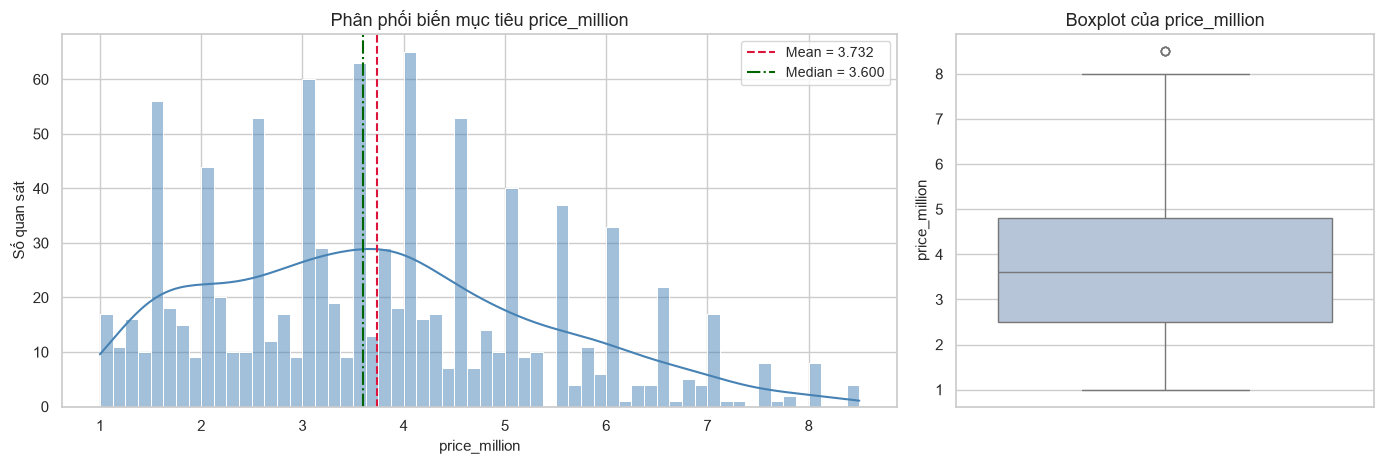

Quan sát tính từ dữ liệu:
                skewness: 0.4639
       mean_minus_median: 0.1316
        n_tukey_outliers: 4.0000
    share_tukey_outliers: 0.0040
             upper_fence: 8.2500
            share_at_max: 0.0040


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={"width_ratios": [2, 1]})

sns.histplot(y, bins=60, kde=True, color="steelblue", ax=axes[0])
axes[0].axvline(y.mean(), color="crimson", linestyle="--", label=f"Mean = {y.mean():.3f}")
axes[0].axvline(y.median(), color="darkgreen", linestyle="-.", label=f"Median = {y.median():.3f}")
axes[0].set_title(f"Phân phối biến mục tiêu {TARGET_COLUMN}")
axes[0].set_xlabel(f"{TARGET_COLUMN}")
axes[0].set_ylabel("Số quan sát")
axes[0].legend()

sns.boxplot(y=y, color="lightsteelblue", ax=axes[1])
axes[1].set_title(f"Boxplot của {TARGET_COLUMN}")
axes[1].set_ylabel(f"{TARGET_COLUMN}")

fig.tight_layout()
save_figure(fig, "03_target_distribution.png")
plt.show()

q1, q3 = y.quantile([0.25, 0.75])
iqr = q3 - q1
upper_fence = q3 + 1.5 * iqr
lower_fence = q1 - 1.5 * iqr
n_outliers = int(((y > upper_fence) | (y < lower_fence)).sum())
target_skew = float(y.skew())

target_observations = {
    "skewness": target_skew,
    "mean_minus_median": float(y.mean() - y.median()),
    "n_tukey_outliers": n_outliers,
    "share_tukey_outliers": n_outliers / len(y),
    "upper_fence": float(upper_fence),
    "share_at_max": share_at_target_max,
}
print("Quan sát tính từ dữ liệu:")
for key, value in target_observations.items():
    print(f"  {key:>22}: {value:.4f}")

**Cách đọc:** nếu `skewness > 0` và `mean > median`, phân phối lệch phải (đuôi giá cao dài). Nếu một tỷ lệ đáng kể quan sát nằm đúng tại giá trị lớn nhất, đó là dấu hiệu dữ liệu bị **chặn trên**: mọi giá trị thật lớn hơn ngưỡng đều bị ghi bằng ngưỡng. Hệ quả: mô hình (đặc biệt là cây) không có cơ hội học được mức giá thật ở vùng này, và các sai số lớn nhất thường tập trung ở đây. Con số cụ thể được in ngay phía trên và được tổng hợp lại ở mục 3.6.

## 3.3. Phân phối các đặc trưng

Mỗi đặc trưng có một biểu đồ riêng, sắp thành lưới nhiều hàng/cột để đủ lớn, dễ đọc. Ta cũng liệt kê các đặc trưng lệch mạnh (|skewness| > 1) — trực giác: *Decision Tree chỉ quan tâm đến thứ tự của giá trị đặc trưng (vì split dạng* `x <= t` *), nên các phép biến đổi đơn điệu như log không làm đổi cây*; còn Linear Regression thì có thể nhạy hơn với phân phối lệch/ngoại lai.

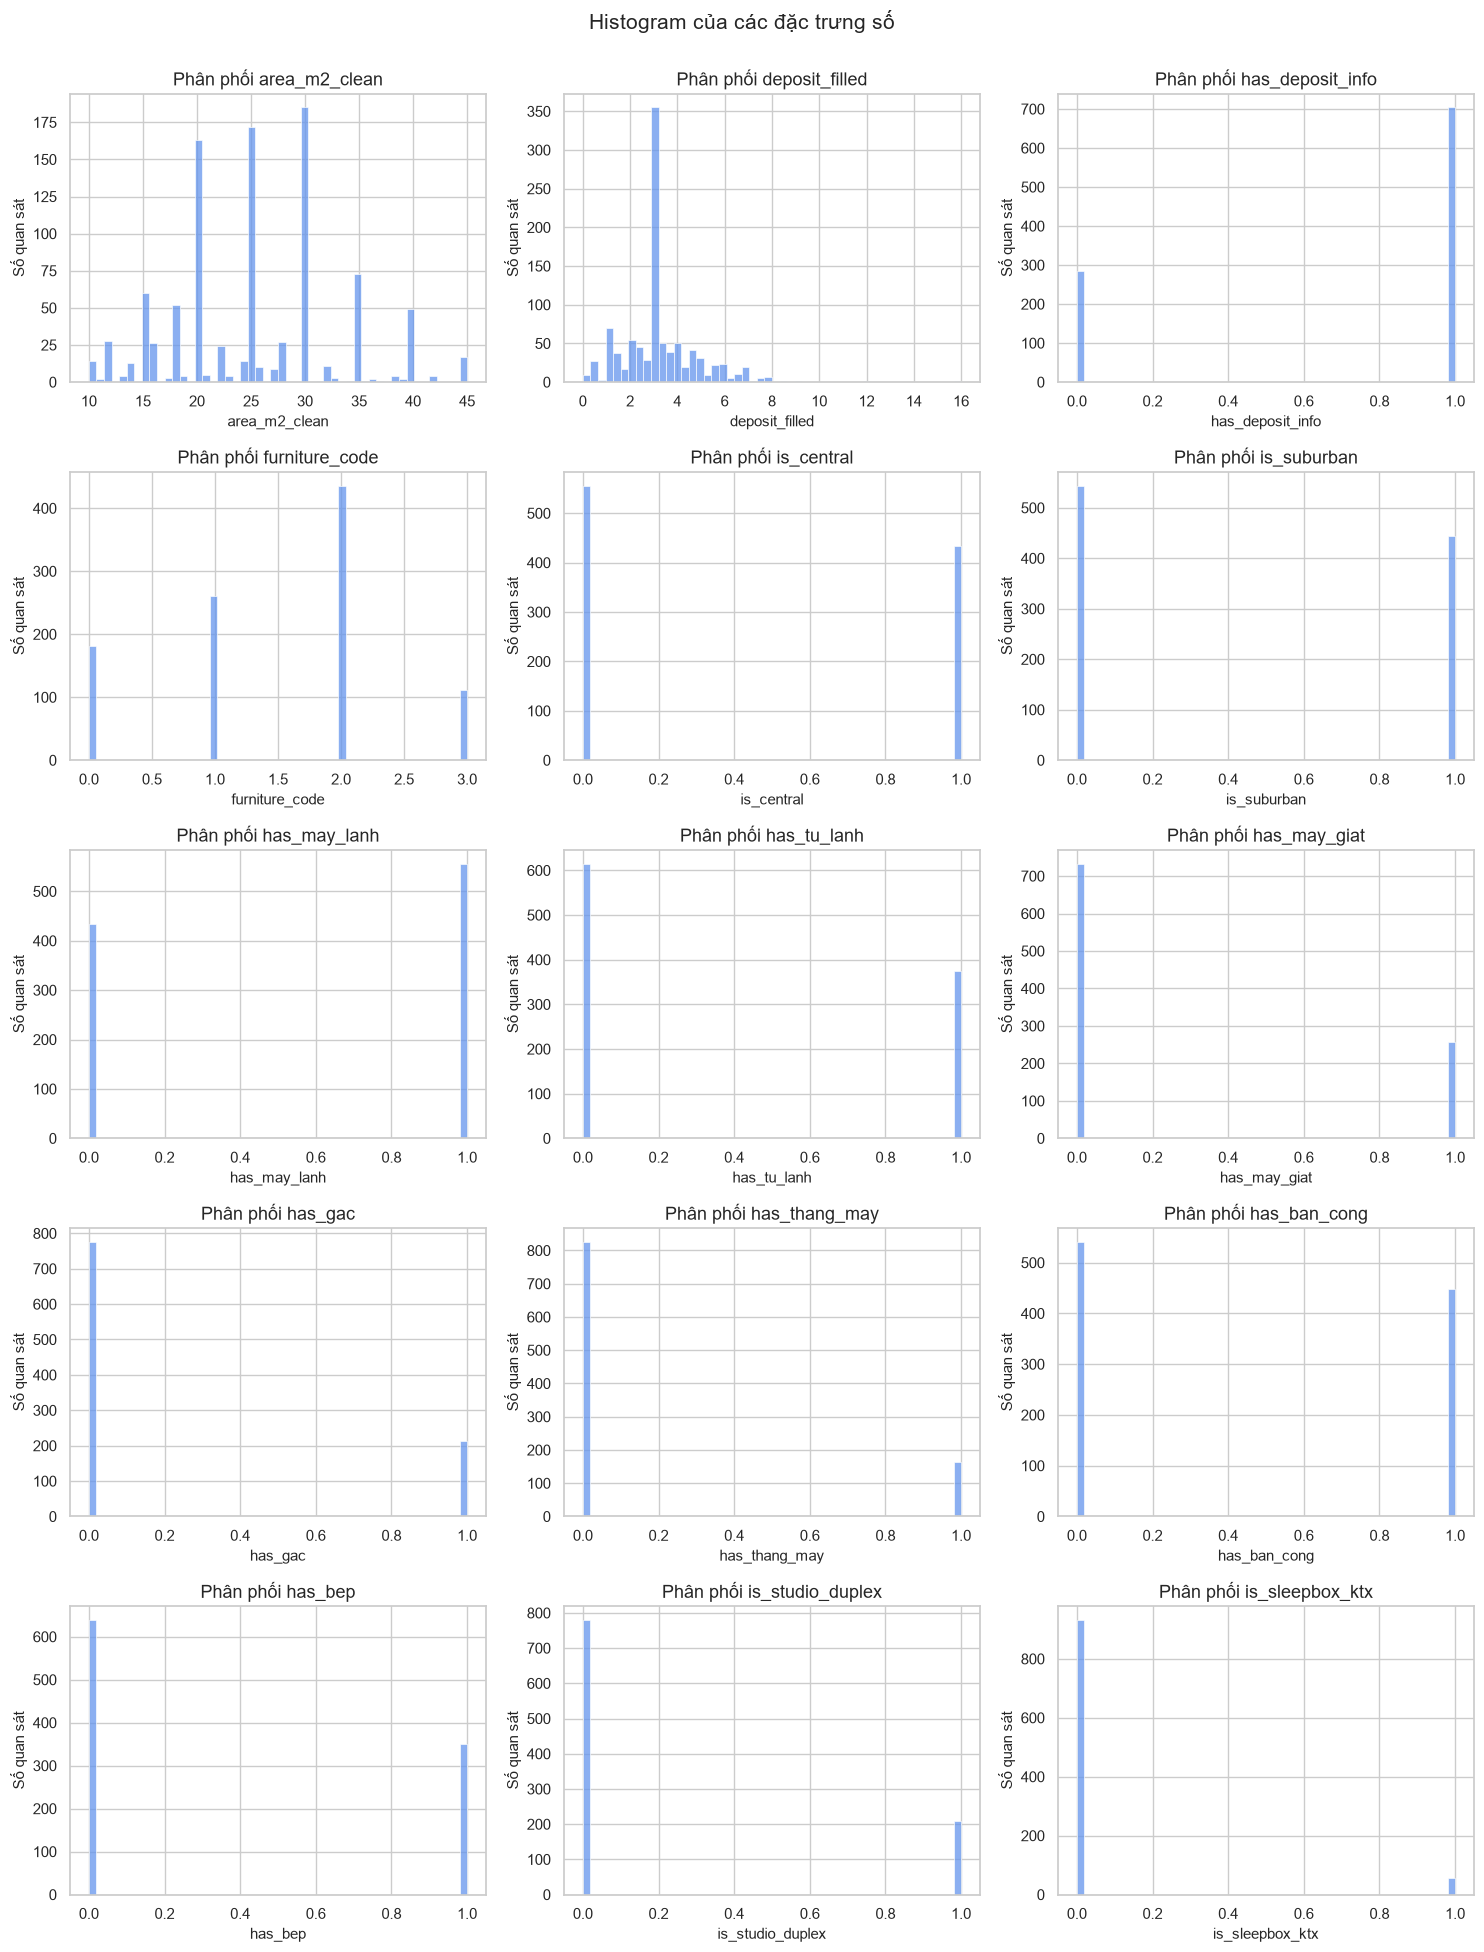

Đặc trưng có |skewness| > 1 (tính từ dữ liệu):


,skewness
is_sleepbox_ktx,3.8021
has_thang_may,1.8096
is_studio_duplex,1.4164
has_gac,1.3869
deposit_filled,1.1749
has_may_giat,1.1028


In [11]:
n_features = len(FEATURE_NAMES)
n_cols_grid = 3
n_rows_grid = int(np.ceil(n_features / n_cols_grid))
fig, axes = plt.subplots(n_rows_grid, n_cols_grid, figsize=(15, 3.9 * n_rows_grid))
axes = np.atleast_1d(axes).ravel()

for ax, feature in zip(axes, FEATURE_NAMES):
    sns.histplot(X[feature], bins=50, color="cornflowerblue", ax=ax)
    ax.set_title(f"Phân phối {feature}")
    ax.set_xlabel(feature)
    ax.set_ylabel("Số quan sát")
for ax in axes[n_features:]:
    ax.set_visible(False)

fig.suptitle("Histogram của các đặc trưng số", y=1.0, fontsize=15)
fig.tight_layout()
save_figure(fig, "03_feature_histograms.png")
plt.show()

feature_skew = X.skew().sort_values(key=lambda s: s.abs(), ascending=False)
skewed_features = feature_skew[feature_skew.abs() > 1]
print("Đặc trưng có |skewness| > 1 (tính từ dữ liệu):")
display(skewed_features.to_frame("skewness"))

## 3.4. Tương quan

Heatmap bên dưới dùng **tương quan Pearson** (đo quan hệ *tuyến tính*) giữa các đặc trưng và mục tiêu. Ta bổ sung **tương quan hạng Spearman** (đo quan hệ *đơn điệu*): nếu Spearman khác nhiều so với Pearson, quan hệ có thể phi tuyến hoặc bị ảnh hưởng bởi ngoại lai.

Ba lưu ý quan trọng khi đọc:

1. Tương quan tuyến tính **không mô tả hết** quan hệ phi tuyến (ví dụ quan hệ hình chữ U cho tương quan gần 0).
2. Tương quan **không chứng minh quan hệ nhân quả**.
3. Decision Tree **không giả định quan hệ tuyến tính** như Linear Regression; nó xấp xỉ hàm bằng các mảng hằng số, nên có thể bắt được quan hệ phi tuyến và tương tác giữa các đặc trưng.

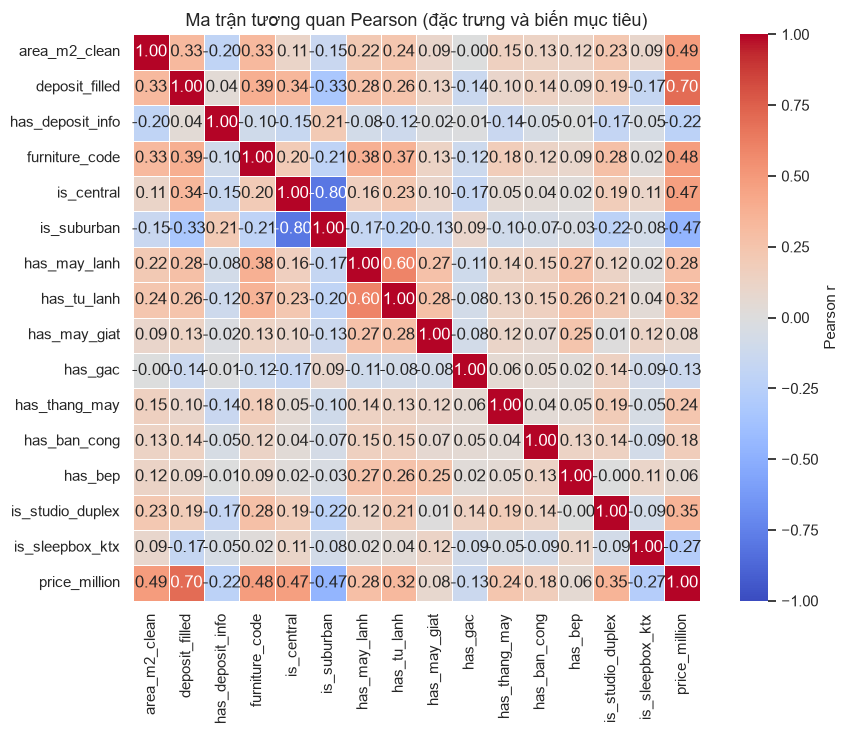

Tương quan của từng đặc trưng với biến mục tiêu (sắp theo |Pearson|):


,pearson,spearman,spearman_minus_pearson
deposit_filled,0.6991,0.7181,0.0191
area_m2_clean,0.4871,0.5006,0.0135
furniture_code,0.4788,0.4786,-0.0003
is_central,0.4690,0.4634,-0.0056
is_suburban,-0.4660,-0.4728,-0.0068
is_studio_duplex,0.3530,0.3639,0.0109
has_tu_lanh,0.3217,0.3457,0.0240
has_may_lanh,0.2826,0.3066,0.0240
is_sleepbox_ktx,-0.2699,-0.2882,-0.0183
has_thang_may,0.2421,0.2509,0.0088



Các cặp đặc trưng có |Pearson| >= 0.5 (tính từ dữ liệu):


,feature_a,feature_b,pearson
65,is_central,is_suburban,-0.7982
97,has_may_lanh,has_tu_lanh,0.5999


In [12]:
corr_pearson = df.corr(method="pearson")
corr_spearman = df.corr(method="spearman")

fig, ax = plt.subplots(figsize=(9.5, 7.5))
sns.heatmap(corr_pearson, annot=True, fmt=".2f", cmap="coolwarm", center=0,
            vmin=-1, vmax=1, square=True, linewidths=0.5, cbar_kws={"label": "Pearson r"}, ax=ax)
ax.set_title("Ma trận tương quan Pearson (đặc trưng và biến mục tiêu)")
fig.tight_layout()
save_figure(fig, "03_correlation_heatmap.png")
plt.show()

target_corr = pd.DataFrame({
    "pearson": corr_pearson[TARGET_COLUMN].drop(TARGET_COLUMN),
    "spearman": corr_spearman[TARGET_COLUMN].drop(TARGET_COLUMN),
})
target_corr["abs_pearson"] = target_corr["pearson"].abs()
target_corr = target_corr.sort_values("abs_pearson", ascending=False).drop(columns="abs_pearson")
target_corr["spearman_minus_pearson"] = target_corr["spearman"] - target_corr["pearson"]
print("Tương quan của từng đặc trưng với biến mục tiêu (sắp theo |Pearson|):")
display(target_corr)

# Cặp đặc trưng tương quan mạnh với nhau (ảnh hưởng đến diễn giải feature importance)
feature_corr = corr_pearson.drop(index=TARGET_COLUMN, columns=TARGET_COLUMN)
pairs = (
    feature_corr.where(np.triu(np.ones(feature_corr.shape, dtype=bool), k=1))
    .stack()
    .rename("pearson")
    .reset_index()
    .rename(columns={"level_0": "feature_a", "level_1": "feature_b"})
)
strong_pairs = pairs[pairs["pearson"].abs() >= 0.5].sort_values("pearson", key=lambda s: s.abs(), ascending=False)
print("\nCác cặp đặc trưng có |Pearson| >= 0.5 (tính từ dữ liệu):")
display(strong_pairs if len(strong_pairs) else pd.DataFrame({"ghi chú": ["không có cặp nào"]}))

## 3.5. Phân tích đặc trưng

### Ý nghĩa các đặc trưng (theo tài liệu nguồn)

In [13]:
if dataset_info["is_custom_dataset"]:
    feature_doc = pd.DataFrame({
        "feature": FEATURE_NAMES,
        "mô tả": [NHATOT_FEATURE_DESCRIPTIONS.get(f, "(đặc trưng dữ liệu Nhà Tốt)") for f in FEATURE_NAMES]
    })
else:
    feature_doc = pd.DataFrame({
        "feature": FEATURE_NAMES,
        "mô tả (theo tài liệu Scikit-learn)": [CALIFORNIA_FEATURE_DESCRIPTIONS.get(f, "?") for f in FEATURE_NAMES],
    })
display(feature_doc.set_index("feature"))


,mô tả
feature,
area_m2_clean,"Diện tích căn phòng (m2), đã làm sạch trong kh..."
deposit_filled,"Tiền đặt cọc (triệu VNĐ), điền khuyết bằng tru..."
has_deposit_info,Biến cờ: tin đăng có công khai thông tin tiền ...
furniture_code,"Tình trạng nội thất: 0=Nhà trống, 1=Cơ bản/Chư..."
is_central,"Biến cờ: Thuộc các quận trung tâm sầm uất (Q1,..."
is_suburban,"Biến cờ: Thuộc khu vực ngoại thành/ven (Q12, B..."
has_may_lanh,Tiện ích: Có máy lạnh / điều hòa không khí
has_tu_lanh,Tiện ích: Có tủ lạnh
has_may_giat,Tiện ích: Có máy giặt hoặc khu giặt chung


### Quan hệ phi tuyến và cấu trúc không gian

Để kiểm tra tính phi tuyến mà **không** dựa riêng vào tương quan đơn biến, ta chia mỗi đặc trưng thành các *bin* theo phân vị và vẽ **trung vị của mục tiêu trong từng bin**. Nếu đường này không phải là đường thẳng, quan hệ không tuyến tính. Ta cũng vẽ bản đồ phân tán theo kinh độ/vĩ độ, tô màu theo giá nhà, để thấy cấu trúc không gian.

> Cảnh báo diễn giải: hình dạng của đường trung vị theo bin chỉ là *mô tả dữ liệu*. Một đặc trưng có đường dốc mạnh **chưa chắc** quan trọng đối với mô hình (có thể bị đặc trưng khác tương quan "che" hoặc thay thế). Độ quan trọng sẽ được xét riêng ở Phần 13.

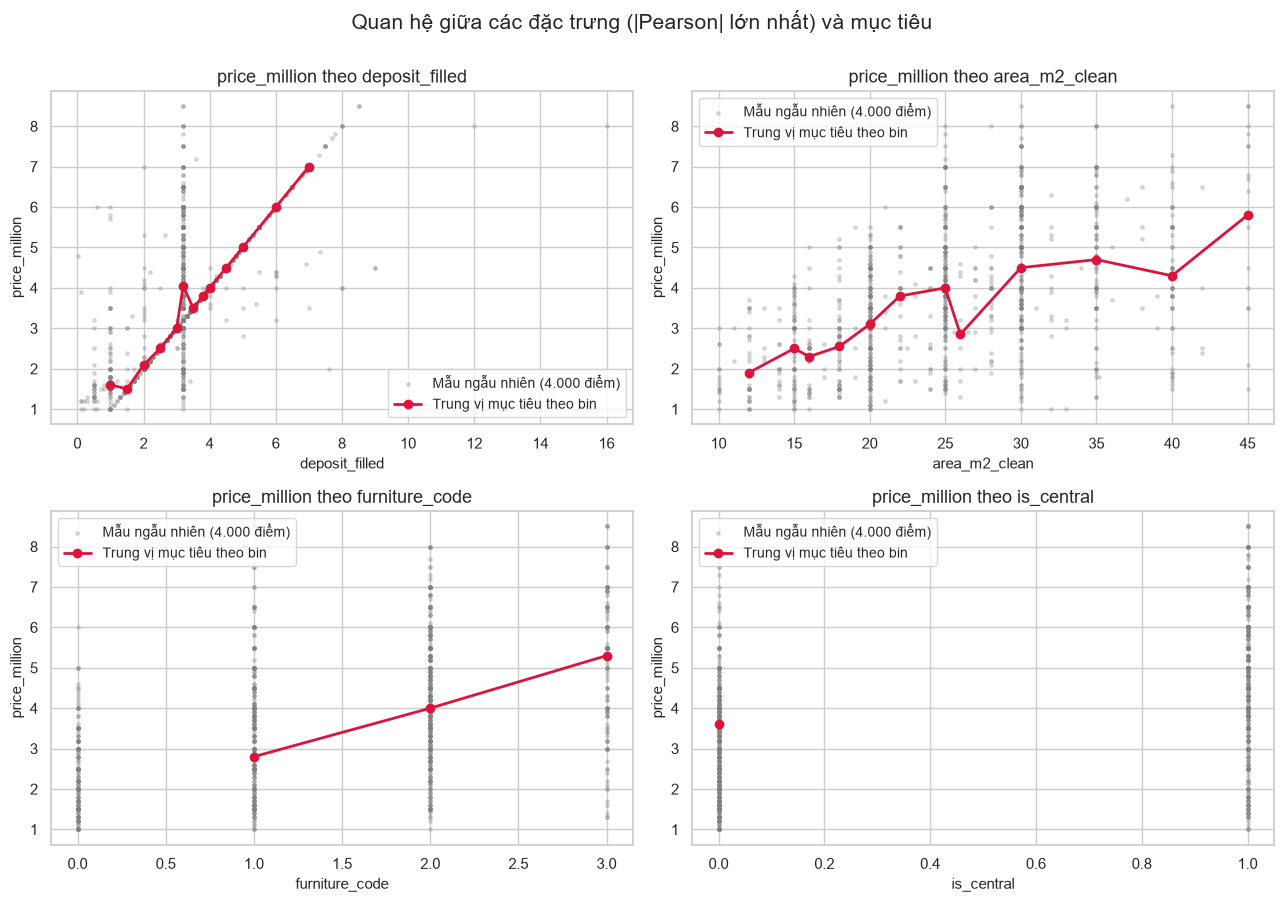

In [14]:
def binned_median_curve(feature_values: pd.Series, target_values: pd.Series, n_bins: int = 20):
    """Trung vị của mục tiêu theo bin phân vị của một đặc trưng."""
    bins = pd.qcut(feature_values, q=n_bins, duplicates="drop")
    grouped = pd.DataFrame({"x": feature_values, "y": target_values, "bin": bins}).groupby("bin", observed=True)
    return grouped["x"].median().to_numpy(), grouped["y"].median().to_numpy()


top_features = list(target_corr.index[:4])
sample_df = df.sample(n=min(4000, len(df)), random_state=RANDOM_STATE)

fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for ax, feature in zip(axes.ravel(), top_features):
    ax.scatter(sample_df[feature], sample_df[TARGET_COLUMN], s=6, alpha=0.25, color="gray", label="Mẫu ngẫu nhiên (4.000 điểm)")
    bx, by = binned_median_curve(df[feature], df[TARGET_COLUMN])
    ax.plot(bx, by, color="crimson", marker="o", linewidth=2, label="Trung vị mục tiêu theo bin")
    ax.set_title(f"{TARGET_COLUMN} theo {feature}")
    ax.set_xlabel(feature)
    ax.set_ylabel(TARGET_COLUMN)
    ax.legend(loc="best")
fig.suptitle("Quan hệ giữa các đặc trưng (|Pearson| lớn nhất) và mục tiêu", y=1.0, fontsize=15)
fig.tight_layout()
save_figure(fig, "03_target_vs_top_features.png")
plt.show()

if {"Latitude", "Longitude"}.issubset(df.columns):
    fig, ax = plt.subplots(figsize=(8.5, 7))
    sc = ax.scatter(df["Longitude"], df["Latitude"], c=df[TARGET_COLUMN], s=5, cmap="viridis", alpha=0.7)
    fig.colorbar(sc, ax=ax, label=TARGET_COLUMN)
    ax.set_title("Phân bố không gian của biến mục tiêu")
    ax.set_xlabel("Longitude (kinh độ)")
    ax.set_ylabel("Latitude (vĩ độ)")
    fig.tight_layout()
    save_figure(fig, "03_spatial_target_map.png")
    plt.show()

## 3.6. Kết luận EDA

Cell dưới đây **sinh nhận xét từ các số liệu đã tính ở trên**; mỗi nhận xét chỉ xuất hiện nếu điều kiện tương ứng thực sự đúng với dữ liệu đang chạy. Nếu bạn dùng dataset thay thế, nội dung sẽ tự thay đổi theo.

In [15]:
lines = ["### Kết luận EDA (sinh tự động từ số liệu của lần chạy này)\n"]
lines.append(f"- Dataset **{dataset_info['dataset_name']}**: {n_rows:,} dòng, {X.shape[1]} đặc trưng số, "
             f"{n_missing_total} giá trị thiếu, {n_inf_total} giá trị vô hạn, {n_duplicate_rows} dòng trùng lặp.")
lines.append(f"- Biến mục tiêu: trung bình {y.mean():.3f}, trung vị {y.median():.3f}, độ lệch (skewness) {target_skew:.2f}, "
             f"độ lệch chuẩn {y.std():.3f}.")
if target_skew > 0.5 and y.mean() > y.median():
    lines.append("  - Phân phối **lệch phải** (skewness > 0.5 và mean > median): sai số ở nhóm giá cao sẽ đóng góp nhiều vào MSE/RMSE.")
if share_at_target_max > 0.01:
    lines.append(f"- **{share_at_target_max:.2%}** quan sát nằm đúng tại giá trị lớn nhất ({target_max:.5f}) — dấu hiệu mục tiêu bị chặn trên. "
                 "Mô hình không thể học mức giá thật vượt ngưỡng; đây là giới hạn của dữ liệu, không phải lỗi của thuật toán.")
if len(skewed_features):
    lines.append("- Đặc trưng lệch mạnh (|skewness| > 1): " + ", ".join(f"{n} ({v:.1f})" for n, v in skewed_features.items())
                 + ". Cây không bị ảnh hưởng bởi biến đổi đơn điệu của đặc trưng; Linear Regression thì có thể.")
top_name = target_corr.index[0]
lines.append(f"- Đặc trưng có |Pearson| lớn nhất với mục tiêu: **{top_name}** (Pearson = {target_corr.loc[top_name, 'pearson']:.2f}, "
             f"Spearman = {target_corr.loc[top_name, 'spearman']:.2f}). Đây là tương quan đơn biến, chưa phải bằng chứng về tầm quan trọng của đặc trưng trong mô hình.")
if len(strong_pairs):
    pair_text = "; ".join(f"{r.feature_a}–{r.feature_b} ({r.pearson:.2f})" for r in strong_pairs.itertuples())
    lines.append(f"- Có các cặp đặc trưng tương quan mạnh với nhau: {pair_text}. Điều này làm feature importance dễ bị chia sẻ/thay thế giữa các đặc trưng (Phần 13).")
if {"Latitude", "Longitude"}.issubset(df.columns):
    lines.append("- Dữ liệu có tọa độ địa lý; bản đồ phân tán cho thấy giá nhà có cấu trúc không gian rõ rệt, vì vậy phép chia ngẫu nhiên train/test là **ước lượng lạc quan** cho khả năng tổng quát hóa sang vùng địa lý mới (Phần 04).")

lines.append("\n**Rủi ro cần kiểm soát trong thiết kế thực nghiệm**\n")
lines.append("1. Dùng cùng một split và cùng các fold CV cho mọi mô hình để so sánh công bằng.")
lines.append("2. Không dùng nhãn test để chọn bất cứ siêu tham số nào.")
lines.append("3. Báo cáo cả độ biến thiên (độ lệch chuẩn giữa các fold), không chỉ giá trị trung bình.")
lines.append("4. Khi diễn giải sai số, nhớ rằng RMSE nhạy với đuôi phải của phân phối mục tiêu.")
show_md("\n".join(lines))
SECTION_STATUS["03"] = "hoàn thành"

### Kết luận EDA (sinh tự động từ số liệu của lần chạy này)

- Dataset **Nha Tot Rental Housing (TP.HCM)**: 989 dòng, 15 đặc trưng số, 0 giá trị thiếu, 0 giá trị vô hạn, 12 dòng trùng lặp.
- Biến mục tiêu: trung bình 3.732, trung vị 3.600, độ lệch (skewness) 0.46, độ lệch chuẩn 1.638.
- Đặc trưng lệch mạnh (|skewness| > 1): is_sleepbox_ktx (3.8), has_thang_may (1.8), is_studio_duplex (1.4), has_gac (1.4), deposit_filled (1.2), has_may_giat (1.1). Cây không bị ảnh hưởng bởi biến đổi đơn điệu của đặc trưng; Linear Regression thì có thể.
- Đặc trưng có |Pearson| lớn nhất với mục tiêu: **deposit_filled** (Pearson = 0.70, Spearman = 0.72). Đây là tương quan đơn biến, chưa phải bằng chứng về tầm quan trọng của đặc trưng trong mô hình.
- Có các cặp đặc trưng tương quan mạnh với nhau: is_central–is_suburban (-0.80); has_may_lanh–has_tu_lanh (0.60). Điều này làm feature importance dễ bị chia sẻ/thay thế giữa các đặc trưng (Phần 13).

**Rủi ro cần kiểm soát trong thiết kế thực nghiệm**

1. Dùng cùng một split và cùng các fold CV cho mọi mô hình để so sánh công bằng.
2. Không dùng nhãn test để chọn bất cứ siêu tham số nào.
3. Báo cáo cả độ biến thiên (độ lệch chuẩn giữa các fold), không chỉ giá trị trung bình.
4. Khi diễn giải sai số, nhớ rằng RMSE nhạy với đuôi phải của phân phối mục tiêu.

<a id="part-04"></a>
# PHẦN 04 — Train/Test split và thiết kế thực nghiệm

## 4.1. Nguyên tắc chia dữ liệu

| Tập | Số lượng mẫu | Tỷ lệ | Dùng để làm gì | **Không** được làm gì |
|---|---|---|---|---|
| **Train** | 792 | 80% | Huấn luyện mô hình; 5-fold cross-validation chọn siêu tham số | Tuyệt đối không tính trước thống kê dựa trên tập Test |
| **Test** | 197 | 20% | Đánh giá độc lập chất lượng cuối cùng (chỉ dùng 1 lần duy nhất) | Chọn tham số, chọn đặc trưng, hoặc so sánh lặp đi lặp lại |

Việc chọn độ sâu và `min_samples_leaf` được thực hiện bằng **5-fold `KFold(shuffle=True, random_state=42)` trên tập train**. Các fold được tạo **một lần** và dùng chung cho mọi cấu hình, nên mọi cấu hình được so sánh trên đúng cùng các lần chia dữ liệu (so sánh có ghép cặp, ít nhiễu hơn).

## 4.2. Khả năng tổng quát hóa và tính độc lập

Với tập dữ liệu phòng trọ Nhà Tốt tại TP.HCM, phép chia ngẫu nhiên 80/20 mô phỏng bài toán dự đoán giá thuê của những căn phòng mới xuất hiện trên thị trường đô thị. Các đặc trưng vị trí được tóm lược thông qua biến cờ `is_central` và `is_suburban` cùng các tiện nghi cụ thể, giúp mô hình tập trung học các mối quan hệ nội tại giữa chất lượng phòng và mức giá, tránh bị phụ thuộc quá mức vào một vài tọa độ cá biệt.


In [16]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE
)

split_summary = pd.DataFrame({
    "Tập": ["Train", "Test", "Tổng"],
    "Số mẫu": [len(X_train), len(X_test), len(X)],
    "Số đặc trưng": [X_train.shape[1], X_test.shape[1], X.shape[1]],
    "Tỷ lệ": [len(X_train) / len(X), len(X_test) / len(X), 1.0],
})
display(split_summary.set_index("Tập"))

# Kiểm tra không giao nhau và không mất mẫu
assert set(X_train.index).isdisjoint(set(X_test.index)), "Train/test giao nhau!"
assert len(X_train) + len(X_test) == len(X), "Mất mẫu khi chia."

# Cố định các fold CV (tạo một lần, dùng chung cho mọi mô hình/cấu hình)
cv_splitter = KFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)
CV_FOLD_INDICES = [(tr.copy(), va.copy()) for tr, va in cv_splitter.split(X_train)]
print("\nKích thước các fold (train/validation):",
      [(len(tr), len(va)) for tr, va in CV_FOLD_INDICES])

# Sổ ghi sử dụng tập test: từ giờ nhãn test chỉ được dùng qua đối tượng này
TEST_LEDGER = TestSetLedger(y_test)

,Số mẫu,Số đặc trưng,Tỷ lệ
Tập,,,
Train,791,15,0.7998
Test,198,15,0.2002
Tổng,989,15,1.0000



Kích thước các fold (train/validation): [(632, 159), (633, 158), (633, 158), (633, 158), (633, 158)]


## 4.3. So sánh phân phối mục tiêu giữa train và test

Biểu đồ này chỉ nhằm **kiểm tra** hai tập có phân phối mục tiêu tương tự (chia ngẫu nhiên nên kỳ vọng như vậy). Đây là bước kiểm tra sanity, **không** dùng để điều chỉnh mô hình.

Ta cũng kiểm tra *rò rỉ qua dòng trùng lặp*: có bao nhiêu dòng test có vector đặc trưng **giống hệt** một dòng nào đó trong train (nếu nhiều, kết quả test sẽ lạc quan).

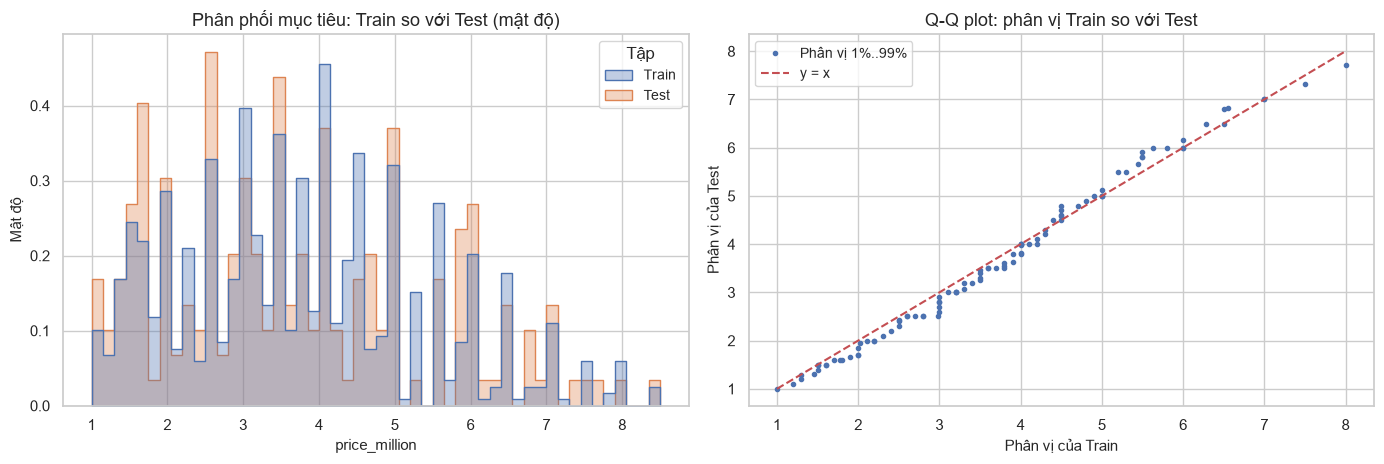

,train,test,chênh lệch (test - train)
count,791.0000,198.0000,-593.0000
mean,3.7432,3.6855,-0.0577
std,1.6149,1.7323,0.1174
min,1.0000,1.0000,0.0000
25%,2.5000,2.4000,-0.1000
50%,3.6000,3.5000,-0.1000
75%,4.8000,4.9000,0.1000
max,8.5000,8.5000,0.0000



Số dòng test có đặc trưng giống hệt một dòng train: 12 / 198


In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
plot_df = pd.concat([
    pd.DataFrame({TARGET_COLUMN: y_train.to_numpy(), "Tập": "Train"}),
    pd.DataFrame({TARGET_COLUMN: y_test.to_numpy(), "Tập": "Test"}),
])
sns.histplot(data=plot_df, x=TARGET_COLUMN, hue="Tập", bins=50, stat="density",
             common_norm=False, element="step", fill=True, alpha=0.35, ax=axes[0])
axes[0].set_title("Phân phối mục tiêu: Train so với Test (mật độ)")
axes[0].set_xlabel(TARGET_COLUMN)
axes[0].set_ylabel("Mật độ")

quantile_levels = np.linspace(0.01, 0.99, 99)
q_train = np.quantile(y_train, quantile_levels)
q_test = np.quantile(y_test, quantile_levels)
axes[1].plot(q_train, q_test, "o", markersize=3, label="Phân vị 1%..99%")
lims = [min(q_train.min(), q_test.min()), max(q_train.max(), q_test.max())]
axes[1].plot(lims, lims, "r--", label="y = x")
axes[1].set_title("Q-Q plot: phân vị Train so với Test")
axes[1].set_xlabel("Phân vị của Train")
axes[1].set_ylabel("Phân vị của Test")
axes[1].legend()
fig.tight_layout()
save_figure(fig, "04_train_test_target_distribution.png")
plt.show()

target_stats = pd.DataFrame({
    "train": y_train.describe(),
    "test": y_test.describe(),
})
target_stats["chênh lệch (test - train)"] = target_stats["test"] - target_stats["train"]
display(target_stats)

# Rò rỉ qua dòng trùng lặp giữa train và test
train_hashes = set(pd.util.hash_pandas_object(X_train, index=False).tolist())
test_hashes = pd.util.hash_pandas_object(X_test, index=False)
n_test_rows_seen_in_train = int(test_hashes.isin(train_hashes).sum())
print(f"\nSố dòng test có đặc trưng giống hệt một dòng train: {n_test_rows_seen_in_train} / {len(X_test)}")
SECTION_STATUS["04"] = "hoàn thành"

<a id="part-05"></a>
# PHẦN 05 — Cơ sở toán học của Decision Tree Regression

## 5.1. Decision Tree là gì?

Cây quyết định chia không gian đặc trưng thành các **vùng hình hộp chữ nhật** bằng một chuỗi câu hỏi dạng *"đặc trưng $j$ có $\le$ ngưỡng $t$ không?"*, rồi dự đoán **một hằng số** cho mỗi vùng.

| Thuật ngữ | Ý nghĩa |
|---|---|
| **Root node** | Node gốc, chứa toàn bộ mẫu huấn luyện |
| **Internal node** | Node có điều kiện chia (feature + threshold), có hai con |
| **Split** | Một cặp (đặc trưng $j$, ngưỡng $t$) |
| **Threshold** | Ngưỡng $t$ để so sánh `x[j] <= t` |
| **Left child** | Nhánh của các mẫu thỏa `x[j] <= t` |
| **Right child** | Nhánh của các mẫu còn lại (`x[j] > t`) |
| **Leaf node** | Node lá, không chia nữa, mang giá trị dự đoán |
| **Prediction** | Giá trị lưu ở leaf mà mẫu rơi vào |

Ví dụ **chỉ để minh họa cấu trúc** (ngưỡng 5 và các giá trị bên dưới là *giả định*, không phải kết quả thực của dataset):

```
                 [Root]  area_m2_clean <= threshold ?
                    /                      \
          Có (nhánh trái)           Không (nhánh phải)
                 /                            \
        [Leaf] dự đoán = ĝ₁            [Internal] is_central <= threshold' ?
                                              /                \
                                       [Leaf] ĝ₂             [Leaf] ĝ₃
```

Nếu `area_m2_clean <= threshold` thì đi sang nhánh trái; ngược lại đi sang nhánh phải. Hàm dự đoán của cây là một hàm **hằng theo từng mảng** (piecewise constant) — ta sẽ thấy dạng "bậc thang" này ở Phần 08.

## 5.2. Dự đoán tại leaf

Với tiêu chí squared-error, giá trị dự đoán tại leaf là **trung bình** mục tiêu của các mẫu huấn luyện rơi vào leaf:

$$
\hat y_{\text{leaf}} = \frac{1}{N_{\text{leaf}}}\sum_{i=1}^{N_{\text{leaf}}} y_i
$$

**Vì sao trung bình là tối ưu?** Trong một leaf ta chọn một hằng số $c$ để tối thiểu tổng bình phương sai số $L(c)=\sum_{i}(y_i-c)^2$. Lấy đạo hàm:

$$
\frac{dL}{dc} = -2\sum_{i=1}^{N}(y_i-c)=0 \;\Longrightarrow\; c=\frac{1}{N}\sum_{i=1}^{N}y_i=\bar y,
\qquad \frac{d^2L}{dc^2}=2N>0 .
$$

Đạo hàm bậc hai dương nên $\bar y$ là cực **tiểu**. Có thể thấy rõ hơn qua đẳng thức:

$$
\sum_{i}(y_i-c)^2=\sum_{i}(y_i-\bar y)^2 + N(\bar y-c)^2 \;\ge\; \sum_{i}(y_i-\bar y)^2,
$$

dấu "=" xảy ra khi và chỉ khi $c=\bar y$.

## 5.3. MSE (độ "không thuần nhất" của một node)

$$
\mathrm{MSE}(S)=\frac{1}{|S|}\sum_{i\in S}\left(y_i-\bar y_S\right)^2,\qquad \bar y_S=\frac{1}{|S|}\sum_{i\in S}y_i
$$

- $S$: tập mẫu trong node; $|S|$: số mẫu; $y_i$: giá trị thực; $\bar y_S$: trung bình mục tiêu trong node.
- $\mathrm{MSE}(S)$ chính là **phương sai** (chia cho $|S|$) của mục tiêu trong node: nó đo độ phân tán quanh trung bình. $\mathrm{MSE}(S)=0$ khi mọi $y_i$ trong node bằng nhau (node "thuần nhất").
- Vì leaf dự đoán bằng $\bar y_S$, nên $\mathrm{MSE}(S)$ chính là **sai số bình phương trung bình trên tập huấn luyện của node đó**. Tổng sai số huấn luyện của cả cây là trung bình có trọng số của MSE các leaf.
- Ta cũng dùng $\mathrm{SSE}(S)=|S|\cdot\mathrm{MSE}(S)=\sum_{i\in S}(y_i-\bar y_S)^2$.

## 5.4. Tiêu chí chia (split criterion)

Một split $(j,t)$ chia $S$ thành $S_L=\{i\in S: x_{ij}\le t\}$ và $S_R=S\setminus S_L$. Impurity **sau khi chia** là trung bình có trọng số:

$$
I_{\text{after}}=\frac{|S_L|}{|S|}\,\mathrm{MSE}(S_L)+\frac{|S_R|}{|S|}\,\mathrm{MSE}(S_R)
$$

Mức giảm impurity:

$$
\Delta I=\mathrm{MSE}(S)-I_{\text{after}}
$$

Cây chọn split **hợp lệ** có $\Delta I$ **lớn nhất**.

**Vì sao phải trọng số theo số mẫu?** $I_{\text{after}}$ phải là *sai số bình phương trung bình của toàn bộ node $S$ sau khi dự đoán bằng hai trung bình con*. Mẫu thuộc node con nào chịu sai số của node con đó, nên mỗi node con đóng góp tỷ lệ với phần mẫu mà nó chứa. Nếu dùng trung bình không trọng số, một node con chỉ có 1 mẫu (MSE = 0) sẽ có sức ảnh hưởng ngang một node con có 1.000 mẫu, dẫn đến những split "cắt lẻ" vô nghĩa.

**Vì sao $\Delta I\ge 0$?** Luật phương sai toàn phần (law of total variance) cho đẳng thức:

$$
\mathrm{MSE}(S)=\underbrace{\frac{|S_L|}{|S|}\mathrm{MSE}(S_L)+\frac{|S_R|}{|S|}\mathrm{MSE}(S_R)}_{I_{\text{after}}\;\text{(phương sai trong nhóm)}}
+\underbrace{\frac{|S_L|}{|S|}(\bar y_L-\bar y_S)^2+\frac{|S_R|}{|S|}(\bar y_R-\bar y_S)^2}_{\text{phương sai giữa hai nhóm}\;\ge 0}
$$

Suy ra $\Delta I$ **bằng phương sai giữa hai nhóm** $\ge 0$, và $\Delta I=0$ khi và chỉ khi $\bar y_L=\bar y_R$. Diễn giải: một phép chia tốt là phép chia làm **hai trung bình con tách xa nhau nhất** (có trọng số). Hệ quả thực hành:

- Về mặt toán học, $\Delta I<0$ **không thể xảy ra**. Nếu code cho $\Delta I$ âm đáng kể thì đó là *lỗi triển khai hoặc lỗi số học* (ví dụ tính sai trọng số, nhầm SSE/MSE), và thuật toán đúng không bao giờ chọn split như vậy (luôn có phương án "giữ nguyên node").
- $\Delta I=0$ có thể xảy ra với split hữu ích (ví dụ dữ liệu kiểu XOR: split đầu không giảm sai số nhưng split sau thì có). Vì thế cây của Scikit-learn và cây tự cài đặt ở đây cho phép split có $\Delta I\ge 0$ khi `min_impurity_decrease = 0` — đây là bản chất *tham lam* (greedy) của thuật toán.

**Quy ước có trọng số theo root** (dùng cho `min_impurity_decrease` và feature importance — trùng với Scikit-learn): với $N$ là số mẫu ở root,

$$
\Delta I_w=\frac{|S|}{N}\,\Delta I .
$$

Một split chỉ được thực hiện nếu $\Delta I_w \ge$ `min_impurity_decrease`. Importance của đặc trưng $j$ là $\sum_{\text{node dùng }j}\Delta I_w$, rồi chuẩn hóa để tổng bằng 1. Đẳng thức tiện kiểm tra: $\sum_{\text{mọi node trong}}\Delta I_w=\mathrm{MSE}(\text{root})-\text{MSE}_{\text{train của cây}}$ (ta sẽ dùng nó làm một unit test ở Phần 07).

## 5.5. Ví dụ tính tay

Dữ liệu: $x=[1,2,3,4]$, $y=[2,2,8,8]$, xét ngưỡng $t=2.5$.

**Node cha** $S=\{(1,2),(2,2),(3,8),(4,8)\}$:

- $\bar y_S=(2+2+8+8)/4=5$
- $\mathrm{MSE}(S)=\frac{(2-5)^2+(2-5)^2+(8-5)^2+(8-5)^2}{4}=\frac{9+9+9+9}{4}=9$

**Node trái** $S_L=\{x\le 2.5\}=\{(1,2),(2,2)\}$: $\bar y_L=2$, $\mathrm{MSE}(S_L)=0$.

**Node phải** $S_R=\{x> 2.5\}=\{(3,8),(4,8)\}$: $\bar y_R=8$, $\mathrm{MSE}(S_R)=0$.

**Sau chia:** $I_{\text{after}}=\frac{2}{4}\cdot 0+\frac{2}{4}\cdot 0=0$. **Mức giảm:** $\Delta I=9-0=9$.

Kiểm tra bằng công thức phương sai giữa hai nhóm: $\frac{2}{4}(2-5)^2+\frac{2}{4}(8-5)^2=4.5+4.5=9$ ✔.

Để thấy vì sao split này *tốt*, so sánh với hai ngưỡng khác:

| Ngưỡng $t$ | $S_L$ (y) | $S_R$ (y) | $\mathrm{MSE}(S_L)$ | $\mathrm{MSE}(S_R)$ | $I_{\text{after}}$ | $\Delta I$ |
|---|---|---|---|---|---|---|
| 1.5 | [2] | [2, 8, 8] | 0 | $\frac{(2-6)^2+(8-6)^2+(8-6)^2}{3}=8$ | $\frac14\cdot0+\frac34\cdot 8=6$ | $9-6=3$ |
| **2.5** | [2, 2] | [8, 8] | 0 | 0 | 0 | **9** |
| 3.5 | [2, 2, 8] | [8] | $\frac{(2-4)^2+(2-4)^2+(8-4)^2}{3}=8$ | 0 | $\frac34\cdot 8+\frac14\cdot0=6$ | $9-6=3$ |

Ngưỡng 2.5 gom được hai nhóm **đồng nhất** (mỗi nhóm có $y$ bằng nhau) nên impurity về 0. Hai ngưỡng kia trộn lẫn 2 và 8 trong cùng một nhóm nên MSE nhóm lớn.

Bây giờ **xác nhận bằng code NumPy** — lần lượt tính theo định nghĩa (không dùng hàm tối ưu nào của cây), và kiểm tra đẳng thức phương sai giữa nhóm.

threshold,1.5000,2.5000,3.5000
mean_parent,5.0000,5.0000,5.0000
mse_parent,9.0000,9.0000,9.0000
mean_left,2.0000,2.0000,4.0000
mse_left,0.0000,0.0000,8.0000
mean_right,6.0000,8.0000,8.0000
mse_right,8.0000,0.0000,0.0000
weighted_mse_after,6.0000,0.0000,6.0000
impurity_decrease,3.0000,9.0000,3.0000
between_group_variance,3.0000,9.0000,3.0000


Kết quả code khớp với phép tính tay và đẳng thức phương sai giữa nhóm.
Đẳng thức 'mức giảm impurity = phương sai giữa hai nhóm >= 0' đúng trên 200 split ngẫu nhiên.


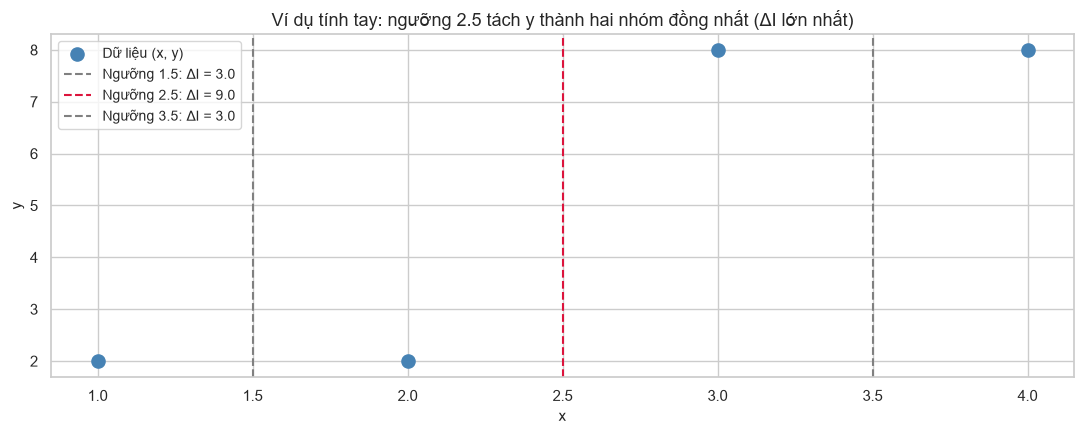

In [18]:
x_demo = np.array([1.0, 2.0, 3.0, 4.0])
y_demo = np.array([2.0, 2.0, 8.0, 8.0])


def mse_by_definition(values: np.ndarray) -> float:
    """MSE(S) = trung bình của (y - mean(y))^2, đúng theo định nghĩa ở mục 5.3."""
    return float(np.mean((values - values.mean()) ** 2))


def split_report(x, y_values, threshold):
    left, right = y_values[x <= threshold], y_values[x > threshold]
    parent_mse = mse_by_definition(y_values)
    weighted_after = (len(left) / len(y_values)) * mse_by_definition(left) \
                   + (len(right) / len(y_values)) * mse_by_definition(right)
    between_group = (len(left) / len(y_values)) * (left.mean() - y_values.mean()) ** 2 \
                  + (len(right) / len(y_values)) * (right.mean() - y_values.mean()) ** 2
    return {
        "threshold": threshold,
        "mean_parent": y_values.mean(), "mse_parent": parent_mse,
        "mean_left": left.mean(), "mse_left": mse_by_definition(left),
        "mean_right": right.mean(), "mse_right": mse_by_definition(right),
        "weighted_mse_after": weighted_after,
        "impurity_decrease": parent_mse - weighted_after,
        "between_group_variance": between_group,
    }


hand_example = pd.DataFrame([split_report(x_demo, y_demo, t) for t in (1.5, 2.5, 3.5)]).set_index("threshold")
display(hand_example.T)

# Đối chiếu với kết quả tính tay trong Markdown ở trên
report_25 = hand_example.loc[2.5]
assert np.isclose(report_25["mean_parent"], 5.0) and np.isclose(report_25["mse_parent"], 9.0)
assert np.isclose(report_25["mean_left"], 2.0) and np.isclose(report_25["mse_left"], 0.0)
assert np.isclose(report_25["mean_right"], 8.0) and np.isclose(report_25["mse_right"], 0.0)
assert np.isclose(report_25["weighted_mse_after"], 0.0) and np.isclose(report_25["impurity_decrease"], 9.0)
assert np.isclose(hand_example.loc[1.5, "impurity_decrease"], 3.0)
assert np.isclose(hand_example.loc[3.5, "impurity_decrease"], 3.0)
# Đẳng thức: mức giảm impurity = phương sai giữa hai nhóm (luôn >= 0)
assert np.allclose(hand_example["impurity_decrease"], hand_example["between_group_variance"])
print("Kết quả code khớp với phép tính tay và đẳng thức phương sai giữa nhóm.")

# Kiểm tra đẳng thức trên dữ liệu ngẫu nhiên (cùng công thức) để chắc chắn nó không chỉ đúng cho ví dụ nhỏ
rng_check = make_rng(1)
for _ in range(200):
    x_r = rng_check.normal(size=30)
    y_r = rng_check.normal(size=30) + 2 * x_r
    t_r = rng_check.choice(x_r[:-1])
    if (x_r <= t_r).sum() in (0, len(x_r)):
        continue
    rep = split_report(x_r, y_r, t_r)
    assert rep["impurity_decrease"] >= -1e-12
    assert np.isclose(rep["impurity_decrease"], rep["between_group_variance"])
print("Đẳng thức 'mức giảm impurity = phương sai giữa hai nhóm >= 0' đúng trên 200 split ngẫu nhiên.")

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.scatter(x_demo, y_demo, s=90, color="steelblue", zorder=3, label="Dữ liệu (x, y)")
for t, color in zip((1.5, 2.5, 3.5), ("gray", "crimson", "gray")):
    gain = hand_example.loc[t, "impurity_decrease"]
    ax.axvline(t, linestyle="--", color=color, label=f"Ngưỡng {t}: ΔI = {gain:.1f}")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title("Ví dụ tính tay: ngưỡng 2.5 tách y thành hai nhóm đồng nhất (ΔI lớn nhất)")
ax.legend()
fig.tight_layout()
save_figure(fig, "05_hand_example_split.png")
plt.show()
SECTION_STATUS["05"] = "hoàn thành"

<a id="part-06"></a>
# PHẦN 06 — Thiết kế Custom Decision Tree Regressor

## 6.0. Thuật toán dưới dạng pseudocode

```
HÀM BUILD(S, depth):                       # S: các mẫu của node, N: số mẫu ở root
    n  ← |S|;   ŷ ← mean(y_S);   I ← MSE(S)
    tạo node với (value=ŷ, impurity=I, n_samples=n, depth)
    NẾU điều kiện dừng:                    # max_depth, n < min_samples_split,
        TRẢ VỀ node                        # n < 2·min_samples_leaf, node đồng nhất
    (j*, t*, ΔI*) ← BEST_SPLIT(S)
    NẾU không có split hợp lệ HOẶC (n/N)·ΔI* < min_impurity_decrease:
        TRẢ VỀ node
    S_L ← {i ∈ S : x[i, j*] ≤ t*};   S_R ← S \ S_L
    node.left  ← BUILD(S_L, depth+1)
    node.right ← BUILD(S_R, depth+1)
    TRẢ VỀ node

HÀM BEST_SPLIT(S):
    best ← không có
    VỚI MỖI đặc trưng j:
        sắp xếp S theo x[:, j]
        tính tổng và tổng bình phương TÍCH LŨY của y đã sắp xếp
        VỚI MỖI vị trí k nằm giữa hai giá trị x KHÁC NHAU, và thỏa min_samples_leaf cho cả hai bên:
            ΔI(j, k) ← MSE(S) − (SSE_L + SSE_R) / |S|
            t(j, k)  ← trung điểm của hai giá trị x kề nhau
        cập nhật best nếu ΔI lớn hơn  (đồng hạng → đặc trưng có chỉ số nhỏ hơn, rồi ngưỡng nhỏ hơn)
    TRẢ VỀ best
```

## 6.0.1. Tìm split nhanh bằng tổng tích lũy

Cách ngây thơ tính lại $\mathrm{MSE}$ cho từng ngưỡng ứng viên tốn $O(n)$ mỗi ngưỡng, tức $O(n^2)$ cho một đặc trưng. Ta dùng đẳng thức:

$$
\mathrm{SSE}(S)=\sum_{i\in S}y_i^2-\frac{\left(\sum_{i\in S}y_i\right)^2}{|S|},
\qquad
\mathrm{MSE}(S)=\frac{\mathrm{SSE}(S)}{|S|} .
$$

Sau khi sắp xếp mẫu theo đặc trưng, đặt $c_k=\sum_{i\le k}y_{(i)}$ và $q_k=\sum_{i\le k}y_{(i)}^2$ (**tổng và tổng bình phương tích lũy**, tính một lần bằng `np.cumsum`). Với split đưa $k$ mẫu đầu sang trái:

$$
\mathrm{SSE}_L=q_k-\frac{c_k^2}{k},\qquad
\mathrm{SSE}_R=(q_n-q_k)-\frac{(c_n-c_k)^2}{n-k},\qquad
I_{\text{after}}=\frac{\mathrm{SSE}_L+\mathrm{SSE}_R}{n}.
$$

(Dòng cuối đúng vì $\frac{|S_L|}{|S|}\mathrm{MSE}(S_L)=\frac{\mathrm{SSE}_L}{|S|}$.) Nhờ vậy mọi ngưỡng của một đặc trưng được tính **cùng lúc** bằng phép toán vector: tổng chi phí $O(n\log n)$ cho việc sắp xếp, và $O(n)$ cho phần còn lại.

**Kiểm soát sai số số thực.** $\sum y^2-(\sum y)^2/n$ là hiệu của hai số lớn gần nhau khi trung bình lớn hơn nhiều so với độ lệch chuẩn (*catastrophic cancellation*) và có thể cho kết quả âm rất nhỏ. Ta xử lý bằng hai cách:

1. **Trừ trung bình của node** khỏi $y$ trước khi lấy tổng tích lũy. Vì $\mathrm{SSE}$ bất biến khi dịch $y$ đi một hằng số, kết quả không đổi về mặt toán học nhưng các số hạng nhỏ hơn nhiều, nên sai số số học giảm hẳn.
2. Dùng `np.maximum(SSE, 0)` để loại các giá trị âm do làm tròn.

Bản tối ưu **phải tương đương** bản ngây thơ (tính lại MSE từ đầu cho mỗi ngưỡng) trong phạm vi sai số số thực và các trường hợp đồng hạng. Phần 07 kiểm tra điều này bằng cách so sánh giá trị $\Delta I$ tốt nhất và cả cây được xây từ hai phiên bản.

## 6.0.2. Các quyết định thiết kế

| Vấn đề | Quyết định |
|---|---|
| Quy tắc chia | `x[j] <= t` đi trái, ngược lại đi phải |
| Ngưỡng ứng viên | Trung điểm giữa **hai giá trị khác nhau liền kề** (nếu trung điểm rơi đúng vào giá trị phải do làm tròn, dùng giá trị trái) |
| Đồng hạng (tie) | Trong sai số tương đối $10^{-12}$: chọn đặc trưng có chỉ số nhỏ hơn, rồi ngưỡng nhỏ hơn. Quy tắc này **xác định (deterministic)**; Scikit-learn thì duyệt đặc trưng theo thứ tự ngẫu nhiên nên có thể chọn split khác khi đồng hạng |
| `max_depth` | Root có độ sâu 0; `max_depth=0` cho cây chỉ có một leaf |
| `min_impurity_decrease` | So với $\Delta I_w=\frac{n}{N}\Delta I$ (cùng quy ước với Scikit-learn) |
| Split có $\Delta I=0$ | Được phép (xem giải thích XOR ở Phần 05), trừ khi `min_impurity_decrease > 0` |
| `max_features` | **Chưa hỗ trợ** trong notebook này (cần cho Random Forest ở notebook sau) |
| Trọng số mẫu, dữ liệu categorical, giá trị thiếu | **Không hỗ trợ**; dữ liệu có NaN/inf bị từ chối |
| Đệ quy | `_build_tree` đệ quy; cây cực sâu (hàng nghìn tầng) có thể chạm giới hạn đệ quy của Python, nhưng cây hồi quy trên dữ liệu bảng thông thường nông hơn nhiều |

## 6.1. Hàm kiểm tra dữ liệu đầu vào

Các hàm bên dưới không âm thầm sửa dữ liệu: dữ liệu sai chiều, có NaN/inf, rỗng hoặc không khớp số mẫu đều bị từ chối bằng lỗi rõ ràng. Với `y` dạng `(n,)` hoặc `(n, 1)` ta chấp nhận và chuyển về `(n,)`; mọi dạng khác bị từ chối.

In [19]:
def _as_float_matrix(X, context: str = "X"):
    """Chuyển X sang ndarray float64 hai chiều, kiểm tra hợp lệ. Trả về (mảng, tên cột hoặc None)."""
    feature_names = None
    if isinstance(X, pd.DataFrame):
        feature_names = [str(column) for column in X.columns]
        X = X.to_numpy()
    try:
        array = np.asarray(X, dtype=np.float64)
    except (TypeError, ValueError) as exc:
        raise ValueError(f"{context}: không thể chuyển sang số thực ({exc}).") from exc
    if array.ndim != 2:
        raise ValueError(
            f"{context} phải là ma trận hai chiều (n_samples, n_features), nhưng nhận được "
            f"shape={array.shape}. Với một mẫu duy nhất hãy dùng X.reshape(1, -1)."
        )
    if array.shape[0] == 0 or array.shape[1] == 0:
        raise ValueError(f"{context} rỗng (shape={array.shape}).")
    if not np.all(np.isfinite(array)):
        raise ValueError(f"{context} chứa NaN hoặc infinity.")
    return array, feature_names


def _as_target_vector(y, n_samples: int) -> np.ndarray:
    """Chuyển y về vector (n_samples,). Chấp nhận (n,) hoặc (n, 1); từ chối dạng khác."""
    if isinstance(y, (pd.Series, pd.DataFrame)):
        y = y.to_numpy()
    try:
        array = np.asarray(y, dtype=np.float64)
    except (TypeError, ValueError) as exc:
        raise ValueError(f"y: không thể chuyển sang số thực ({exc}).") from exc
    if array.ndim == 2 and array.shape[1] == 1:
        array = array.ravel()
    elif array.ndim != 1:
        raise ValueError(f"y phải có shape (n_samples,) hoặc (n_samples, 1), nhưng nhận được {array.shape}.")
    if array.shape[0] != n_samples:
        raise ValueError(f"X có {n_samples} mẫu nhưng y có {array.shape[0]} phần tử.")
    if not np.all(np.isfinite(array)):
        raise ValueError("y chứa NaN hoặc infinity.")
    return array


def compute_mse(y_node) -> float:
    """MSE(S) = mean((y - mean(y))^2) của một node (Phần 5.3). Node không được rỗng."""
    values = np.asarray(y_node, dtype=np.float64)
    if values.ndim != 1:
        raise ValueError(f"compute_mse cần vector một chiều, nhận được shape={values.shape}.")
    if values.size == 0:
        raise ValueError("Không thể tính MSE của node rỗng.")
    if not np.all(np.isfinite(values)):
        raise ValueError("Node chứa NaN hoặc infinity.")
    if values.max() == values.min():
        return 0.0  # node đồng nhất: tránh sai số 1 ulp của values.mean() cho ra MSE khác 0 một cách giả tạo
    deviations = values - values.mean()
    mse = float(np.mean(deviations * deviations))
    if not np.isfinite(mse):
        raise FloatingPointError("MSE không hữu hạn (tràn số?).")
    return mse  # node đồng nhất -> đúng 0.0, không có phép chia cho 0

print("Đã định nghĩa hàm kiểm tra dữ liệu và compute_mse.")

Đã định nghĩa hàm kiểm tra dữ liệu và compute_mse.


## 6.2. Tìm split tốt nhất

Hai hàm cùng giao diện:

- `find_best_split` — bản **tối ưu** (tổng tích lũy, vector hóa) mà cây sẽ dùng.
- `find_best_split_naive` — bản **ngây thơ** (tính lại MSE từ định nghĩa cho mỗi ngưỡng). Chỉ dùng để kiểm thử đối chiếu trên dữ liệu nhỏ.

Cả hai trả về `(feature_index, threshold, impurity_decrease)`; nếu không có split hợp lệ thì trả về `(None, None, 0.0)`.

In [20]:
_TIE_RTOL = 1e-12      # sai số tương đối khi so sánh các split đồng hạng
_GAIN_ATOL = 1e-12     # sai số tuyệt đối khi so sánh với min_impurity_decrease


def _midpoint_threshold(lower: float, upper: float) -> float:
    """Ngưỡng là trung điểm của hai giá trị khác nhau liền kề; luôn thỏa lower <= t < upper."""
    threshold = 0.5 * lower + 0.5 * upper
    if not (lower <= threshold < upper):   # có thể xảy ra khi lower, upper là hai số thực kề nhau
        threshold = lower
    return threshold


def _best_split_single_feature(x, y_centered, parent_mse, min_samples_leaf):
    """Split tốt nhất trên MỘT đặc trưng, dùng tổng và tổng bình phương tích lũy.

    Trả về (impurity_decrease, threshold) hoặc None nếu không có ngưỡng hợp lệ.
    """
    n_samples = x.shape[0]
    order = np.argsort(x, kind="stable")
    x_sorted = x[order]
    if x_sorted[0] == x_sorted[-1]:        # mọi giá trị giống nhau -> không thể chia
        return None
    y_sorted = y_centered[order]

    cumsum = np.cumsum(y_sorted)
    cumsum_sq = np.cumsum(y_sorted * y_sorted)

    n_left = np.arange(1, n_samples)       # số mẫu sang trái ở mỗi vị trí cắt k = 1..n-1
    n_right = n_samples - n_left
    sum_left, sq_left = cumsum[:-1], cumsum_sq[:-1]
    sum_right, sq_right = cumsum[-1] - sum_left, cumsum_sq[-1] - sq_left

    sse_left = np.maximum(sq_left - sum_left ** 2 / n_left, 0.0)
    sse_right = np.maximum(sq_right - sum_right ** 2 / n_right, 0.0)
    impurity_after = (sse_left + sse_right) / n_samples

    valid = (
        (x_sorted[1:] > x_sorted[:-1])          # chỉ cắt giữa hai giá trị khác nhau
        & (n_left >= min_samples_leaf)           # mỗi node con đủ min_samples_leaf mẫu
        & (n_right >= min_samples_leaf)
    )
    if not valid.any():
        return None
    impurity_after = np.where(valid, impurity_after, np.inf)

    best_after = impurity_after.min()
    tolerance = _TIE_RTOL * parent_mse
    cut = int(np.flatnonzero(impurity_after <= best_after + tolerance)[0])   # đồng hạng -> ngưỡng nhỏ nhất
    threshold = _midpoint_threshold(float(x_sorted[cut]), float(x_sorted[cut + 1]))
    return float(parent_mse - best_after), threshold


def find_best_split(X_node, y_node, min_samples_leaf: int = 1):
    """Split tốt nhất trên mọi đặc trưng (bản tối ưu). Trả về (feature_index, threshold, gain)."""
    X_node = np.asarray(X_node, dtype=np.float64)
    y_node = np.asarray(y_node, dtype=np.float64)
    y_centered = y_node - y_node.mean()                  # SSE bất biến khi dịch y; giảm cancellation
    parent_mse = float(np.mean(y_centered * y_centered))
    if parent_mse <= 0.0:
        return None, None, 0.0
    tolerance = _TIE_RTOL * parent_mse

    best_feature, best_threshold, best_gain = None, None, -np.inf
    for feature_index in range(X_node.shape[1]):
        result = _best_split_single_feature(X_node[:, feature_index], y_centered, parent_mse, min_samples_leaf)
        if result is None:
            continue
        gain, threshold = result
        if gain > best_gain + tolerance:                 # đồng hạng giữa các đặc trưng -> giữ chỉ số nhỏ hơn
            best_feature, best_threshold, best_gain = feature_index, threshold, gain
    if best_feature is None:
        return None, None, 0.0
    return best_feature, best_threshold, max(best_gain, 0.0)


def find_best_split_naive(X_node, y_node, min_samples_leaf: int = 1):
    """Bản ngây thơ: với mỗi ngưỡng, tính lại MSE hai node con từ định nghĩa. Chỉ dùng để đối chiếu."""
    X_node = np.asarray(X_node, dtype=np.float64)
    y_node = np.asarray(y_node, dtype=np.float64)
    n_samples = y_node.shape[0]
    parent_mse = compute_mse(y_node)
    if parent_mse <= 0.0:
        return None, None, 0.0
    tolerance = _TIE_RTOL * parent_mse

    best_feature, best_threshold, best_gain = None, None, -np.inf
    for feature_index in range(X_node.shape[1]):
        distinct = np.unique(X_node[:, feature_index])
        for lower, upper in zip(distinct[:-1], distinct[1:]):
            threshold = _midpoint_threshold(float(lower), float(upper))
            go_left = X_node[:, feature_index] <= threshold
            n_left = int(go_left.sum())
            n_right = n_samples - n_left
            if n_left < min_samples_leaf or n_right < min_samples_leaf:
                continue
            impurity_after = (n_left / n_samples) * compute_mse(y_node[go_left]) \
                           + (n_right / n_samples) * compute_mse(y_node[~go_left])
            gain = parent_mse - impurity_after
            if gain > best_gain + tolerance:
                best_feature, best_threshold, best_gain = feature_index, threshold, gain
    if best_feature is None:
        return None, None, 0.0
    return best_feature, best_threshold, max(best_gain, 0.0)


# Đối chiếu nhanh với ví dụ tính tay ở Phần 05: ngưỡng tốt nhất phải là 2.5 với mức giảm 9
for name, finder in (("tối ưu", find_best_split), ("ngây thơ", find_best_split_naive)):
    f_idx, thr, gain = finder(x_demo.reshape(-1, 1), y_demo)
    print(f"[{name:>8}] feature={f_idx}, threshold={thr}, impurity_decrease={gain}")
    assert f_idx == 0 and np.isclose(thr, 2.5) and np.isclose(gain, 9.0)

[  tối ưu] feature=0, threshold=2.5, impurity_decrease=9.0
[ngây thơ] feature=0, threshold=2.5, impurity_decrease=9.0


## 6.3. Cấu trúc node

Mỗi node lưu đủ thông tin để kiểm tra sau khi huấn luyện: `feature_index`, `threshold`, `left`, `right`, `value`, `n_samples`, `impurity`, `gain` (mức giảm impurity $\Delta I$ của split tại node, bằng 0 với leaf) và `depth`. Thêm `node_id` (đánh số theo thứ tự duyệt tiền tự) để dễ tham chiếu khi in cây.

In [21]:
@dataclass(eq=False)
class TreeNode:
    """Một node của cây. Leaf khi left is None (và right is None)."""

    node_id: int
    depth: int
    n_samples: int
    value: float                       # trung bình mục tiêu của các mẫu huấn luyện trong node
    impurity: float                    # MSE của node
    feature_index: Optional[int] = None
    threshold: Optional[float] = None
    gain: float = 0.0                  # ΔI của split tại node (0 với leaf)
    left: Optional["TreeNode"] = field(default=None, repr=False)
    right: Optional["TreeNode"] = field(default=None, repr=False)

    @property
    def is_leaf(self) -> bool:
        return self.left is None and self.right is None

## 6.4. Lớp `ScratchDecisionTreeRegressor`

Lớp này **chỉ dùng Python và NumPy** cho thuật toán học (Pandas chỉ để nhận `DataFrame` và đọc tên cột). Các thành phần:

| Phương thức | Vai trò |
|---|---|
| `__init__` | Nhận và **kiểm tra** tham số (không âm thầm chấp nhận giá trị sai) |
| `fit(X, y)` | Kiểm tra dữ liệu, lưu `n_features_in_`, tên cột, rồi gọi `_build_tree` |
| `_best_split` | Gọi `find_best_split` với `min_samples_leaf` của mô hình |
| `_build_tree` | Đệ quy; kiểm tra các điều kiện dừng |
| `predict(X)` | Đưa từng mẫu từ root đến leaf (vector hóa theo node) |
| `get_depth`, `get_n_leaves`, `print_tree` | Thông tin cấu trúc |
| `get_feature_importances` | Impurity-based importance, tính từ $\sum \Delta I_w$ |
| `decision_path`, `nodes_to_dataframe`, `to_dict`/`from_dict` | Giải thích một dự đoán, xuất bảng node, serialize JSON |

**Điều kiện dừng** (kiểm tra theo thứ tự trong `_build_tree`): (1) đạt `max_depth`; (2) `n < min_samples_split`; (3) `n < 2·min_samples_leaf` (không thể có hai node con hợp lệ); (4) mục tiêu đồng nhất trong giới hạn số học; (5) không tồn tại split hợp lệ; (6) $\Delta I_w <$ `min_impurity_decrease`.

**Về feature importance:** đây là *impurity-based importance* — tổng $\Delta I_w$ mà một đặc trưng đóng góp, chuẩn hóa về tổng 1. Nó phản ánh **hành vi của mô hình trên dữ liệu huấn luyện**, không phải bằng chứng quan hệ nhân quả, có thể thiên lệch về đặc trưng có nhiều giá trị khác nhau (nhiều ngưỡng ứng viên), và bị chia sẻ/thay thế giữa các đặc trưng tương quan.

In [22]:
class ScratchDecisionTreeRegressor:
    """Cây quyết định hồi quy (tiêu chí squared-error / MSE), chỉ dùng Python + NumPy.

    Parameters
    ----------
    max_depth : int >= 0 hoặc None
        Độ sâu tối đa (root có độ sâu 0). None: không giới hạn.
    min_samples_split : int >= 2
        Số mẫu tối thiểu của một node để được xét chia.
    min_samples_leaf : int >= 1
        Số mẫu tối thiểu ở mỗi node con.
    min_impurity_decrease : float >= 0
        Chỉ chia nếu (n_node / n_root) * delta_impurity >= giá trị này (cùng quy ước Scikit-learn).

    Notes
    -----
    * Quy tắc chia: x[feature] <= threshold -> trái, ngược lại -> phải.
    * Chưa hỗ trợ max_features, sample_weight, dữ liệu categorical hay giá trị thiếu.
    """

    def __init__(self, max_depth=None, min_samples_split=2, min_samples_leaf=1, min_impurity_decrease=0.0):
        self._validate_params(max_depth, min_samples_split, min_samples_leaf, min_impurity_decrease)
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.min_samples_leaf = min_samples_leaf
        self.min_impurity_decrease = min_impurity_decrease
        self.root_ = None

    # ------------------------------------------------------------------ tham số
    @staticmethod
    def _validate_params(max_depth, min_samples_split, min_samples_leaf, min_impurity_decrease):
        def is_int(value):
            return isinstance(value, Integral) and not isinstance(value, (bool, np.bool_))

        if max_depth is not None and not (is_int(max_depth) and max_depth >= 0):
            raise ValueError(f"max_depth phải là số nguyên >= 0 hoặc None, nhận được {max_depth!r}.")
        if not (is_int(min_samples_split) and min_samples_split >= 2):
            raise ValueError(f"min_samples_split phải là số nguyên >= 2, nhận được {min_samples_split!r}.")
        if not (is_int(min_samples_leaf) and min_samples_leaf >= 1):
            raise ValueError(f"min_samples_leaf phải là số nguyên >= 1, nhận được {min_samples_leaf!r}.")
        if (isinstance(min_impurity_decrease, (bool, np.bool_)) or not isinstance(min_impurity_decrease, Real)
                or not np.isfinite(min_impurity_decrease) or min_impurity_decrease < 0):
            raise ValueError(f"min_impurity_decrease phải là số thực hữu hạn >= 0, nhận được {min_impurity_decrease!r}.")

    def get_params(self) -> dict:
        return {
            "max_depth": self.max_depth,
            "min_samples_split": self.min_samples_split,
            "min_samples_leaf": self.min_samples_leaf,
            "min_impurity_decrease": self.min_impurity_decrease,
        }

    def __repr__(self) -> str:
        params = ", ".join(f"{k}={v!r}" for k, v in self.get_params().items())
        return f"ScratchDecisionTreeRegressor({params})"

    # ------------------------------------------------------------------ huấn luyện
    def fit(self, X, y):
        self._validate_params(self.max_depth, self.min_samples_split, self.min_samples_leaf, self.min_impurity_decrease)
        self.root_ = None
        X_array, feature_names = _as_float_matrix(X, "X")
        y_array = _as_target_vector(y, X_array.shape[0])

        self.n_features_in_ = X_array.shape[1]
        self.feature_names_in_ = feature_names              # None nếu X không phải DataFrame
        self.n_samples_fit_ = X_array.shape[0]
        self._node_counter = 0
        self.root_ = self._build_tree(X_array, y_array, depth=0)
        return self

    def _best_split(self, X_node, y_node):
        """Trả về (feature_index, threshold, impurity_decrease) hoặc (None, None, 0.0)."""
        return find_best_split(X_node, y_node, self.min_samples_leaf)

    def _should_stop(self, n_samples, depth, y_node) -> bool:
        if self.max_depth is not None and depth >= self.max_depth:
            return True
        if n_samples < self.min_samples_split:
            return True
        if n_samples < 2 * self.min_samples_leaf:
            return True
        scale = max(1.0, float(np.max(np.abs(y_node))))
        return bool(np.ptp(y_node) <= 1e-12 * scale)         # node đồng nhất trong giới hạn số học

    def _build_tree(self, X_node, y_node, depth) -> TreeNode:
        n_samples = y_node.shape[0]
        node = TreeNode(
            node_id=self._node_counter, depth=depth, n_samples=n_samples,
            value=float(np.mean(y_node)), impurity=compute_mse(y_node),
        )
        self._node_counter += 1

        if self._should_stop(n_samples, depth, y_node):
            return node
        feature_index, threshold, gain = self._best_split(X_node, y_node)
        if feature_index is None:
            return node
        weighted_gain = (n_samples / self.n_samples_fit_) * gain
        if weighted_gain + _GAIN_ATOL < self.min_impurity_decrease:
            return node

        go_left = X_node[:, feature_index] <= threshold
        n_left = int(go_left.sum())
        if n_left == 0 or n_left == n_samples:               # không bao giờ xảy ra nếu find_best_split đúng
            raise RuntimeError("Split tạo ra node con rỗng - lỗi nội bộ.")

        node.feature_index, node.threshold, node.gain = int(feature_index), float(threshold), float(gain)
        node.left = self._build_tree(X_node[go_left], y_node[go_left], depth + 1)
        node.right = self._build_tree(X_node[~go_left], y_node[~go_left], depth + 1)
        return node

    # ------------------------------------------------------------------ dự đoán
    def _check_fitted(self):
        if self.root_ is None:
            raise NotFittedError("Mô hình chưa được fit. Hãy gọi fit(X, y) trước khi dùng.")

    def _check_prediction_input(self, X) -> np.ndarray:
        self._check_fitted()
        X_array, names = _as_float_matrix(X, "X")
        if X_array.shape[1] != self.n_features_in_:
            raise ValueError(f"X có {X_array.shape[1]} đặc trưng nhưng mô hình được fit với {self.n_features_in_} đặc trưng.")
        if names is not None and self.feature_names_in_ is not None and names != self.feature_names_in_:
            raise ValueError(f"Tên/thứ tự cột của X khác lúc fit: {names} != {self.feature_names_in_}.")
        return X_array

    def predict(self, X) -> np.ndarray:
        """Dự đoán; trả về mảng shape (n_samples,)."""
        X_array = self._check_prediction_input(X)
        predictions = np.empty(X_array.shape[0], dtype=np.float64)
        stack = [(self.root_, np.arange(X_array.shape[0]))]
        while stack:
            node, indices = stack.pop()
            if indices.size == 0:
                continue
            if node.is_leaf:
                predictions[indices] = node.value
                continue
            go_left = X_array[indices, node.feature_index] <= node.threshold
            stack.append((node.left, indices[go_left]))
            stack.append((node.right, indices[~go_left]))
        if not np.all(np.isfinite(predictions)):
            raise FloatingPointError("Dự đoán không hữu hạn - lỗi nội bộ.")
        return predictions

    # ------------------------------------------------------------------ cấu trúc cây
    def iter_nodes(self):
        """Duyệt tiền tự (root, trái, phải) mà không dùng đệ quy."""
        self._check_fitted()
        stack = [self.root_]
        while stack:
            node = stack.pop()
            yield node
            if not node.is_leaf:
                stack.append(node.right)
                stack.append(node.left)

    def get_depth(self) -> int:
        return max(node.depth for node in self.iter_nodes())

    def get_n_leaves(self) -> int:
        return sum(1 for node in self.iter_nodes() if node.is_leaf)

    def get_n_nodes(self) -> int:
        return sum(1 for _ in self.iter_nodes())

    def _name_of(self, feature_index, feature_names=None) -> str:
        names = feature_names if feature_names is not None else self.feature_names_in_
        return str(names[feature_index]) if names is not None else f"x[{feature_index}]"

    def export_text(self, feature_names=None, decimals: int = 4, max_depth=None) -> str:
        """Chuỗi mô tả cây theo cấu trúc phân cấp (điều kiện, ngưỡng, n, MSE, gain, giá trị)."""
        self._check_fitted()
        fmt = f"{{:.{decimals}f}}"
        lines = []

        def describe(node):
            stats = f"n={node.n_samples} | mse={fmt.format(node.impurity)} | value={fmt.format(node.value)}"
            if node.is_leaf:
                return f"LEAF | {stats}"
            name = self._name_of(node.feature_index, feature_names)
            return f"split: {name} <= {fmt.format(node.threshold)} | {stats} | gain={fmt.format(node.gain)}"

        stack = [(self.root_, "", "ROOT")]
        while stack:
            node, indent, label = stack.pop()
            lines.append(f"{indent}{label} #{node.node_id} {describe(node)}")
            if node.is_leaf or (max_depth is not None and node.depth >= max_depth):
                if not node.is_leaf:
                    lines.append(f"{indent}|   ... (đã cắt bớt, còn các node con)")
                continue
            name = self._name_of(node.feature_index, feature_names)
            thr = fmt.format(node.threshold)
            child_indent = indent + "|   "
            stack.append((node.right, child_indent, f"|--- [{name} > {thr}]"))
            stack.append((node.left, child_indent, f"|--- [{name} <= {thr}]"))
        return "\n".join(lines)

    def print_tree(self, feature_names=None, decimals: int = 4, max_depth=None) -> None:
        print(self.export_text(feature_names, decimals, max_depth))

    def nodes_to_dataframe(self, feature_names=None) -> pd.DataFrame:
        """Bảng mọi node: điều kiện, ngưỡng, n, impurity, gain, giá trị, id con."""
        rows = []
        for node in self.iter_nodes():
            rows.append({
                "node_id": node.node_id,
                "depth": node.depth,
                "type": "leaf" if node.is_leaf else "split",
                "feature": None if node.is_leaf else self._name_of(node.feature_index, feature_names),
                "threshold": node.threshold,
                "n_samples": node.n_samples,
                "impurity_mse": node.impurity,
                "gain": node.gain,
                "weighted_gain": node.gain * node.n_samples / self.root_.n_samples,
                "value": node.value,
                "left_id": None if node.is_leaf else node.left.node_id,
                "right_id": None if node.is_leaf else node.right.node_id,
            })
        return pd.DataFrame(rows)

    def get_feature_importances(self, normalize: bool = True) -> np.ndarray:
        """Impurity-based importance: tổng (n_node / n_root) * gain theo từng đặc trưng.

        Lưu ý: phản ánh hành vi mô hình trên dữ liệu huấn luyện, không phải bằng chứng nhân quả.
        """
        self._check_fitted()
        importances = np.zeros(self.n_features_in_, dtype=np.float64)
        n_root = self.root_.n_samples
        for node in self.iter_nodes():
            if not node.is_leaf:
                importances[node.feature_index] += (node.n_samples / n_root) * node.gain
        total = importances.sum()
        if normalize and total > 0:
            importances = importances / total
        return importances

    # ------------------------------------------------------------------ giải thích một dự đoán
    def decision_path(self, x_row, feature_names=None) -> list:
        """Đường đi của MỘT mẫu từ root đến leaf. Mỗi phần tử mô tả một node trên đường đi."""
        x_array = np.asarray(x_row, dtype=np.float64) if not isinstance(x_row, pd.DataFrame) else x_row.to_numpy(dtype=np.float64)
        x_array = x_array.reshape(1, -1) if x_array.ndim == 1 else x_array
        if x_array.shape[0] != 1:
            raise ValueError("decision_path chỉ nhận đúng một mẫu.")
        x_array = self._check_prediction_input(x_array)[0]
        path, node, parent_value = [], self.root_, None
        while True:
            step = {
                "node_id": node.node_id, "depth": node.depth, "n_samples": node.n_samples,
                "impurity_mse": node.impurity, "node_value": node.value,
                "value_change_from_parent": None if parent_value is None else node.value - parent_value,
            }
            if node.is_leaf:
                step.update(feature=None, threshold=None, feature_value=None, goes="LEAF")
                path.append(step)
                return path
            value = float(x_array[node.feature_index])
            goes_left = value <= node.threshold
            step.update(
                feature=self._name_of(node.feature_index, feature_names), threshold=node.threshold,
                feature_value=value, goes="trái (<=)" if goes_left else "phải (>)",
                gain=node.gain,
            )
            path.append(step)
            parent_value = node.value
            node = node.left if goes_left else node.right

    # ------------------------------------------------------------------ serialize (JSON, không dùng pickle)
    def to_dict(self) -> dict:
        self._check_fitted()
        records = []
        for node in self.iter_nodes():
            records.append({
                "node_id": node.node_id, "depth": node.depth, "n_samples": node.n_samples,
                "value": node.value, "impurity": node.impurity, "feature_index": node.feature_index,
                "threshold": node.threshold, "gain": node.gain,
                "left_id": None if node.is_leaf else node.left.node_id,
                "right_id": None if node.is_leaf else node.right.node_id,
            })
        return {
            "format": "scratch_decision_tree_v1",
            "params": self.get_params(),
            "n_features_in": self.n_features_in_,
            "feature_names_in": self.feature_names_in_,
            "n_samples_fit": self.n_samples_fit_,
            "nodes": records,
        }

    @classmethod
    def from_dict(cls, payload: dict) -> "ScratchDecisionTreeRegressor":
        if payload.get("format") != "scratch_decision_tree_v1":
            raise ValueError("Định dạng file không phải scratch_decision_tree_v1.")
        model = cls(**payload["params"])
        nodes = {}
        for record in payload["nodes"]:
            nodes[record["node_id"]] = TreeNode(
                node_id=record["node_id"], depth=record["depth"], n_samples=record["n_samples"],
                value=record["value"], impurity=record["impurity"], feature_index=record["feature_index"],
                threshold=record["threshold"], gain=record["gain"],
            )
        for record in payload["nodes"]:
            if record["left_id"] is not None:
                nodes[record["node_id"]].left = nodes[record["left_id"]]
                nodes[record["node_id"]].right = nodes[record["right_id"]]
        model.root_ = nodes[0]
        model.n_features_in_ = payload["n_features_in"]
        model.feature_names_in_ = payload["feature_names_in"]
        model.n_samples_fit_ = payload["n_samples_fit"]
        return model


print("Đã định nghĩa ScratchDecisionTreeRegressor.")

Đã định nghĩa ScratchDecisionTreeRegressor.


## 6.5. Kiểm tra nhanh (smoke test) với ví dụ tính tay

Trước khi viết bộ test đầy đủ ở Phần 07, ta kiểm tra cây học đúng ví dụ ở Phần 05: split gốc phải là ngưỡng 2.5 với mức giảm impurity 9, và hai leaf có giá trị 2 và 8. Đây cũng là điểm *neo* đảm bảo ví dụ tính tay, hàm impurity, hàm tìm split và hàm xây cây **dùng cùng một công thức**.

In [23]:
demo_tree = ScratchDecisionTreeRegressor().fit(x_demo.reshape(-1, 1), y_demo)
demo_tree.print_tree(feature_names=["x"])
display(demo_tree.nodes_to_dataframe(feature_names=["x"]))

assert demo_tree.root_.feature_index == 0 and np.isclose(demo_tree.root_.threshold, 2.5)
assert np.isclose(demo_tree.root_.gain, 9.0) and np.isclose(demo_tree.root_.impurity, 9.0)
assert np.allclose(demo_tree.predict(np.array([[1.0], [2.0], [3.0], [4.0]])), y_demo)
assert demo_tree.get_depth() == 1 and demo_tree.get_n_leaves() == 2
print("\nSmoke test đạt: cây khớp ví dụ tính tay (ngưỡng 2.5, ΔI = 9).")
SECTION_STATUS["06"] = "hoàn thành"

ROOT #0 split: x <= 2.5000 | n=4 | mse=9.0000 | value=5.0000 | gain=9.0000
|   |--- [x <= 2.5000] #1 LEAF | n=2 | mse=0.0000 | value=2.0000
|   |--- [x > 2.5000] #2 LEAF | n=2 | mse=0.0000 | value=8.0000


,node_id,depth,type,feature,threshold,n_samples,impurity_mse,gain,weighted_gain,value,left_id,right_id
0,0,0,split,x,2.5000,4,9.0000,9.0000,9.0000,5.0000,1.0000,2.0000
1,1,1,leaf,NaN,NaN,2,0.0000,0.0000,0.0000,2.0000,NaN,NaN
2,2,1,leaf,NaN,NaN,2,0.0000,0.0000,0.0000,8.0000,NaN,NaN



Smoke test đạt: cây khớp ví dụ tính tay (ngưỡng 2.5, ΔI = 9).


<a id="part-07"></a>
# PHẦN 07 — Unit test cho Custom Tree

Bộ kiểm thử dưới đây dùng `assert` thuần Python (không cần cài `pytest`) và một bộ chạy nhỏ gom kết quả thành bảng. Các test kiểm tra **hành vi và bất biến** của thuật toán, không chỉ kiểm tra "code không báo lỗi":

| # | Nội dung kiểm tra |
|---|---|
| 1 | Học được dữ liệu chia hoàn hảo bằng một ngưỡng |
| 2 | Cây có độ sâu 0 |
| 3 | Cây chỉ có một leaf (nhiều lý do khác nhau) |
| 4 | Mọi mục tiêu giống nhau |
| 5 | Mọi đặc trưng giống nhau |
| 6 | Số mẫu nhỏ hơn điều kiện split |
| 7 | `min_samples_leaf` được tuân thủ |
| 8 | Không có node con rỗng; bảo toàn số mẫu |
| 9 | Dự đoán đúng hình dạng |
| 10 | Phát hiện mô hình chưa fit |
| 11 | Phát hiện số đặc trưng không khớp |
| 12 | Phát hiện NaN/inf |
| 13 | Phát hiện dữ liệu sai chiều |
| 14 | Phát hiện tham số không hợp lệ |
| 15 | Dự đoán ngoài khoảng train vẫn hữu hạn và đúng quy tắc |
| 16–25 | **Bất biến mở rộng:** bản tối ưu = bản ngây thơ (từng split và cả cây); tổng $\Delta I_w$ = MSE root − MSE train; importance chuẩn hóa; split có $\Delta I=0$ (XOR); bất biến với biến đổi đơn điệu; ổn định số học; tính tái lập; serialize JSON |

In [24]:
def expect_raises(exception_types, function, *args, **kwargs):
    """Khẳng định function(*args) phát sinh lỗi thuộc exception_types (nếu không -> AssertionError)."""
    try:
        function(*args, **kwargs)
    except exception_types:
        return
    except Exception as exc:  # lỗi khác loại mong đợi
        raise AssertionError(f"Mong đợi {exception_types}, nhưng nhận {type(exc).__name__}: {exc}") from exc
    raise AssertionError(f"Mong đợi {exception_types} nhưng không có lỗi nào được phát sinh.")


def make_regression_data(n_samples=300, n_features=4, seed=0, noise=0.3):
    rng = np.random.default_rng(seed)
    X_ = rng.normal(size=(n_samples, n_features))
    y_ = 2.0 * X_[:, 0] + np.sin(3 * X_[:, 1]) + noise * rng.normal(size=n_samples)
    return X_, y_


# ---------------------------------------------------------------- Test 1-15 (yêu cầu bắt buộc)
def test_01_learns_perfect_single_threshold():
    rng = np.random.default_rng(1)
    x_ = rng.uniform(0, 1, size=200)
    x_ = x_[np.abs(x_ - 0.5) > 1e-6]
    y_ = np.where(x_ <= 0.5, 1.0, 5.0)
    tree = ScratchDecisionTreeRegressor().fit(x_.reshape(-1, 1), y_)
    assert tree.get_depth() == 1 and tree.get_n_leaves() == 2
    assert x_[x_ <= 0.5].max() <= tree.root_.threshold < x_[x_ > 0.5].min()
    assert np.allclose(tree.predict(x_.reshape(-1, 1)), y_)
    assert np.isclose(tree.root_.gain, np.var(y_))        # split loại bỏ toàn bộ phương sai


def test_02_depth_zero_tree():
    X_, y_ = make_regression_data()
    tree = ScratchDecisionTreeRegressor(max_depth=0).fit(X_, y_)
    assert tree.get_depth() == 0 and tree.get_n_leaves() == 1 and tree.root_.is_leaf
    assert np.allclose(tree.predict(X_), y_.mean())


def test_03_single_leaf_for_several_reasons():
    X_, y_ = make_regression_data(n_samples=50)
    one_sample = ScratchDecisionTreeRegressor().fit(X_[:1], y_[:1])
    assert one_sample.get_n_leaves() == 1 and np.isclose(one_sample.predict(X_[:1])[0], y_[0])
    assert ScratchDecisionTreeRegressor(min_samples_split=51).fit(X_, y_).get_n_leaves() == 1
    assert ScratchDecisionTreeRegressor(min_impurity_decrease=1e9).fit(X_, y_).get_n_leaves() == 1
    assert ScratchDecisionTreeRegressor(min_samples_leaf=26).fit(X_, y_).get_n_leaves() == 1  # 50 < 2*26


def test_04_constant_target():
    X_, _ = make_regression_data(n_samples=80)
    y_ = np.full(80, 3.7)
    tree = ScratchDecisionTreeRegressor().fit(X_, y_)
    assert tree.get_n_leaves() == 1 and tree.root_.value == 3.7 and tree.root_.impurity == 0.0
    assert np.all(tree.get_feature_importances() == 0.0)
    assert np.all(tree.predict(X_) == 3.7)


def test_05_constant_features():
    rng = np.random.default_rng(5)
    X_ = np.ones((60, 3))
    y_ = rng.normal(size=60)
    tree = ScratchDecisionTreeRegressor().fit(X_, y_)
    assert tree.get_n_leaves() == 1
    assert np.isclose(tree.predict(X_)[0], y_.mean())


def test_06_too_few_samples_to_split():
    rng = np.random.default_rng(6)
    X_, y_ = rng.normal(size=(5, 2)), rng.normal(size=5)
    assert ScratchDecisionTreeRegressor(min_samples_split=6).fit(X_, y_).get_n_leaves() == 1
    assert ScratchDecisionTreeRegressor(min_samples_split=5).fit(X_, y_).get_n_leaves() > 1
    X3, y3 = rng.normal(size=(3, 2)), rng.normal(size=3)
    assert ScratchDecisionTreeRegressor(min_samples_leaf=2).fit(X3, y3).get_n_leaves() == 1   # 3 < 2*2


def test_07_min_samples_leaf_is_respected():
    X_, y_ = make_regression_data(n_samples=400)
    for min_leaf in (1, 5, 25, 60):
        tree = ScratchDecisionTreeRegressor(min_samples_leaf=min_leaf).fit(X_, y_)
        leaf_sizes = [n.n_samples for n in tree.iter_nodes() if n.is_leaf]
        assert min(leaf_sizes) >= min_leaf, f"min_samples_leaf={min_leaf} bị vi phạm: {min(leaf_sizes)}"
        assert sum(leaf_sizes) == len(y_)


def test_08_no_empty_children_and_sample_conservation():
    X_, y_ = make_regression_data(n_samples=300)
    tree = ScratchDecisionTreeRegressor(max_depth=8).fit(X_, y_)
    for node in tree.iter_nodes():
        if node.is_leaf:
            continue
        assert node.left is not None and node.right is not None
        assert node.left.n_samples >= 1 and node.right.n_samples >= 1
        assert node.left.n_samples + node.right.n_samples == node.n_samples
        assert node.left.depth == node.depth + 1 and node.right.depth == node.depth + 1
        assert node.gain >= 0.0
    assert sum(n.n_samples for n in tree.iter_nodes() if n.is_leaf) == len(y_)


def test_09_prediction_shape():
    X_, y_ = make_regression_data()
    tree = ScratchDecisionTreeRegressor(max_depth=4).fit(X_, y_)
    assert tree.predict(X_[:7]).shape == (7,)
    assert tree.predict(X_[:1]).shape == (1,)
    assert tree.predict(pd.DataFrame(X_[:5])).shape == (5,)
    assert tree.predict(X_).dtype == np.float64


def test_10_unfitted_model_raises():
    tree = ScratchDecisionTreeRegressor()
    X_, _ = make_regression_data(n_samples=5)
    expect_raises(NotFittedError, tree.predict, X_)
    expect_raises(NotFittedError, tree.get_depth)
    expect_raises(NotFittedError, tree.get_n_leaves)
    expect_raises(NotFittedError, tree.get_feature_importances)
    expect_raises(NotFittedError, tree.print_tree)


def test_11_feature_count_mismatch():
    X_, y_ = make_regression_data(n_features=4)
    tree = ScratchDecisionTreeRegressor(max_depth=3).fit(X_, y_)
    expect_raises(ValueError, tree.predict, X_[:, :3])
    expect_raises(ValueError, tree.predict, np.hstack([X_, X_[:, :1]]))
    named = ScratchDecisionTreeRegressor(max_depth=3).fit(pd.DataFrame(X_, columns=list("abcd")), y_)
    expect_raises(ValueError, named.predict, pd.DataFrame(X_, columns=list("abce")))   # tên cột khác


def test_12_nan_and_infinity_rejected():
    X_, y_ = make_regression_data(n_samples=40)
    for bad_value in (np.nan, np.inf, -np.inf):
        X_bad = X_.copy(); X_bad[3, 1] = bad_value
        y_bad = y_.copy(); y_bad[7] = bad_value
        expect_raises(ValueError, ScratchDecisionTreeRegressor().fit, X_bad, y_)
        expect_raises(ValueError, ScratchDecisionTreeRegressor().fit, X_, y_bad)
        tree = ScratchDecisionTreeRegressor(max_depth=2).fit(X_, y_)
        expect_raises(ValueError, tree.predict, X_bad)


def test_13_wrong_dimensions_rejected():
    X_, y_ = make_regression_data(n_samples=30)
    expect_raises(ValueError, ScratchDecisionTreeRegressor().fit, X_[:, 0], y_)               # X một chiều
    expect_raises(ValueError, ScratchDecisionTreeRegressor().fit, X_.reshape(30, 2, 2), y_)   # X ba chiều
    expect_raises(ValueError, ScratchDecisionTreeRegressor().fit, X_, np.c_[y_, y_])          # y hai cột
    expect_raises(ValueError, ScratchDecisionTreeRegressor().fit, X_, y_[:-1])                # lệch số mẫu
    expect_raises(ValueError, ScratchDecisionTreeRegressor().fit, np.empty((0, 4)), np.empty(0))
    expect_raises(ValueError, ScratchDecisionTreeRegressor().fit, np.empty((5, 0)), y_[:5])
    expect_raises(ValueError, ScratchDecisionTreeRegressor().fit, X_, np.float64(1.0))        # y vô hướng
    expect_raises(ValueError, ScratchDecisionTreeRegressor().fit, np.array([["a", "b"]] * 5), y_[:5])
    tree = ScratchDecisionTreeRegressor(max_depth=3).fit(X_, y_)
    expect_raises(ValueError, tree.predict, X_[0])                                            # mẫu một chiều
    # y dạng (n, 1) được chấp nhận và cho kết quả giống y dạng (n,)
    tree_col = ScratchDecisionTreeRegressor(max_depth=3).fit(X_, y_.reshape(-1, 1))
    assert np.allclose(tree_col.predict(X_), tree.predict(X_))


def test_14_invalid_parameters_rejected():
    bad_params = [
        {"max_depth": -1}, {"max_depth": 1.5}, {"max_depth": "3"}, {"max_depth": True},
        {"min_samples_split": 1}, {"min_samples_split": 2.5}, {"min_samples_split": None},
        {"min_samples_leaf": 0}, {"min_samples_leaf": -3}, {"min_samples_leaf": 1.0},
        {"min_impurity_decrease": -0.1}, {"min_impurity_decrease": float("nan")},
        {"min_impurity_decrease": float("inf")}, {"min_impurity_decrease": "x"},
    ]
    for params in bad_params:
        expect_raises(ValueError, ScratchDecisionTreeRegressor, **params)
    ScratchDecisionTreeRegressor(max_depth=np.int64(3), min_samples_leaf=np.int32(2))   # numpy int hợp lệ


def test_15_extrapolation_is_finite_and_follows_rule():
    rng = np.random.default_rng(15)
    x_ = rng.uniform(0, 1, size=200).reshape(-1, 1)
    y_ = np.sin(6 * x_[:, 0]) + 0.1 * rng.normal(size=200)
    tree = ScratchDecisionTreeRegressor(max_depth=5).fit(x_, y_)
    far = np.array([[-1e6], [1e6], [-1e-9], [1 + 1e-9]])
    predictions = tree.predict(far)
    assert np.all(np.isfinite(predictions))
    assert np.isclose(predictions[0], tree.predict(np.array([[x_.min()]]))[0])   # ngoài trái -> leaf ngoài cùng bên trái
    assert np.isclose(predictions[1], tree.predict(np.array([[x_.max()]]))[0])   # ngoài phải -> leaf ngoài cùng bên phải


# ---------------------------------------------------------------- Test 16-25 (bất biến mở rộng)
def test_16_compute_mse_edge_cases():
    assert compute_mse(np.full(10, 4.2)) == 0.0, "node đồng nhất phải có MSE đúng bằng 0"
    assert compute_mse(np.full(7, 0.1)) == 0.0 and compute_mse(np.full(3, 1e8 + 0.1)) == 0.0
    values = np.array([1.0, 2.0, 4.0, 9.0])
    assert np.isclose(compute_mse(values), np.var(values))
    expect_raises(ValueError, compute_mse, np.array([]))
    expect_raises(ValueError, compute_mse, np.array([1.0, np.nan]))
    expect_raises(ValueError, compute_mse, np.ones((3, 2)))


def test_17_fast_split_matches_naive_split():
    rng = np.random.default_rng(17)
    for trial in range(60):
        n_samples, n_features = int(rng.integers(4, 40)), int(rng.integers(1, 5))
        if trial % 2 == 0:
            X_ = rng.normal(size=(n_samples, n_features))                         # liên tục
        else:
            X_ = rng.integers(0, 5, size=(n_samples, n_features)).astype(float)   # nhiều giá trị trùng (ties)
        y_ = rng.normal(size=n_samples) + X_[:, 0]
        min_leaf = int(rng.integers(1, 4))
        f_fast, t_fast, g_fast = find_best_split(X_, y_, min_leaf)
        f_naive, t_naive, g_naive = find_best_split_naive(X_, y_, min_leaf)
        assert (f_fast is None) == (f_naive is None), f"trial {trial}: một bản có split, bản kia không"
        assert np.isclose(g_fast, g_naive, rtol=1e-9, atol=1e-12), f"trial {trial}: {g_fast} != {g_naive}"
        if f_fast is not None and trial % 2 == 0:    # dữ liệu liên tục: không đồng hạng -> cùng split
            assert f_fast == f_naive and np.isclose(t_fast, t_naive)


def reference_tree_predict(X_train_, y_train_, X_eval_, max_depth, min_leaf):
    """Cây tham chiếu rất đơn giản, dùng bản split ngây thơ; chỉ dùng cho dữ liệu nhỏ."""
    def build(X_node, y_node, depth):
        scale = max(1.0, float(np.max(np.abs(y_node))))
        if ((max_depth is not None and depth >= max_depth) or len(y_node) < 2 or len(y_node) < 2 * min_leaf
                or np.ptp(y_node) <= 1e-12 * scale):
            return float(y_node.mean())
        f, t, _ = find_best_split_naive(X_node, y_node, min_leaf)
        if f is None:
            return float(y_node.mean())
        mask = X_node[:, f] <= t
        return (f, t, build(X_node[mask], y_node[mask], depth + 1), build(X_node[~mask], y_node[~mask], depth + 1))

    def predict_one(node, x_row):
        while isinstance(node, tuple):
            node = node[2] if x_row[node[0]] <= node[1] else node[3]
        return node

    root = build(X_train_, y_train_, 0)
    return np.array([predict_one(root, row) for row in X_eval_])


def test_18_full_tree_matches_naive_reference_tree():
    rng = np.random.default_rng(18)
    for max_depth, min_leaf in ((3, 1), (5, 1), (None, 3), (6, 2)):
        X_ = rng.normal(size=(80, 3))
        y_ = X_[:, 0] ** 2 + X_[:, 1] + 0.2 * rng.normal(size=80)
        X_new = rng.normal(size=(40, 3))
        scratch = ScratchDecisionTreeRegressor(max_depth=max_depth, min_samples_leaf=min_leaf).fit(X_, y_)
        reference_train = reference_tree_predict(X_, y_, X_, max_depth, min_leaf)
        reference_new = reference_tree_predict(X_, y_, X_new, max_depth, min_leaf)
        assert np.allclose(scratch.predict(X_), reference_train, atol=1e-9)
        assert np.allclose(scratch.predict(X_new), reference_new, atol=1e-9)


def test_19_sum_of_weighted_gains_equals_mse_reduction():
    X_, y_ = make_regression_data(n_samples=250)
    for depth in (1, 3, 6, None):
        tree = ScratchDecisionTreeRegressor(max_depth=depth).fit(X_, y_)
        total_weighted_gain = sum(
            node.n_samples / tree.root_.n_samples * node.gain for node in tree.iter_nodes() if not node.is_leaf
        )
        train_mse = float(np.mean((y_ - tree.predict(X_)) ** 2))
        assert np.isclose(total_weighted_gain, tree.root_.impurity - train_mse, rtol=1e-8, atol=1e-10), depth
        leaf_mse = sum(n.n_samples / len(y_) * n.impurity for n in tree.iter_nodes() if n.is_leaf)
        assert np.isclose(leaf_mse, train_mse, rtol=1e-8, atol=1e-10)   # MSE leaf có trọng số = MSE huấn luyện


def test_20_feature_importances_normalized_and_find_signal():
    rng = np.random.default_rng(20)
    X_ = rng.normal(size=(500, 5))
    y_ = 3.0 * X_[:, 2] + 0.05 * rng.normal(size=500)
    tree = ScratchDecisionTreeRegressor(max_depth=4).fit(X_, y_)
    importances = tree.get_feature_importances()
    assert importances.shape == (5,) and np.all(importances >= 0) and np.isclose(importances.sum(), 1.0)
    assert int(np.argmax(importances)) == 2 and importances[2] > 0.9


def test_21_zero_gain_split_still_solves_xor():
    X_ = np.tile(np.array([[0, 0], [0, 1], [1, 0], [1, 1]], dtype=float), (10, 1))
    y_ = np.tile(np.array([0.0, 1.0, 1.0, 0.0]), 10)
    tree = ScratchDecisionTreeRegressor().fit(X_, y_)
    assert np.isclose(tree.root_.gain, 0.0, atol=1e-12)          # split gốc không giảm sai số (bản chất tham lam)
    assert np.allclose(tree.predict(X_), y_)                    # nhưng cây vẫn học được XOR nhờ split sau đó
    assert ScratchDecisionTreeRegressor(min_impurity_decrease=1e-6).fit(X_, y_).get_n_leaves() == 1


def test_22_invariant_to_monotone_feature_transform():
    rng = np.random.default_rng(22)
    X_ = rng.uniform(0.1, 3.0, size=(150, 3))
    y_ = np.sin(X_[:, 0]) + 0.3 * X_[:, 1] + 0.1 * rng.normal(size=150)
    tree_raw = ScratchDecisionTreeRegressor(max_depth=5).fit(X_, y_)
    tree_transformed = ScratchDecisionTreeRegressor(max_depth=5).fit(np.exp(X_), y_)   # biến đổi tăng ngặt
    assert np.allclose(tree_raw.predict(X_), tree_transformed.predict(np.exp(X_)), atol=1e-9)


def test_23_numerically_stable_with_large_offset_and_no_runtime_warning():
    rng = np.random.default_rng(23)
    X_ = rng.normal(size=(200, 3))
    y_ = 1e8 + X_[:, 0] + 0.01 * rng.normal(size=200)           # trung bình rất lớn so với độ lệch chuẩn
    with warnings.catch_warnings():
        warnings.simplefilter("error", RuntimeWarning)           # chia cho 0 / tràn số sẽ thành lỗi
        tree = ScratchDecisionTreeRegressor(max_depth=6).fit(X_, y_)
        predictions = tree.predict(X_)
    assert np.all(np.isfinite(predictions))
    _, _, gain_fast = find_best_split(X_, y_, 1)
    _, _, gain_naive = find_best_split_naive(X_, y_, 1)
    assert np.isclose(gain_fast, gain_naive, rtol=1e-6)
    assert gain_fast >= 0.0


def test_24_deterministic_and_repeatable():
    X_, y_ = make_regression_data(n_samples=200)
    first = ScratchDecisionTreeRegressor(max_depth=7).fit(X_, y_).nodes_to_dataframe()
    second = ScratchDecisionTreeRegressor(max_depth=7).fit(X_, y_).nodes_to_dataframe()
    pd.testing.assert_frame_equal(first, second)


def test_25_json_roundtrip_and_decision_path():
    X_, y_ = make_regression_data(n_samples=200)
    tree = ScratchDecisionTreeRegressor(max_depth=5, min_samples_leaf=3).fit(pd.DataFrame(X_, columns=list("abcd")), y_)
    restored = ScratchDecisionTreeRegressor.from_dict(json.loads(json.dumps(tree.to_dict())))
    assert np.allclose(restored.predict(X_), tree.predict(X_))
    assert restored.get_depth() == tree.get_depth() and restored.get_n_leaves() == tree.get_n_leaves()
    path = tree.decision_path(X_[0])
    assert path[-1]["goes"] == "LEAF" and np.isclose(path[-1]["node_value"], tree.predict(X_[:1])[0])
    assert [step["depth"] for step in path] == list(range(len(path)))


ALL_TESTS = [(name, fn) for name, fn in sorted(globals().items()) if name.startswith("test_") and callable(fn)]
print(f"Đã định nghĩa {len(ALL_TESTS)} test.")

Đã định nghĩa 25 test.


## 7.1. Chạy toàn bộ test

Mọi `RuntimeWarning` trong lúc chạy test được biến thành lỗi để phát hiện sớm phép chia cho 0 hoặc tràn số. Nếu **bất kỳ** test nào không đạt, cell sẽ báo lỗi và dừng — vì các phần sau (đánh giá, so sánh, kết luận) chỉ có ý nghĩa khi cây tự cài đặt đã được kiểm chứng.

In [25]:
def run_all_tests(tests):
    rows = []
    for name, function in tests:
        start = time.perf_counter()
        try:
            with warnings.catch_warnings():
                warnings.simplefilter("error", RuntimeWarning)
                function()
            status, detail = "PASS", ""
        except AssertionError as exc:
            status, detail = "FAIL", str(exc)[:200]
        except Exception as exc:  # lỗi bất ngờ cũng là test không đạt
            status, detail = "ERROR", f"{type(exc).__name__}: {exc}"[:200]
        rows.append({"test": name, "status": status, "seconds": time.perf_counter() - start, "detail": detail})
    return pd.DataFrame(rows)


unit_test_results_df = run_all_tests(ALL_TESTS)
display(unit_test_results_df)

n_passed = int((unit_test_results_df["status"] == "PASS").sum())
print(f"\nKết quả: {n_passed}/{len(unit_test_results_df)} test đạt.")
failed = unit_test_results_df[unit_test_results_df["status"] != "PASS"]
if len(failed):
    raise AssertionError(
        "Có test không đạt - cây tự cài đặt chưa đáng tin cậy, dừng notebook:\n" + failed.to_string(index=False)
    )
SECTION_STATUS["07"] = f"hoàn thành ({n_passed}/{len(unit_test_results_df)} test đạt)"

,test,status,seconds,detail
0,test_01_learns_perfect_single_threshold,PASS,0.0008,
1,test_02_depth_zero_tree,PASS,0.0003,
2,test_03_single_leaf_for_several_reasons,PASS,0.0010,
3,test_04_constant_target,PASS,0.0003,
4,test_05_constant_features,PASS,0.0006,
5,test_06_too_few_samples_to_split,PASS,0.0007,
6,test_07_min_samples_leaf_is_respected,PASS,0.1279,
7,test_08_no_empty_children_and_sample_conservation,PASS,0.0391,
8,test_09_prediction_shape,PASS,0.0050,
9,test_10_unfitted_model_raises,PASS,0.0002,



Kết quả: 25/25 test đạt.


<a id="part-08"></a>
# PHẦN 08 — Visualize cây và cơ chế split

Ta dùng **dữ liệu mô phỏng nhỏ** (một chiều, hàm sin cộng nhiễu) *chỉ để minh họa cơ chế*; đây **không** phải dữ liệu thực và không có metric nào ở phần này được dùng làm kết quả của dự án. Lý do dùng dữ liệu một chiều: ta vẽ được toàn bộ hàm dự đoán và các ngưỡng chia trên cùng một trục.

## 8.1. Huấn luyện, in cấu trúc và bảng node

In [26]:
rng_toy = make_rng(8)
x_toy = np.sort(rng_toy.uniform(0, 10, size=80))
y_toy = np.sin(x_toy) + 0.25 * rng_toy.normal(size=80)
X_toy = x_toy.reshape(-1, 1)

toy_tree = ScratchDecisionTreeRegressor(max_depth=3).fit(X_toy, y_toy)
print("Cấu trúc cây (max_depth=3) trên dữ liệu minh họa:\n")
toy_tree.print_tree(feature_names=["x"])
print("\nBảng node (điều kiện, ngưỡng, số mẫu, impurity, gain, giá trị dự đoán):")
display(toy_tree.nodes_to_dataframe(feature_names=["x"]))

Cấu trúc cây (max_depth=3) trên dữ liệu minh họa:

ROOT #0 split: x <= 2.9883 | n=80 | mse=0.5578 | value=0.0708 | gain=0.1259
|   |--- [x <= 2.9883] #1 split: x <= 0.2308 | n=23 | mse=0.1469 | value=0.6294 | gain=0.0703
|   |   |--- [x <= 0.2308] #2 split: x <= 0.0933 | n=3 | mse=0.0028 | value=-0.0553 | gain=0.0008
|   |   |   |--- [x <= 0.0933] #3 LEAF | n=1 | mse=0.0000 | value=-0.0155
|   |   |   |--- [x > 0.0933] #4 LEAF | n=2 | mse=0.0030 | value=-0.0751
|   |   |--- [x > 0.2308] #5 split: x <= 2.3632 | n=20 | mse=0.0877 | value=0.7320 | gain=0.0155
|   |   |   |--- [x <= 2.3632] #6 LEAF | n=15 | mse=0.0897 | value=0.8038
|   |   |   |--- [x > 2.3632] #7 LEAF | n=5 | mse=0.0198 | value=0.5167
|   |--- [x > 2.9883] #8 split: x <= 5.9264 | n=57 | mse=0.5470 | value=-0.1546 | gain=0.3677
|   |   |--- [x <= 5.9264] #9 split: x <= 3.7442 | n=29 | mse=0.1264 | value=-0.7504 | gain=0.0694
|   |   |   |--- [x <= 3.7442] #10 LEAF | n=5 | mse=0.0523 | value=-0.1734
|   |   |   |--- [x > 3

,node_id,depth,type,feature,threshold,n_samples,impurity_mse,gain,weighted_gain,value,left_id,right_id
0,0,0,split,x,2.9883,80,0.5578,0.1259,0.1259,0.0708,1.0000,8.0000
1,1,1,split,x,0.2308,23,0.1469,0.0703,0.0202,0.6294,2.0000,5.0000
2,2,2,split,x,0.0933,3,0.0028,0.0008,0.0000,-0.0553,3.0000,4.0000
3,3,3,leaf,NaN,NaN,1,0.0000,0.0000,0.0000,-0.0155,NaN,NaN
4,4,3,leaf,NaN,NaN,2,0.0030,0.0000,0.0000,-0.0751,NaN,NaN
5,5,2,split,x,2.3632,20,0.0877,0.0155,0.0039,0.7320,6.0000,7.0000
6,6,3,leaf,NaN,NaN,15,0.0897,0.0000,0.0000,0.8038,NaN,NaN
7,7,3,leaf,NaN,NaN,5,0.0198,0.0000,0.0000,0.5167,NaN,NaN
8,8,1,split,x,5.9264,57,0.5470,0.3677,0.2620,-0.1546,9.0000,12.0000
9,9,2,split,x,3.7442,29,0.1264,0.0694,0.0251,-0.7504,10.0000,11.0000


**Cách đọc cấu trúc cây:** mỗi dòng cho biết `split: x <= t` (điều kiện), `n` (số mẫu huấn luyện đi qua node), `mse` (impurity = phương sai của $y$ trong node), `gain` (mức giảm impurity $\Delta I$ của split tại node) và `value` (trung bình $y$ — chính là giá trị dự đoán nếu node là leaf). Hãy kiểm tra: `mse` của node con luôn nhỏ hơn hoặc bằng `mse` của node cha *theo trung bình có trọng số*, và `gain` của root bằng `mse(root) − [n_L/n·mse_L + n_R/n·mse_R]`.

In [27]:
# Kiểm tra chéo công thức trên chính cây vừa học: gain(root) = MSE(root) - weighted MSE(children)
root = toy_tree.root_
recomputed_gain = root.impurity - (root.left.n_samples / root.n_samples * root.left.impurity
                                   + root.right.n_samples / root.n_samples * root.right.impurity)
print(f"gain lưu ở root = {root.gain:.6f} | tính lại từ công thức Phần 5.4 = {recomputed_gain:.6f}")
assert np.isclose(root.gain, recomputed_gain)

gain lưu ở root = 0.125888 | tính lại từ công thức Phần 5.4 = 0.125888


## 8.2. Hàm dự đoán dạng **bậc thang**

Mỗi leaf là một vùng $[a,b]$ trên trục $x$ với **một giá trị hằng** (trung bình của $y$ trong vùng). Vì vậy đồ thị dự đoán là các bậc nằm ngang, và các bậc đổi độ cao đúng tại các ngưỡng chia (đường đứt đoạn dọc). Cây càng sâu thì càng nhiều bậc, đường dự đoán bám sát dữ liệu hơn; khi mỗi leaf chỉ còn một điểm, cây **nội suy** cả nhiễu — đó là mầm mống của overfitting (Phần 11).

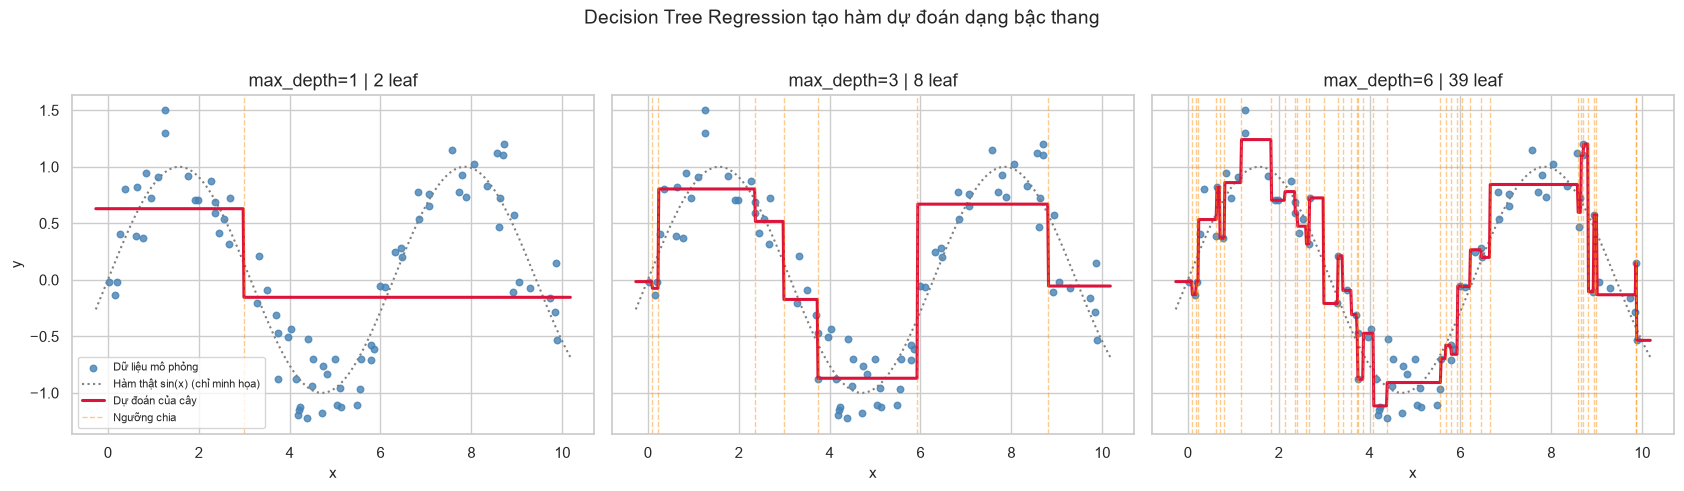

In [28]:
def collect_thresholds(tree, feature_index=0):
    """Các ngưỡng của mọi node chia theo một đặc trưng, theo thứ tự tăng dần."""
    return sorted(n.threshold for n in tree.iter_nodes() if not n.is_leaf and n.feature_index == feature_index)


x_grid = np.linspace(x_toy.min() - 0.3, x_toy.max() + 0.3, 600).reshape(-1, 1)
demo_depths = [1, 3, 6]

fig, axes = plt.subplots(1, len(demo_depths), figsize=(17, 4.8), sharey=True)
for ax, depth in zip(axes, demo_depths):
    tree_d = ScratchDecisionTreeRegressor(max_depth=depth).fit(X_toy, y_toy)
    ax.scatter(x_toy, y_toy, s=22, color="steelblue", alpha=0.8, label="Dữ liệu mô phỏng")
    ax.plot(x_grid, np.sin(x_grid), color="gray", linestyle=":", linewidth=1.5, label="Hàm thật sin(x) (chỉ minh họa)")
    ax.plot(x_grid, tree_d.predict(x_grid), color="crimson", linewidth=2.2, label="Dự đoán của cây")
    for i, threshold in enumerate(collect_thresholds(tree_d)):
        ax.axvline(threshold, color="darkorange", linestyle="--", alpha=0.45, linewidth=1,
                   label="Ngưỡng chia" if i == 0 else None)
    ax.set_title(f"max_depth={depth} | {tree_d.get_n_leaves()} leaf")
    ax.set_xlabel("x")
axes[0].set_ylabel("y")
axes[0].legend(loc="lower left", fontsize=8)
fig.suptitle("Decision Tree Regression tạo hàm dự đoán dạng bậc thang", y=1.02, fontsize=14)
fig.tight_layout()
save_figure(fig, "08_staircase_prediction.png")
plt.show()

## 8.3. Vẽ cây từ cấu trúc node của chính Scratch Tree

Hàm `plot_scratch_tree` bên dưới dựng hình **trực tiếp từ các `TreeNode` do ta tạo ra** (không dùng `sklearn.tree.plot_tree`, vốn chỉ dành cho mô hình Scikit-learn). Mỗi hộp ghi điều kiện chia, `n`, `mse`, `value`; leaf được tô màu khác.

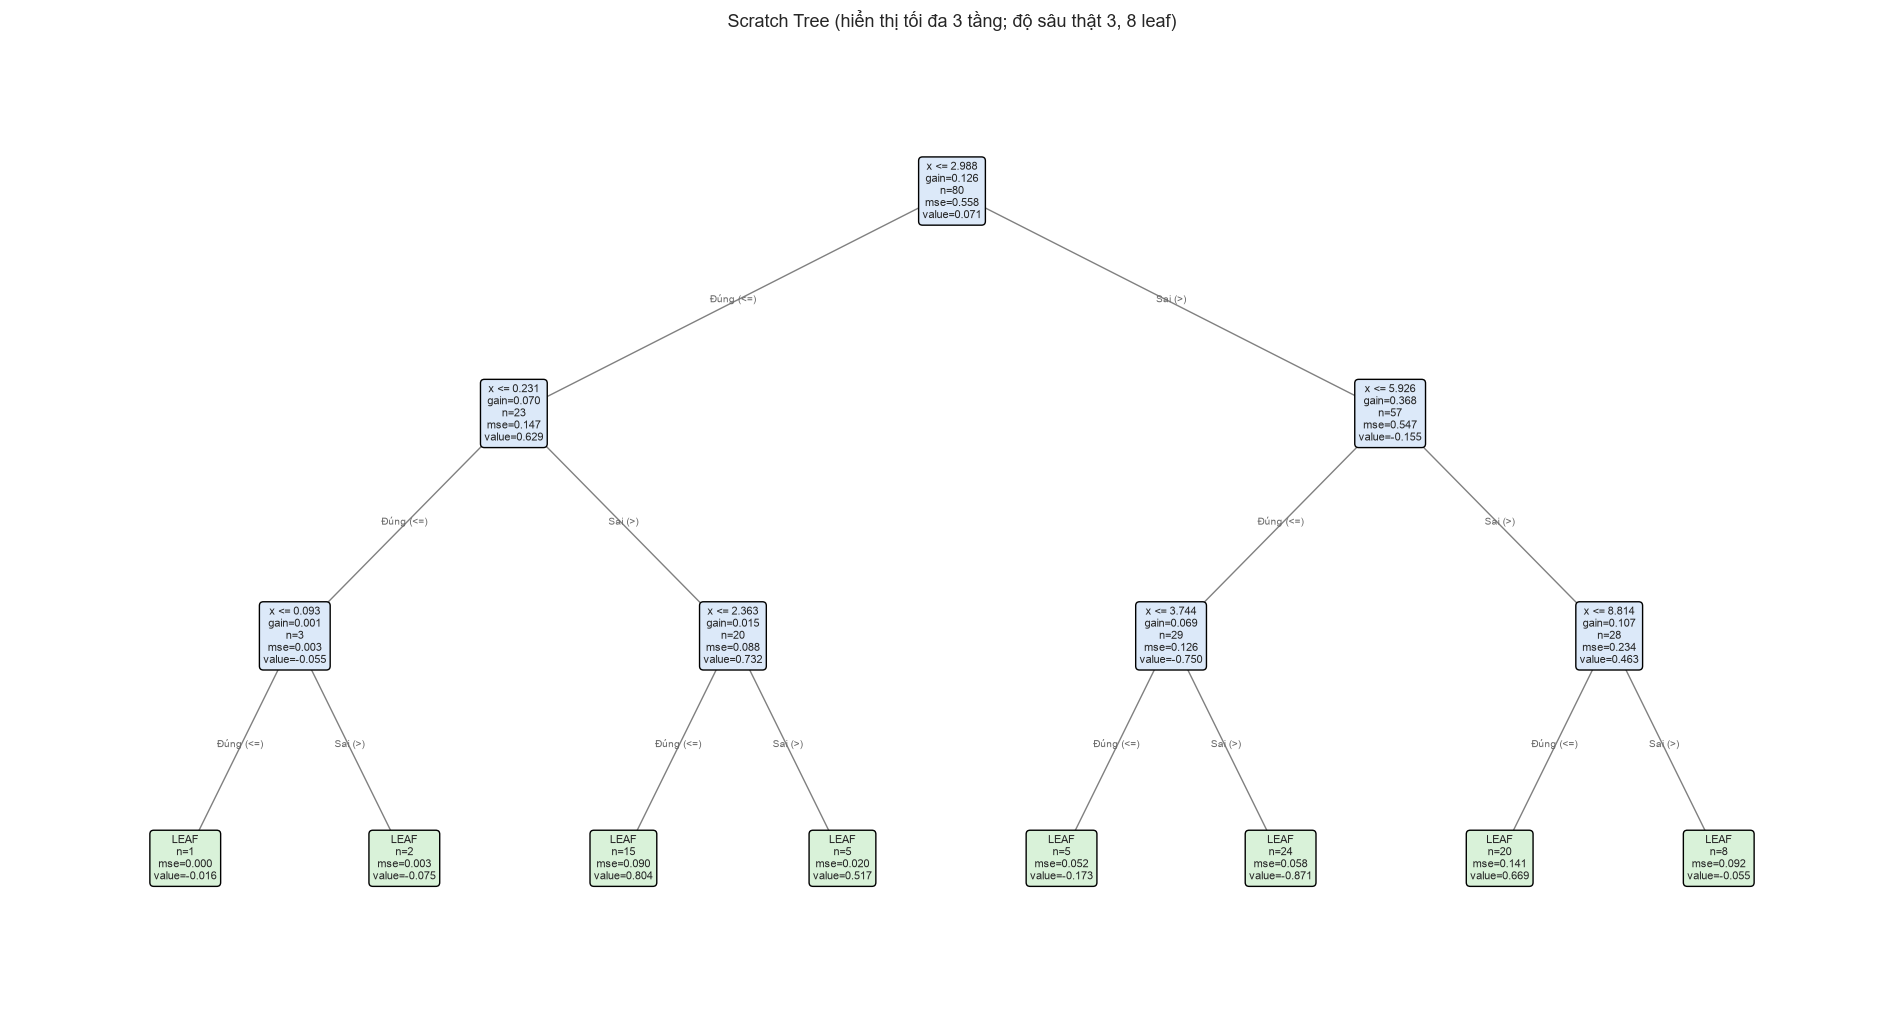

In [29]:
def plot_scratch_tree(tree, feature_names=None, max_display_depth=3, ax=None, decimals=3, fontsize=8):
    """Vẽ phần trên của Scratch Tree (đến độ sâu max_display_depth) bằng Matplotlib."""
    tree._check_fitted()
    own_figure = ax is None
    if own_figure:
        n_leaves_shown = 2 ** max_display_depth
        fig_, ax = plt.subplots(figsize=(max(10, 2.4 * n_leaves_shown), 2.6 * (max_display_depth + 1)))
    else:
        fig_ = ax.figure

    positions = {}      # node_id -> (x, depth)
    shown = []          # các node được hiển thị theo thứ tự trái -> phải
    leaf_counter = [0]

    def layout(node):
        """Gán tọa độ x: leaf (hoặc node bị cắt) nhận chỉ số liên tiếp, node trong là trung bình hai con."""
        truncated = (not node.is_leaf) and node.depth >= max_display_depth
        if node.is_leaf or truncated:
            x_pos = float(leaf_counter[0])
            leaf_counter[0] += 1
        else:
            x_left, x_right = layout(node.left), layout(node.right)
            x_pos = (x_left + x_right) / 2.0
        positions[node.node_id] = (x_pos, node.depth)
        shown.append(node)
        return x_pos

    layout(tree.root_)

    for node in shown:
        truncated = (not node.is_leaf) and node.depth >= max_display_depth
        if node.is_leaf or truncated:
            continue
        for child, label in ((node.left, "Đúng (<=)"), (node.right, "Sai (>)")):
            x0, d0 = positions[node.node_id]
            x1, d1 = positions[child.node_id]
            ax.plot([x0, x1], [-d0, -d1], color="gray", linewidth=1, zorder=1)
            ax.text((x0 + x1) / 2, -(d0 + d1) / 2, label, fontsize=fontsize - 1, color="dimgray", ha="center")

    for node in shown:
        x_pos, depth = positions[node.node_id]
        truncated = (not node.is_leaf) and node.depth >= max_display_depth
        stats = f"n={node.n_samples}\nmse={node.impurity:.{decimals}f}\nvalue={node.value:.{decimals}f}"
        if node.is_leaf:
            text, color = f"LEAF\n{stats}", "#d9f2d9"
        elif truncated:
            text, color = f"(còn node con)\n{stats}", "#eeeeee"
        else:
            name = tree._name_of(node.feature_index, feature_names)
            text, color = f"{name} <= {node.threshold:.{decimals}f}\ngain={node.gain:.{decimals}f}\n{stats}", "#dce9f9"
        ax.text(x_pos, -depth, text, ha="center", va="center", fontsize=fontsize, zorder=2,
                bbox={"boxstyle": "round,pad=0.35", "facecolor": color, "edgecolor": "black"})

    ax.set_xlim(-0.8, max(leaf_counter[0] - 1, 0) + 0.8)
    ax.set_ylim(-max_display_depth - 0.7, 0.7)
    ax.axis("off")
    ax.set_title(f"Scratch Tree (hiển thị tối đa {max_display_depth} tầng; "
                 f"độ sâu thật {tree.get_depth()}, {tree.get_n_leaves()} leaf)")
    return fig_, ax


fig, ax = plot_scratch_tree(toy_tree, feature_names=["x"], max_display_depth=3)
fig.tight_layout()
save_figure(fig, "08_scratch_tree_structure.png")
plt.show()
SECTION_STATUS["08"] = "hoàn thành"

<a id="part-09"></a>
# PHẦN 09 — Baseline và đánh giá mô hình

## 9.1. Các mô hình và quy tắc đánh giá

| Mô hình | Vai trò |
|---|---|
| `DummyRegressor(strategy="mean")` | Mức sàn: luôn dự đoán trung bình của **tập train** |
| `LinearRegression` | Tham chiếu **không phải cây**; giả định quan hệ tuyến tính, nhạy với ngoại lai. Dùng trực tiếp đặc trưng số (không scale vì không cần cho OLS thuần) |
| `ScratchDecisionTreeRegressor` (cấu hình tham chiếu) | Cây tự cài đặt |
| `DecisionTreeRegressor` (cùng cấu hình tham chiếu) | Cây chuẩn của Scikit-learn, `random_state=42` |
| `DecisionTreeRegressor(max_depth=None)` | Cây không giới hạn — để thấy rõ overfitting |

**Về cấu hình tham chiếu:** `max_depth=8, min_samples_split=2, min_samples_leaf=1, min_impurity_decrease=0` được **định trước ở cell cấu hình**, *không* được chọn bằng test. Việc chọn cấu hình tốt nhất bằng cross-validation nằm ở Phần 10, và mô hình đã chọn cũng được đánh giá trên test đúng một lần ở cuối phần đó.

Tất cả mô hình dùng **cùng** `X_train/X_test`. Cây không cần scale đặc trưng. Mọi metric tính bằng `sklearn.metrics`; mỗi mô hình chỉ chạm nhãn test một lần (qua `TEST_LEDGER`).

**Về thời gian:** thời gian fit/predict là **trung vị của `TIMING_REPEATS` lần đo** trên cùng máy, cùng dữ liệu. Đây chỉ là số đo tham khảo trong môi trường hiện tại; đừng suy rộng thành kết luận về tốc độ thuật toán nói chung (cây tự cài đặt là Python/NumPy thuần còn Scikit-learn dùng Cython, nên chênh lệch lớn là điều dễ hiểu và không nói gì về độ đúng).

In [30]:
def depth_of(model):
    """Độ sâu cây (None nếu mô hình không phải cây)."""
    return model.get_depth() if hasattr(model, "get_depth") else None


def leaves_of(model):
    return model.get_n_leaves() if hasattr(model, "get_n_leaves") else None


def fit_and_time(model_factory, X_fit, y_fit, X_eval, n_repeats=TIMING_REPEATS):
    """Fit nhiều lần (mô hình mới mỗi lần), trả về mô hình cuối cùng và trung vị thời gian fit/predict."""
    fit_times, predict_times, model = [], [], None
    for _ in range(max(1, n_repeats)):
        model = model_factory()
        start = time.perf_counter()
        model.fit(X_fit, y_fit)
        fit_times.append(time.perf_counter() - start)
        start = time.perf_counter()
        model.predict(X_eval)
        predict_times.append(time.perf_counter() - start)
    return model, float(np.median(fit_times)), float(np.median(predict_times))


MODEL_SPECS = {
    "dummy_mean": {
        "family": "baseline", "params": {"strategy": "mean"},
        "factory": lambda: DummyRegressor(strategy="mean"),
    },
    "linear_regression": {
        "family": "linear", "params": {},
        "factory": lambda: LinearRegression(),
    },
    "scratch_tree_reference": {
        "family": "tree_scratch", "params": dict(REFERENCE_TREE_PARAMS),
        "factory": lambda: ScratchDecisionTreeRegressor(**REFERENCE_TREE_PARAMS),
    },
    "sklearn_tree_reference": {
        "family": "tree_sklearn", "params": {**REFERENCE_TREE_PARAMS, "random_state": RANDOM_STATE},
        "factory": lambda: DecisionTreeRegressor(**REFERENCE_TREE_PARAMS, random_state=RANDOM_STATE),
    },
    "sklearn_tree_unrestricted": {
        "family": "tree_sklearn", "params": {"max_depth": None, "random_state": RANDOM_STATE},
        "factory": lambda: DecisionTreeRegressor(max_depth=None, random_state=RANDOM_STATE),
    },
}

FITTED_MODELS = {}      # tên -> mô hình đã fit trên toàn bộ train
BASELINE_RECORDS = []   # mỗi phần tử là một dòng của bảng baseline_metrics


def evaluate_model_on_test(name, factory, family, params, purpose):
    """Fit trên train, đo thời gian, đánh giá train (tham khảo) và test (đúng một lần)."""
    model, fit_time, predict_time = fit_and_time(factory, X_train, y_train, X_test)
    train_metrics = regression_metrics(y_train, model.predict(X_train))
    test_metrics = TEST_LEDGER.evaluate(name, model.predict(X_test), purpose)
    FITTED_MODELS[name] = model
    record = {
        "model": name, "family": family, "params": json.dumps(params, sort_keys=True),
        "rmse": test_metrics["rmse"], "mae": test_metrics["mae"], "mse": test_metrics["mse"], "r2": test_metrics["r2"],
        "train_rmse": train_metrics["rmse"], "train_r2": train_metrics["r2"],
        "fit_time_s": fit_time, "predict_time_s": predict_time,
        "depth": depth_of(model), "n_leaves": leaves_of(model),
        "evaluated_on": "test", "purpose": purpose,
    }
    BASELINE_RECORDS.append(record)
    return record


for model_name, spec in MODEL_SPECS.items():
    record = evaluate_model_on_test(model_name, spec["factory"], spec["family"], spec["params"],
                                    purpose="cấu hình định trước (không chọn theo test)")
    print(f"{model_name:<28} RMSE={record['rmse']:.4f}  fit={record['fit_time_s']:.3f}s  depth={record['depth']}  leaves={record['n_leaves']}")

dummy_mean                   RMSE=1.7288  fit=0.001s  depth=None  leaves=None
linear_regression            RMSE=0.8390  fit=0.004s  depth=None  leaves=None


scratch_tree_reference       RMSE=0.8434  fit=0.099s  depth=8  leaves=134
sklearn_tree_reference       RMSE=0.7987  fit=0.004s  depth=8  leaves=138
sklearn_tree_unrestricted    RMSE=0.9335  fit=0.005s  depth=18  leaves=513


## 9.2. Bảng kết quả (sắp theo RMSE tăng dần)

Cột `rmse`, `mae`, `mse`, `r2` là **trên test**; `train_rmse`, `train_r2` là trên train, đặt cạnh để thấy khoảng cách train–test (*generalization gap*). Bảng được sinh hoàn toàn từ các lần chạy ở trên.

,model,rmse,mae,mse,r2,train_rmse,train_r2,fit_time_s,predict_time_s,depth,n_leaves
0,sklearn_tree_reference,0.7987,0.4965,0.6379,0.7863,0.5397,0.8882,0.0042,0.0012,8.0000,138.0000
1,linear_regression,0.8390,0.6516,0.7039,0.7642,0.8190,0.7425,0.0041,0.0013,NaN,NaN
2,scratch_tree_reference,0.8434,0.5096,0.7114,0.7617,0.5397,0.8882,0.0994,0.0010,8.0000,134.0000
3,sklearn_tree_unrestricted,0.9335,0.5154,0.8714,0.7081,0.1091,0.9954,0.0051,0.0012,18.0000,513.0000
4,dummy_mean,1.7288,1.4352,2.9889,-0.0011,1.6138,0.0000,0.0007,0.0001,NaN,NaN


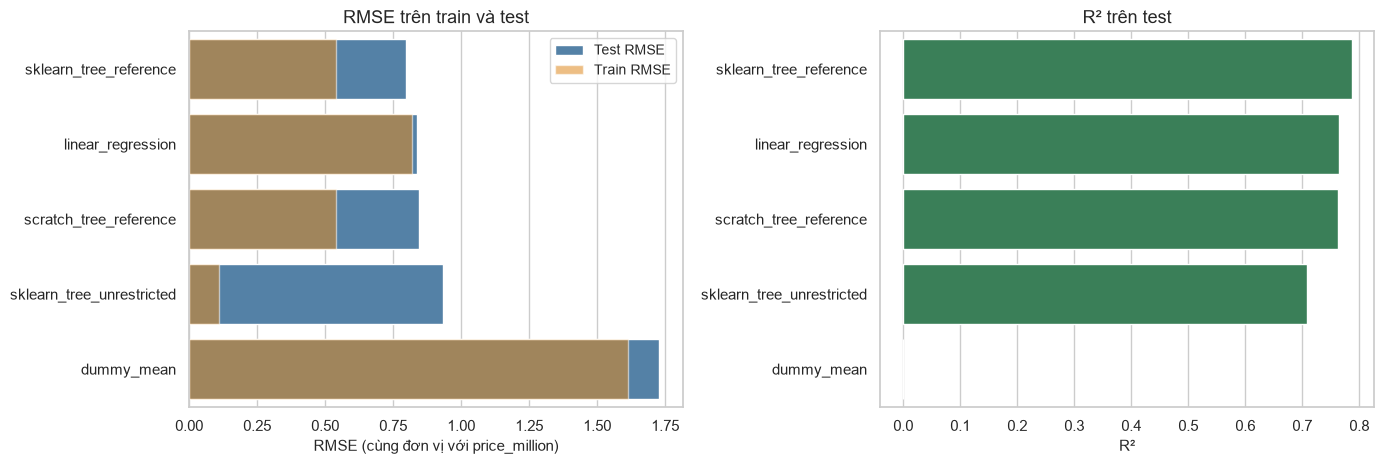

**Ghi chú tự động từ bảng trên** (chưa phải kết luận; xem Phần 15):

- `sklearn_tree_reference`: RMSE 0.7987, thấp hơn mức sàn Dummy 53.8%.
- `linear_regression`: RMSE 0.8390, thấp hơn mức sàn Dummy 51.5%.
- `scratch_tree_reference`: RMSE 0.8434, thấp hơn mức sàn Dummy 51.2%.
- `sklearn_tree_unrestricted`: RMSE 0.9335, thấp hơn mức sàn Dummy 46.0%.
- Hạng theo RMSE trên test: sklearn_tree_reference < linear_regression < scratch_tree_reference < sklearn_tree_unrestricted < dummy_mean.

In [31]:
def baseline_table() -> pd.DataFrame:
    columns = ["model", "rmse", "mae", "mse", "r2", "train_rmse", "train_r2",
               "fit_time_s", "predict_time_s", "depth", "n_leaves"]
    return (pd.DataFrame(BASELINE_RECORDS)[columns]
            .sort_values("rmse", ascending=True).reset_index(drop=True))


baseline_df = baseline_table()
display(baseline_df)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
order = baseline_df["model"].tolist()
sns.barplot(data=baseline_df, y="model", x="rmse", order=order, color="steelblue", ax=axes[0], label="Test RMSE")
sns.barplot(data=baseline_df, y="model", x="train_rmse", order=order, color="darkorange", alpha=0.55, ax=axes[0], label="Train RMSE")
axes[0].set_title("RMSE trên train và test")
axes[0].set_xlabel(f"RMSE (cùng đơn vị với {TARGET_COLUMN})")
axes[0].set_ylabel("")
axes[0].legend()

sns.barplot(data=baseline_df, y="model", x="r2", order=order, color="seagreen", ax=axes[1])
axes[1].set_title("R² trên test")
axes[1].set_xlabel("R²")
axes[1].set_ylabel("")
fig.tight_layout()
save_figure(fig, "09_baseline_metrics.png")
plt.show()

# Ghi chú tự động (số liệu lấy từ bảng trên) - kết luận đầy đủ nằm ở Phần 15
rmse_by_model = baseline_df.set_index("model")["rmse"]
dummy_rmse = rmse_by_model["dummy_mean"]
lines = ["**Ghi chú tự động từ bảng trên** (chưa phải kết luận; xem Phần 15):\n"]
for name, value in rmse_by_model.items():
    if name != "dummy_mean":
        lines.append(f"- `{name}`: RMSE {value:.4f}, thấp hơn mức sàn Dummy {(1 - value / dummy_rmse):.1%}.")
lines.append(f"- Hạng theo RMSE trên test: " + " < ".join(rmse_by_model.index) + ".")
show_md("\n".join(lines))
SECTION_STATUS["09"] = "hoàn thành"

<a id="part-10"></a>
# PHẦN 10 — Cross-validation và chọn độ phức tạp cây

## 10.1. Thiết kế

- **Lưới:** `max_depth` ∈ {2, 3, 5, 8, 12, 16, None} × `min_samples_leaf` ∈ {1, 5, 20} (đặt ở cell cấu hình). `min_samples_leaf` là một dạng *regularization*: bắt mỗi leaf phải đủ mẫu nên cây không thể "học thuộc" từng điểm.
- **Dữ liệu:** chỉ tập **train**; 5 fold đã cố định ở Phần 04 (`CV_FOLD_INDICES`) — *mọi cấu hình dùng đúng cùng các fold*.
- **Mỗi fold:** khởi tạo mô hình **mới**, fit **chỉ** trên phần train của fold, đo trên phần validation của fold.
- **Báo cáo:** RMSE validation trung bình và độ lệch chuẩn giữa các fold (mẫu, `ddof=1`), MAE, R², RMSE train (trong fold), thời gian fit.
- **Quy tắc chọn:** cấu hình có RMSE validation trung bình nhỏ nhất (đồng hạng → ít leaf hơn). Ta cũng in cấu hình *đơn giản nhất nằm trong 1 sai số chuẩn* (one-standard-error rule) như một lựa chọn thay thế để tham khảo; quyết định cuối cùng dùng quy tắc "RMSE nhỏ nhất".
- Tập test **không** xuất hiện trong phần chọn tham số.

In [32]:
def depth_label(depth) -> str:
    return "None" if depth is None else str(int(depth))


def cross_validate_config(model_factory, X_data, y_data, fold_indices) -> pd.DataFrame:
    """CV thủ công: mỗi fold dùng mô hình MỚI, chỉ fit trên phần train của fold. Trả về một dòng mỗi fold."""
    rows = []
    for fold_id, (train_idx, valid_idx) in enumerate(fold_indices):
        X_tr, X_va = X_data.iloc[train_idx], X_data.iloc[valid_idx]
        y_tr, y_va = y_data.iloc[train_idx], y_data.iloc[valid_idx]
        model = model_factory()
        start = time.perf_counter()
        model.fit(X_tr, y_tr)
        fit_time = time.perf_counter() - start
        train_metrics = regression_metrics(y_tr, model.predict(X_tr))
        valid_metrics = regression_metrics(y_va, model.predict(X_va))
        rows.append({
            "fold": fold_id,
            "train_rmse": train_metrics["rmse"],
            "val_rmse": valid_metrics["rmse"], "val_mae": valid_metrics["mae"], "val_r2": valid_metrics["r2"],
            "fit_time_s": fit_time, "depth": model.get_depth(), "n_leaves": model.get_n_leaves(),
        })
    return pd.DataFrame(rows)


def summarize_folds(fold_df: pd.DataFrame, depth, min_leaf) -> dict:
    n_folds = len(fold_df)
    std_val = float(fold_df["val_rmse"].std(ddof=1))
    return {
        "max_depth": np.nan if depth is None else float(depth),
        "max_depth_label": depth_label(depth),
        "min_samples_leaf": int(min_leaf),
        "mean_val_rmse": float(fold_df["val_rmse"].mean()),
        "std_val_rmse": std_val,
        "se_val_rmse": std_val / np.sqrt(n_folds),
        "mean_val_mae": float(fold_df["val_mae"].mean()),
        "mean_val_r2": float(fold_df["val_r2"].mean()),
        "mean_train_rmse": float(fold_df["train_rmse"].mean()),
        "std_train_rmse": float(fold_df["train_rmse"].std(ddof=1)),
        "mean_fit_time_s": float(fold_df["fit_time_s"].mean()),
        "mean_depth": float(fold_df["depth"].mean()),
        "mean_n_leaves": float(fold_df["n_leaves"].mean()),
    }


cv_summary_rows = []
cv_start = time.perf_counter()
for min_leaf in MIN_SAMPLES_LEAF_GRID:
    for depth in DEPTH_GRID:
        factory = lambda d=depth, m=min_leaf: DecisionTreeRegressor(max_depth=d, min_samples_leaf=m, random_state=RANDOM_STATE)
        fold_results = cross_validate_config(factory, X_train, y_train, CV_FOLD_INDICES)
        cv_summary_rows.append(summarize_folds(fold_results, depth, min_leaf))
cv_results_df = pd.DataFrame(cv_summary_rows)
print(f"Đã chạy {len(cv_results_df)} cấu hình x {CV_FOLDS} fold trong {time.perf_counter() - cv_start:.1f}s")
display(cv_results_df.sort_values(["mean_val_rmse", "mean_n_leaves"]).reset_index(drop=True))

Đã chạy 21 cấu hình x 5 fold trong 0.6s


,max_depth,max_depth_label,min_samples_leaf,mean_val_rmse,std_val_rmse,se_val_rmse,mean_val_mae,mean_val_r2,mean_train_rmse,std_train_rmse,mean_fit_time_s,mean_depth,mean_n_leaves
0,8.0000,8,5,0.8416,0.1280,0.0573,0.5395,0.7260,0.6728,0.0208,0.0022,8.0000,69.8000
1,16.0000,16,5,0.8513,0.1232,0.0551,0.5192,0.7195,0.6179,0.0245,0.0023,12.4000,97.2000
2,NaN,None,5,0.8513,0.1232,0.0551,0.5192,0.7195,0.6179,0.0245,0.0020,12.4000,97.2000
3,12.0000,12,5,0.8519,0.1228,0.0549,0.5187,0.7190,0.6189,0.0243,0.0020,11.8000,96.2000
4,5.0000,5,5,0.9035,0.0942,0.0421,0.6141,0.6851,0.8236,0.0161,0.0016,5.0000,25.0000
5,8.0000,8,1,0.9202,0.1389,0.0621,0.5388,0.6716,0.5169,0.0242,0.0022,8.0000,128.4000
6,8.0000,8,20,0.9559,0.0525,0.0235,0.6419,0.6464,0.8969,0.0099,0.0016,7.6000,22.0000
7,12.0000,12,20,0.9559,0.0525,0.0235,0.6419,0.6464,0.8969,0.0099,0.0016,7.6000,22.0000
8,16.0000,16,20,0.9559,0.0525,0.0235,0.6419,0.6464,0.8969,0.0099,0.0016,7.6000,22.0000
9,NaN,None,20,0.9559,0.0525,0.0235,0.6419,0.6464,0.8969,0.0099,0.0016,7.6000,22.0000


## 10.2. Chọn cấu hình bằng cross-validation

Cấu hình được chọn (RMSE validation trung bình nhỏ nhất):
  {'max_depth': 8, 'min_samples_split': 2, 'min_samples_leaf': 5, 'min_impurity_decrease': 0.0}
  RMSE CV = 0.8416 ± 0.1280 (độ lệch chuẩn giữa 5 fold), R² CV = 0.7260, ~70 leaf

Cấu hình đơn giản nhất nằm trong 1 sai số chuẩn (tham khảo):
  {'max_depth': 8, 'min_samples_split': 2, 'min_samples_leaf': 5, 'min_impurity_decrease': 0.0} | RMSE CV = 0.8416 | ~70 leaf


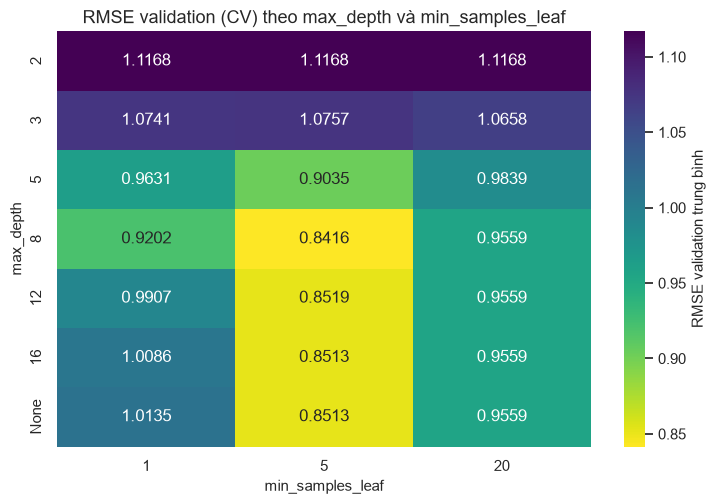

In [33]:
ranked = cv_results_df.sort_values(["mean_val_rmse", "mean_n_leaves"]).reset_index(drop=True)
best_row = ranked.iloc[0]
one_se_limit = best_row["mean_val_rmse"] + best_row["se_val_rmse"]
one_se_row = (cv_results_df[cv_results_df["mean_val_rmse"] <= one_se_limit]
              .sort_values(["mean_n_leaves", "mean_val_rmse"]).iloc[0])


def row_to_tree_params(row) -> dict:
    return {
        "max_depth": None if np.isnan(row["max_depth"]) else int(row["max_depth"]),
        "min_samples_split": 2,
        "min_samples_leaf": int(row["min_samples_leaf"]),
        "min_impurity_decrease": 0.0,
    }


SELECTED_TREE_PARAMS = row_to_tree_params(best_row)
ONE_SE_TREE_PARAMS = row_to_tree_params(one_se_row)

print("Cấu hình được chọn (RMSE validation trung bình nhỏ nhất):")
print(f"  {SELECTED_TREE_PARAMS}")
print(f"  RMSE CV = {best_row['mean_val_rmse']:.4f} ± {best_row['std_val_rmse']:.4f} (độ lệch chuẩn giữa {CV_FOLDS} fold), "
      f"R² CV = {best_row['mean_val_r2']:.4f}, ~{best_row['mean_n_leaves']:.0f} leaf")
print("\nCấu hình đơn giản nhất nằm trong 1 sai số chuẩn (tham khảo):")
print(f"  {ONE_SE_TREE_PARAMS} | RMSE CV = {one_se_row['mean_val_rmse']:.4f} | ~{one_se_row['mean_n_leaves']:.0f} leaf")

pivot_val = cv_results_df.pivot(index="max_depth_label", columns="min_samples_leaf", values="mean_val_rmse")
pivot_val = pivot_val.loc[[depth_label(d) for d in DEPTH_GRID]]
fig, ax = plt.subplots(figsize=(7.5, 5.2))
sns.heatmap(pivot_val, annot=True, fmt=".4f", cmap="viridis_r", cbar_kws={"label": "RMSE validation trung bình"}, ax=ax)
ax.set_title("RMSE validation (CV) theo max_depth và min_samples_leaf")
ax.set_xlabel("min_samples_leaf")
ax.set_ylabel("max_depth")
fig.tight_layout()
save_figure(fig, "10_cv_heatmap.png")
plt.show()

## 10.3. Biểu đồ theo độ sâu

Bốn biểu đồ (mỗi đường là một giá trị `min_samples_leaf`), **không dùng tập test**:

1. RMSE **train** (trong fold) theo độ sâu.
2. RMSE **validation** theo độ sâu; thanh sai số là ±1 độ lệch chuẩn giữa các fold.
3. **Độ biến thiên** của RMSE validation (độ lệch chuẩn giữa fold) theo độ sâu.
4. **Số leaf** trung bình theo độ sâu (trục log).

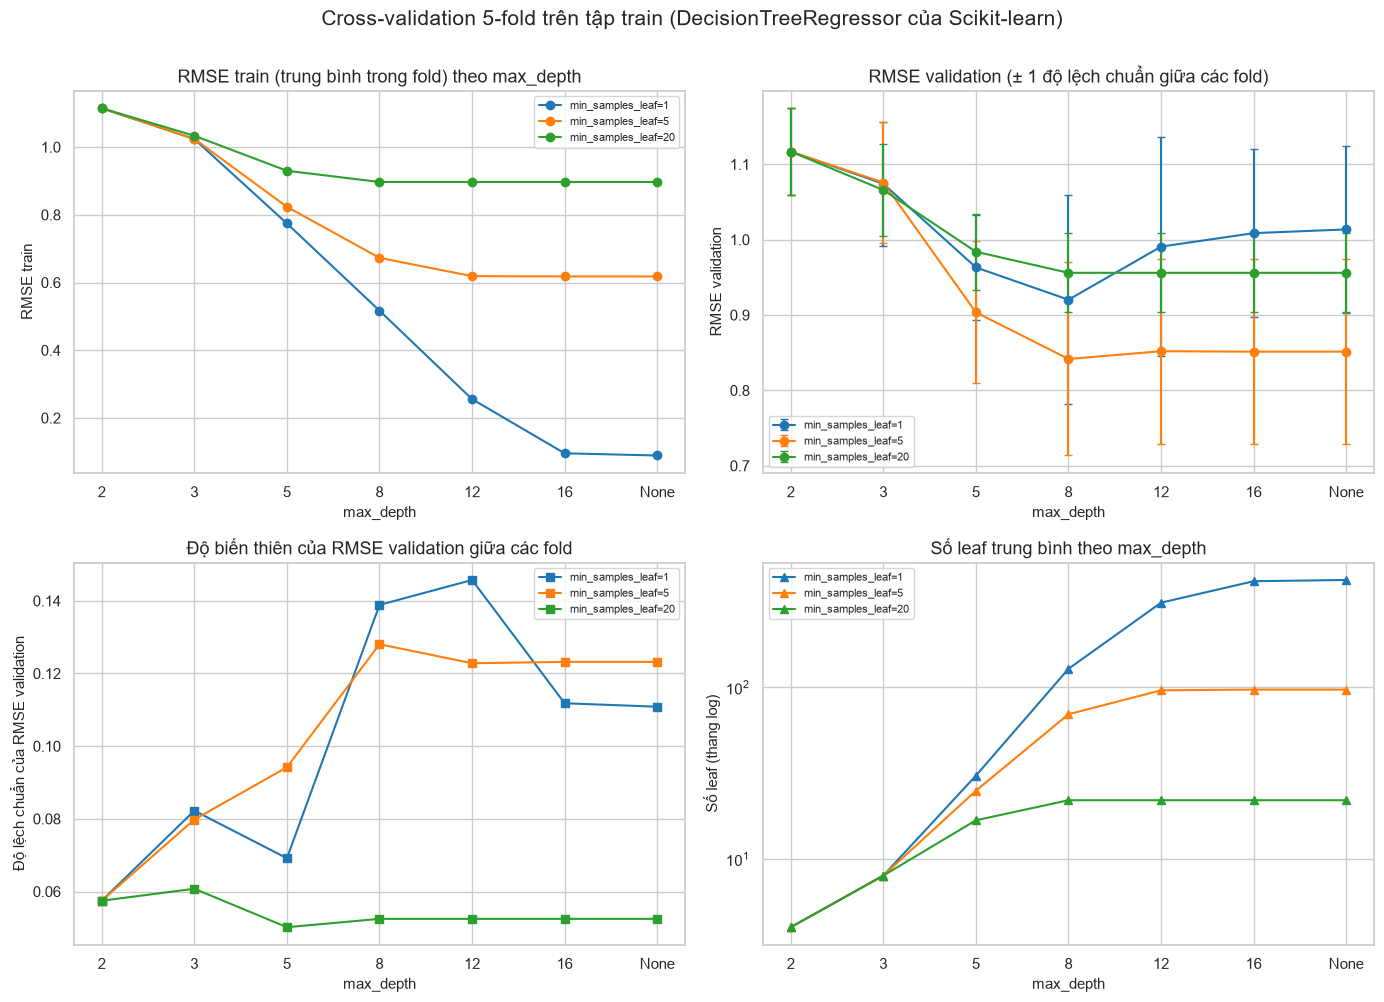

In [34]:
depth_positions = np.arange(len(DEPTH_GRID))
depth_tick_labels = [depth_label(d) for d in DEPTH_GRID]
palette = sns.color_palette("tab10", n_colors=len(MIN_SAMPLES_LEAF_GRID))

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for color, min_leaf in zip(palette, MIN_SAMPLES_LEAF_GRID):
    subset = cv_results_df[cv_results_df["min_samples_leaf"] == min_leaf].set_index("max_depth_label").loc[depth_tick_labels]
    label = f"min_samples_leaf={min_leaf}"
    axes[0, 0].plot(depth_positions, subset["mean_train_rmse"], marker="o", color=color, label=label)
    axes[0, 1].errorbar(depth_positions, subset["mean_val_rmse"], yerr=subset["std_val_rmse"], marker="o",
                        capsize=3, color=color, label=label)
    axes[1, 0].plot(depth_positions, subset["std_val_rmse"], marker="s", color=color, label=label)
    axes[1, 1].plot(depth_positions, subset["mean_n_leaves"], marker="^", color=color, label=label)

axes[0, 0].set_title("RMSE train (trung bình trong fold) theo max_depth")
axes[0, 0].set_ylabel("RMSE train")
axes[0, 1].set_title("RMSE validation (± 1 độ lệch chuẩn giữa các fold)")
axes[0, 1].set_ylabel("RMSE validation")
axes[1, 0].set_title("Độ biến thiên của RMSE validation giữa các fold")
axes[1, 0].set_ylabel("Độ lệch chuẩn của RMSE validation")
axes[1, 1].set_title("Số leaf trung bình theo max_depth")
axes[1, 1].set_ylabel("Số leaf (thang log)")
axes[1, 1].set_yscale("log")
for ax in axes.ravel():
    ax.set_xticks(depth_positions)
    ax.set_xticklabels(depth_tick_labels)
    ax.set_xlabel("max_depth")
    ax.legend(fontsize=8)
fig.suptitle("Cross-validation 5-fold trên tập train (DecisionTreeRegressor của Scikit-learn)", y=1.0, fontsize=15)
fig.tight_layout()
save_figure(fig, "10_cv_by_depth.png")
plt.show()

## 10.4. Cross-validation cho cây tự cài đặt

Cây tự cài đặt (Python/NumPy thuần) chậm hơn Scikit-learn nên ta chỉ chạy CV cho một tập con độ sâu (`SCRATCH_CV_DEPTHS`, với `min_samples_leaf=1`) **cộng thêm** cấu hình đã chọn ở trên. Đặt `RUN_SCRATCH_CV = False` ở cell cấu hình để bỏ qua. Mục đích: kiểm tra trên *dữ liệu thật và đúng cùng các fold* rằng hai cài đặt cho RMSE validation gần như trùng nhau.

In [35]:
scratch_cv_comparison_df = None
if RUN_SCRATCH_CV:
    scratch_configs = [(d, 1) for d in SCRATCH_CV_DEPTHS]
    selected_key = (SELECTED_TREE_PARAMS["max_depth"], SELECTED_TREE_PARAMS["min_samples_leaf"])
    if selected_key not in scratch_configs:
        scratch_configs.append(selected_key)

    scratch_rows = []
    scratch_cv_start = time.perf_counter()
    for depth, min_leaf in scratch_configs:
        factory = lambda d=depth, m=min_leaf: ScratchDecisionTreeRegressor(max_depth=d, min_samples_leaf=m)
        fold_results = cross_validate_config(factory, X_train, y_train, CV_FOLD_INDICES)
        scratch_rows.append(summarize_folds(fold_results, depth, min_leaf))
        print(f"  scratch max_depth={depth_label(depth):>4} min_samples_leaf={min_leaf:>2} xong "
              f"(tích lũy {time.perf_counter() - scratch_cv_start:.0f}s)")
    scratch_cv_df = pd.DataFrame(scratch_rows)

    sk_cols = cv_results_df[["max_depth_label", "min_samples_leaf", "mean_val_rmse", "std_val_rmse",
                             "mean_n_leaves", "mean_fit_time_s"]].add_prefix("sk_")
    sc_cols = scratch_cv_df[["max_depth_label", "min_samples_leaf", "mean_val_rmse", "std_val_rmse",
                             "mean_n_leaves", "mean_fit_time_s"]].add_prefix("scratch_")
    scratch_cv_comparison_df = sc_cols.merge(
        sk_cols, left_on=["scratch_max_depth_label", "scratch_min_samples_leaf"],
        right_on=["sk_max_depth_label", "sk_min_samples_leaf"], how="left",
    ).drop(columns=["sk_max_depth_label", "sk_min_samples_leaf"]).rename(
        columns={"scratch_max_depth_label": "max_depth", "scratch_min_samples_leaf": "min_samples_leaf"})
    scratch_cv_comparison_df["abs_diff_val_rmse"] = (scratch_cv_comparison_df["scratch_mean_val_rmse"]
                                                     - scratch_cv_comparison_df["sk_mean_val_rmse"]).abs()
    display(scratch_cv_comparison_df)
else:
    print("RUN_SCRATCH_CV=False: bỏ qua cross-validation cho cây tự cài đặt.")

  scratch max_depth=   2 min_samples_leaf= 1 xong (tích lũy 0s)
  scratch max_depth=   3 min_samples_leaf= 1 xong (tích lũy 0s)
  scratch max_depth=   5 min_samples_leaf= 1 xong (tích lũy 0s)


  scratch max_depth=   8 min_samples_leaf= 1 xong (tích lũy 1s)


  scratch max_depth=  12 min_samples_leaf= 1 xong (tích lũy 1s)


  scratch max_depth=   8 min_samples_leaf= 5 xong (tích lũy 2s)


,max_depth,min_samples_leaf,scratch_mean_val_rmse,scratch_std_val_rmse,scratch_mean_n_leaves,scratch_mean_fit_time_s,sk_mean_val_rmse,sk_std_val_rmse,sk_mean_n_leaves,sk_mean_fit_time_s,abs_diff_val_rmse
0,2,1,1.1168,0.0575,4.0000,0.0032,1.1168,0.0575,4.0000,0.0014,0.0000
1,3,1,1.0741,0.0822,8.0000,0.0057,1.0741,0.0822,8.0000,0.0017,0.0000
2,5,1,0.9848,0.1038,30.6000,0.0196,0.9631,0.0692,30.6000,0.0018,0.0218
3,8,1,0.9397,0.1340,125.2000,0.0701,0.9202,0.1389,128.4000,0.0022,0.0194
4,12,1,1.0219,0.1400,297.2000,0.1432,0.9907,0.1457,312.0000,0.0026,0.0312
5,8,5,0.8420,0.1246,69.8000,0.0398,0.8416,0.1280,69.8000,0.0022,0.0004


## 10.5. Fit trên toàn bộ train và đánh giá test **một lần**

Sau khi cấu hình được chọn bằng CV, ta fit hai cây (Scikit-learn và tự cài đặt) với **cùng** tham số trên toàn bộ tập train và đánh giá trên test. `TEST_LEDGER` đảm bảo mỗi mô hình chỉ chạm nhãn test đúng một lần.

In [36]:
selected_purpose = "cấu hình chọn bởi cross-validation (đánh giá test một lần)"
sklearn_selected_params = {**SELECTED_TREE_PARAMS, "random_state": RANDOM_STATE}

evaluate_model_on_test(
    "sklearn_tree_cv_selected", lambda: DecisionTreeRegressor(**sklearn_selected_params),
    "tree_sklearn", sklearn_selected_params, purpose=selected_purpose)
evaluate_model_on_test(
    "scratch_tree_cv_selected", lambda: ScratchDecisionTreeRegressor(**SELECTED_TREE_PARAMS),
    "tree_scratch", SELECTED_TREE_PARAMS, purpose=selected_purpose)

baseline_df = baseline_table()
print("Bảng kết quả cuối cùng (test), sắp theo RMSE tăng dần:")
display(baseline_df)
print("\nSổ ghi sử dụng nhãn test cho đến lúc này:")
display(TEST_LEDGER.to_frame())
SECTION_STATUS["10"] = "hoàn thành"

Bảng kết quả cuối cùng (test), sắp theo RMSE tăng dần:


,model,rmse,mae,mse,r2,train_rmse,train_r2,fit_time_s,predict_time_s,depth,n_leaves
0,scratch_tree_cv_selected,0.7719,0.5198,0.5958,0.8004,0.6754,0.8248,0.0427,0.0005,8.0000,73.0000
1,sklearn_tree_cv_selected,0.7812,0.5267,0.6103,0.7956,0.6754,0.8248,0.0025,0.0008,8.0000,73.0000
2,sklearn_tree_reference,0.7987,0.4965,0.6379,0.7863,0.5397,0.8882,0.0042,0.0012,8.0000,138.0000
3,linear_regression,0.8390,0.6516,0.7039,0.7642,0.8190,0.7425,0.0041,0.0013,NaN,NaN
4,scratch_tree_reference,0.8434,0.5096,0.7114,0.7617,0.5397,0.8882,0.0994,0.0010,8.0000,134.0000
5,sklearn_tree_unrestricted,0.9335,0.5154,0.8714,0.7081,0.1091,0.9954,0.0051,0.0012,18.0000,513.0000
6,dummy_mean,1.7288,1.4352,2.9889,-0.0011,1.6138,0.0000,0.0007,0.0001,NaN,NaN



Sổ ghi sử dụng nhãn test cho đến lúc này:


,model,purpose
0,dummy_mean,cấu hình định trước (không chọn theo test)
1,linear_regression,cấu hình định trước (không chọn theo test)
2,scratch_tree_reference,cấu hình định trước (không chọn theo test)
3,sklearn_tree_reference,cấu hình định trước (không chọn theo test)
4,sklearn_tree_unrestricted,cấu hình định trước (không chọn theo test)
5,sklearn_tree_cv_selected,cấu hình chọn bởi cross-validation (đánh giá t...
6,scratch_tree_cv_selected,cấu hình chọn bởi cross-validation (đánh giá t...


<a id="part-11"></a>
# PHẦN 11 — Bias, variance và overfitting

## 11.1. Ba khái niệm cần phân biệt

1. **Chênh lệch train–validation/test (generalization gap).** Đo *hiện tượng* mô hình tốt hơn hẳn trên dữ liệu đã thấy. Đây là **dấu hiệu** của overfitting, **không phải** phép đo trực tiếp của variance.
2. **Bias–variance trade-off (lý thuyết).** Với một điểm $x$, kỳ vọng sai số bình phương *theo việc lấy ngẫu nhiên tập huấn luyện $D$*:
$$
\mathbb{E}_D\big[(\hat f_D(x)-y)^2\big]=\underbrace{\big(\bar f(x)-y\big)^2}_{\text{bias}^2\ (\text{+ nhiễu bất khả quy nếu } y=f(x)+\varepsilon)}+\underbrace{\mathbb{E}_D\big[(\hat f_D(x)-\bar f(x))^2\big]}_{\text{variance}},\qquad \bar f(x)=\mathbb{E}_D[\hat f_D(x)].
$$
   Cây nông: bias lớn, variance nhỏ (**underfit**). Cây sâu: bias nhỏ, variance lớn (**overfit**). Đây là mô hình lý thuyết; ta không quan sát trực tiếp $\bar f$.
3. **Ước lượng thực nghiệm của độ bất ổn.** Ta *xấp xỉ* việc "lấy nhiều tập huấn luyện" bằng cách huấn luyện lại trên nhiều **mẫu con** của tập train, rồi đo độ phân tán của dự đoán tại cùng các điểm. Đây là xấp xỉ có giới hạn (xem 11.3).

Những điều thường thấy (nhưng *kết quả cụ thể phụ thuộc dataset và cấu hình*, nên ta sẽ kiểm chứng bằng số liệu thay vì giả định): RMSE train không tăng khi cây sâu thêm (cây không pruning); RMSE validation có thể giảm rồi tăng.

## 11.2. Đường cong train error và validation error theo độ sâu

Dùng `min_samples_leaf=1` và lưới độ sâu mịn (`FINE_DEPTH_GRID`) cùng các fold CV cũ. `train_rmse_full_fit` là RMSE trên toàn bộ train của mô hình fit trên toàn bộ train; `cv_val_rmse` là RMSE validation trung bình qua CV. Phần này chỉ để **chẩn đoán**; cấu hình được chọn vẫn là kết quả ở Phần 10.

In [37]:
depth_rows = []
for depth in FINE_DEPTH_GRID:
    factory = lambda d=depth: DecisionTreeRegressor(max_depth=d, min_samples_leaf=1, random_state=RANDOM_STATE)
    fold_results = cross_validate_config(factory, X_train, y_train, CV_FOLD_INDICES)
    full_model = factory().fit(X_train, y_train)
    depth_rows.append({
        "max_depth": np.nan if depth is None else float(depth),
        "max_depth_label": depth_label(depth),
        "train_rmse_full_fit": regression_metrics(y_train, full_model.predict(X_train))["rmse"],
        "cv_train_rmse": float(fold_results["train_rmse"].mean()),
        "cv_val_rmse": float(fold_results["val_rmse"].mean()),
        "cv_val_rmse_std": float(fold_results["val_rmse"].std(ddof=1)),
        "n_leaves_full_fit": int(full_model.get_n_leaves()),
        "actual_depth_full_fit": int(full_model.get_depth()),
    })
depth_experiment_df = pd.DataFrame(depth_rows)
depth_experiment_df["gap_val_minus_train"] = depth_experiment_df["cv_val_rmse"] - depth_experiment_df["train_rmse_full_fit"]
depth_experiment_df["val_to_train_ratio"] = depth_experiment_df["cv_val_rmse"] / np.maximum(depth_experiment_df["train_rmse_full_fit"], 1e-12)

# Chẩn đoán heuristic (ngưỡng đặt tường minh, chỉ mang tính gợi ý)
OVERFIT_RATIO = 1.5          # val RMSE >= 1.5 x train RMSE -> dấu hiệu overfit
UNDERFIT_CLOSE_RATIO = 1.15  # train và val gần nhau (val <= 1.15 x train) ...
UNDERFIT_EXCESS = 1.10       # ... nhưng val RMSE >= 1.10 x giá trị val tốt nhất -> dấu hiệu underfit
best_cv_val = depth_experiment_df["cv_val_rmse"].min()


def diagnose_fit(row) -> str:
    if row["val_to_train_ratio"] >= OVERFIT_RATIO:
        return "overfit (khoảng cách train-val lớn)"
    if row["val_to_train_ratio"] <= UNDERFIT_CLOSE_RATIO and row["cv_val_rmse"] >= UNDERFIT_EXCESS * best_cv_val:
        return "underfit (train ~ val nhưng cả hai còn cao)"
    return "cân bằng tương đối"


depth_experiment_df["diagnosis"] = depth_experiment_df.apply(diagnose_fit, axis=1)
display(depth_experiment_df)
print(f"\nNgưỡng chẩn đoán (heuristic): OVERFIT_RATIO={OVERFIT_RATIO}, UNDERFIT_CLOSE_RATIO={UNDERFIT_CLOSE_RATIO}, "
      f"UNDERFIT_EXCESS={UNDERFIT_EXCESS}")

,max_depth,max_depth_label,train_rmse_full_fit,cv_train_rmse,cv_val_rmse,cv_val_rmse_std,n_leaves_full_fit,actual_depth_full_fit,gap_val_minus_train,val_to_train_ratio,diagnosis
0,1.0000,1,1.2601,1.2597,1.2586,0.0932,2,1,-0.0014,0.9989,underfit (train ~ val nhưng cả hai còn cao)
1,2.0000,2,1.1150,1.1146,1.1168,0.0575,4,2,0.0018,1.0016,underfit (train ~ val nhưng cả hai còn cao)
2,3.0000,3,1.0293,1.0237,1.0741,0.0822,8,3,0.0448,1.0436,underfit (train ~ val nhưng cả hai còn cao)
3,4.0000,4,0.9179,0.9051,1.0343,0.1243,16,4,0.1165,1.1269,underfit (train ~ val nhưng cả hai còn cao)
4,5.0000,5,0.7830,0.7745,0.9631,0.0692,31,5,0.1801,1.2300,cân bằng tương đối
5,6.0000,6,0.6775,0.6620,0.9243,0.1435,55,6,0.2468,1.3644,cân bằng tương đối
6,7.0000,7,0.5930,0.5823,0.9105,0.0985,90,7,0.3175,1.5354,overfit (khoảng cách train-val lớn)
7,8.0000,8,0.5397,0.5169,0.9202,0.1389,138,8,0.3805,1.7050,overfit (khoảng cách train-val lớn)
8,9.0000,9,0.4624,0.4417,0.9382,0.1251,187,9,0.4758,2.0291,overfit (khoảng cách train-val lớn)
9,10.0000,10,0.3897,0.3725,0.9500,0.1429,245,10,0.5603,2.4379,overfit (khoảng cách train-val lớn)



Ngưỡng chẩn đoán (heuristic): OVERFIT_RATIO=1.5, UNDERFIT_CLOSE_RATIO=1.15, UNDERFIT_EXCESS=1.1


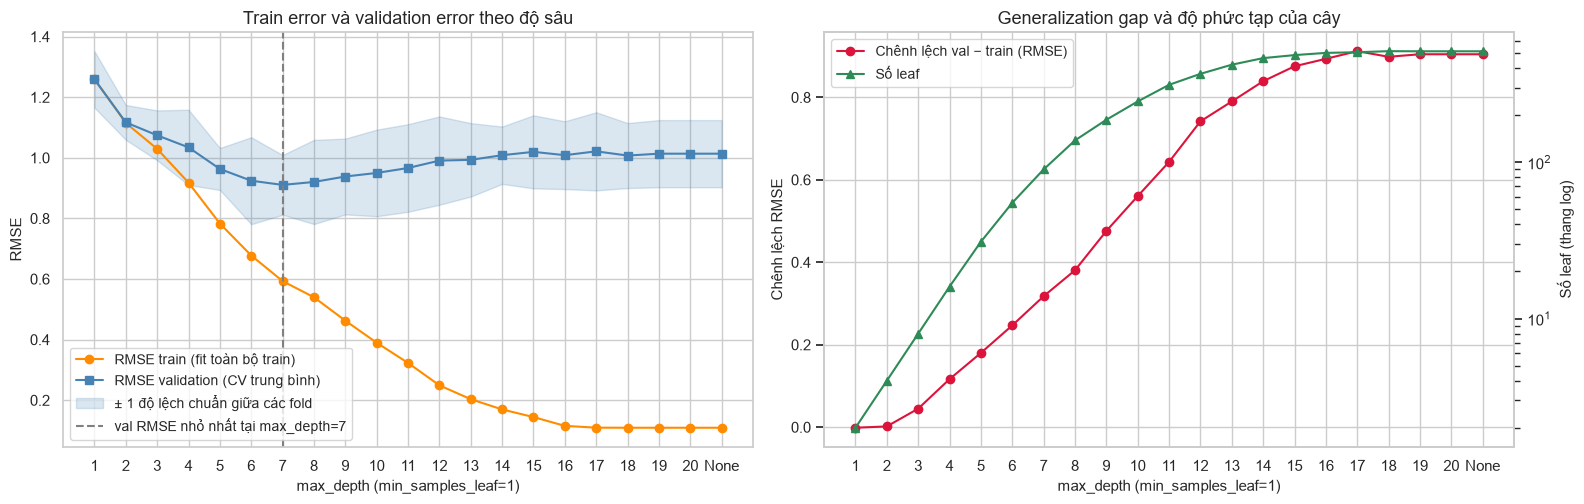

In [38]:
positions = np.arange(len(depth_experiment_df))
labels = depth_experiment_df["max_depth_label"].tolist()
best_idx = int(depth_experiment_df["cv_val_rmse"].idxmin())

fig, axes = plt.subplots(1, 2, figsize=(16, 5.2))
ax = axes[0]
ax.plot(positions, depth_experiment_df["train_rmse_full_fit"], marker="o", color="darkorange", label="RMSE train (fit toàn bộ train)")
ax.plot(positions, depth_experiment_df["cv_val_rmse"], marker="s", color="steelblue", label="RMSE validation (CV trung bình)")
ax.fill_between(positions,
                depth_experiment_df["cv_val_rmse"] - depth_experiment_df["cv_val_rmse_std"],
                depth_experiment_df["cv_val_rmse"] + depth_experiment_df["cv_val_rmse_std"],
                color="steelblue", alpha=0.2, label="± 1 độ lệch chuẩn giữa các fold")
ax.axvline(best_idx, color="gray", linestyle="--", label=f"val RMSE nhỏ nhất tại max_depth={labels[best_idx]}")
ax.set_xticks(positions)
ax.set_xticklabels(labels)
ax.set_xlabel("max_depth (min_samples_leaf=1)")
ax.set_ylabel("RMSE")
ax.set_title("Train error và validation error theo độ sâu")
ax.legend()

ax = axes[1]
ax.plot(positions, depth_experiment_df["gap_val_minus_train"], marker="o", color="crimson", label="Chênh lệch val − train (RMSE)")
ax.set_xticks(positions)
ax.set_xticklabels(labels)
ax.set_xlabel("max_depth (min_samples_leaf=1)")
ax.set_ylabel("Chênh lệch RMSE")
ax.set_title("Generalization gap và độ phức tạp của cây")
twin = ax.twinx()
twin.plot(positions, depth_experiment_df["n_leaves_full_fit"], marker="^", color="seagreen", label="Số leaf")
twin.set_yscale("log")
twin.set_ylabel("Số leaf (thang log)")
twin.grid(False)
lines_a, labels_a = ax.get_legend_handles_labels()
lines_b, labels_b = twin.get_legend_handles_labels()
ax.legend(lines_a + lines_b, labels_a + labels_b, loc="upper left")
fig.tight_layout()
save_figure(fig, "11_train_vs_validation_by_depth.png")
plt.show()

## 11.3. Ước lượng phương sai thực nghiệm bằng huấn luyện lại trên nhiều mẫu con

**Quy trình** (dùng *validation fold đầu tiên* của CV, không dùng tập test):

1. Lấy phần train của fold 0 làm "kho" dữ liệu (pool) và validation của fold 0 làm tập thăm dò (probe) có nhãn.
2. Với mỗi độ sâu: huấn luyện lại `VARIANCE_N_REPEATS` cây, mỗi cây trên một **mẫu con ngẫu nhiên không hoàn lại** gồm `VARIANCE_SUBSAMPLE_FRAC` của pool (cùng các mẫu con cho mọi độ sâu).
3. Với mỗi điểm probe, ta có $B$ dự đoán $\hat f_b(x)$. Tính:
   - **variance** = phương sai của $\hat f_b(x)$ theo $b$ (trung bình trên các điểm),
   - **bias² + nhiễu** = $(\bar f(x)-y)^2$ trong đó $\bar f=\frac1B\sum_b\hat f_b$ (trung bình trên các điểm),
   - **MSE của một cây** = trung bình của $(\hat f_b(x)-y)^2$ theo cả $b$ và điểm.

Với phương sai tính theo `ddof=0`, đẳng thức **MSE một cây = bias² + nhiễu + variance** đúng *chính xác* (đại số, ta kiểm tra bằng `assert`).

**Giới hạn của phép đo (cần nhớ khi diễn giải):**
- Các mẫu con **chồng lấn** nhau (đều lấy từ cùng một pool), nên variance đo được thường *thấp hơn* variance thật khi lấy các tập huấn luyện độc lập từ tổng thể.
- "bias² + nhiễu" **gộp** nhiễu bất khả quy với bias; ta không tách riêng được hai thứ này từ dữ liệu thực.
- Chỉ dùng $B$ hữu hạn lần và một fold; kết quả có nhiễu lấy mẫu.
- Đây **không** phải triển khai Bagging; $\bar f$ chỉ được dùng để tính đại số. Nhưng nó gợi ý điều ta sẽ nghiên cứu ở notebook sau: *trung bình hóa nhiều cây* loại bỏ đúng phần variance (RMSE của $\bar f$ ≤ RMSE trung bình của từng cây, theo bất đẳng thức Jensen).

In [39]:
fold0_train_idx, fold0_valid_idx = CV_FOLD_INDICES[0]
X_pool, y_pool = X_train.iloc[fold0_train_idx], y_train.iloc[fold0_train_idx]
X_probe, y_probe = X_train.iloc[fold0_valid_idx], y_train.iloc[fold0_valid_idx]
y_probe_array = y_probe.to_numpy()

rng_variance = make_rng(11)
subsample_size = int(VARIANCE_SUBSAMPLE_FRAC * len(X_pool))
subsample_indices = [rng_variance.choice(len(X_pool), size=subsample_size, replace=False)
                     for _ in range(VARIANCE_N_REPEATS)]

variance_rows = []
variance_start = time.perf_counter()
per_sample_std_by_depth = {}
for depth in VARIANCE_DEPTHS:
    predictions = np.empty((VARIANCE_N_REPEATS, len(X_probe)))
    for b, idx in enumerate(subsample_indices):
        tree_b = DecisionTreeRegressor(max_depth=depth, min_samples_leaf=1, random_state=RANDOM_STATE + b)
        tree_b.fit(X_pool.iloc[idx], y_pool.iloc[idx])
        predictions[b] = tree_b.predict(X_probe)

    mean_prediction = predictions.mean(axis=0)
    per_sample_variance = predictions.var(axis=0, ddof=0)
    mse_single_tree = float(np.mean((predictions - y_probe_array) ** 2))
    bias2_plus_noise = float(np.mean((mean_prediction - y_probe_array) ** 2))
    mean_variance = float(per_sample_variance.mean())
    assert np.isclose(mse_single_tree, bias2_plus_noise + mean_variance, rtol=1e-9), "Đẳng thức phân rã bị vi phạm"

    per_sample_std_by_depth[depth_label(depth)] = np.sqrt(per_sample_variance)
    variance_rows.append({
        "max_depth": np.nan if depth is None else float(depth), "max_depth_label": depth_label(depth),
        "mse_single_tree": mse_single_tree, "rmse_single_tree": float(np.sqrt(mse_single_tree)),
        "bias2_plus_noise": bias2_plus_noise, "variance": mean_variance,
        "variance_share_of_mse": mean_variance / mse_single_tree,
        "mean_prediction_std": float(np.sqrt(per_sample_variance).mean()),
        "rmse_of_mean_prediction": float(np.sqrt(bias2_plus_noise)),
    })
variance_df = pd.DataFrame(variance_rows)
print(f"{VARIANCE_N_REPEATS} lần huấn luyện x {len(VARIANCE_DEPTHS)} độ sâu trên pool {len(X_pool):,} mẫu "
      f"(mẫu con {subsample_size:,}) - {time.perf_counter() - variance_start:.1f}s")
display(variance_df)

30 lần huấn luyện x 5 độ sâu trên pool 632 mẫu (mẫu con 442) - 0.5s


,max_depth,max_depth_label,mse_single_tree,rmse_single_tree,bias2_plus_noise,variance,variance_share_of_mse,mean_prediction_std,rmse_of_mean_prediction
0,2.0000,2,1.2698,1.1268,1.2067,0.0630,0.0497,0.2241,1.0985
1,5.0000,5,0.9723,0.9860,0.7000,0.2723,0.2801,0.4009,0.8366
2,8.0000,8,0.9332,0.9660,0.5554,0.3778,0.4049,0.4690,0.7452
3,12.0000,12,1.1164,1.0566,0.6012,0.5152,0.4615,0.5433,0.7754
4,NaN,None,1.1290,1.0626,0.5929,0.5361,0.4749,0.5599,0.7700


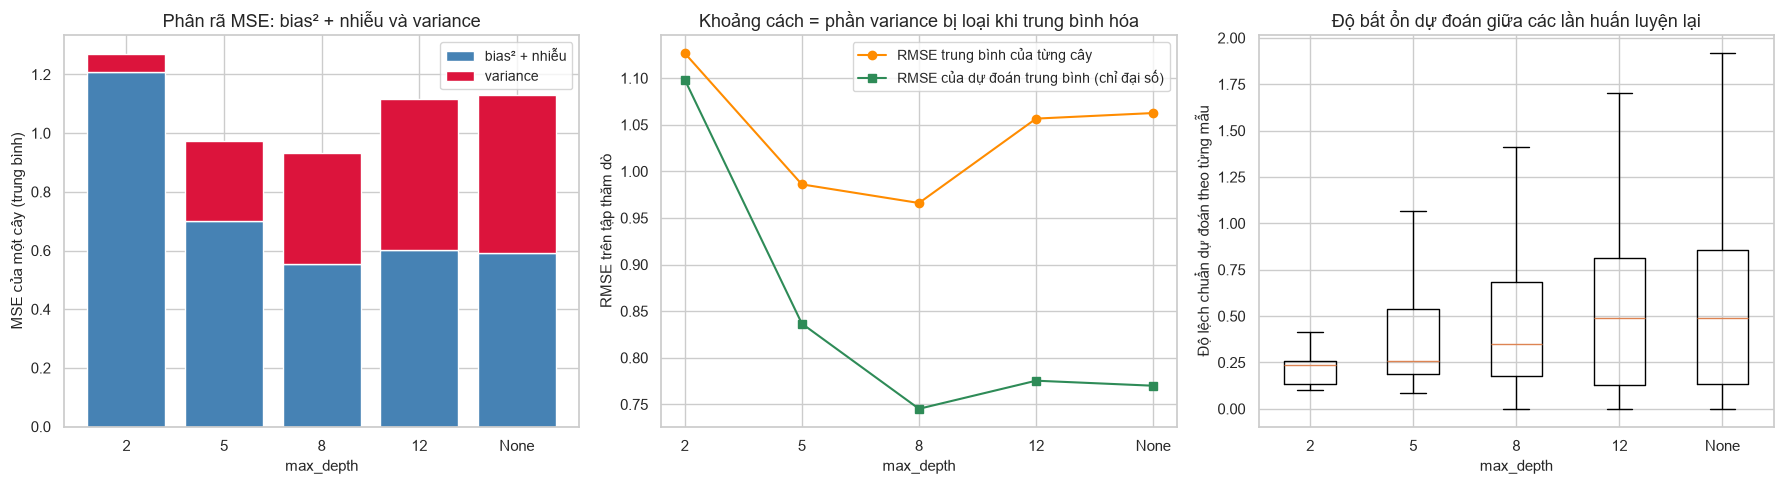

In [40]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
pos = np.arange(len(variance_df))
lab = variance_df["max_depth_label"].tolist()

axes[0].bar(pos, variance_df["bias2_plus_noise"], color="steelblue", label="bias² + nhiễu")
axes[0].bar(pos, variance_df["variance"], bottom=variance_df["bias2_plus_noise"], color="crimson", label="variance")
axes[0].set_xticks(pos)
axes[0].set_xticklabels(lab)
axes[0].set_xlabel("max_depth")
axes[0].set_ylabel("MSE của một cây (trung bình)")
axes[0].set_title("Phân rã MSE: bias² + nhiễu và variance")
axes[0].legend()

axes[1].plot(pos, variance_df["rmse_single_tree"], marker="o", color="darkorange", label="RMSE trung bình của từng cây")
axes[1].plot(pos, variance_df["rmse_of_mean_prediction"], marker="s", color="seagreen", label="RMSE của dự đoán trung bình (chỉ đại số)")
axes[1].set_xticks(pos)
axes[1].set_xticklabels(lab)
axes[1].set_xlabel("max_depth")
axes[1].set_ylabel("RMSE trên tập thăm dò")
axes[1].set_title("Khoảng cách = phần variance bị loại khi trung bình hóa")
axes[1].legend()

axes[2].boxplot([per_sample_std_by_depth[l] for l in lab], showfliers=False)   # không truyền labels: tên tham số đổi giữa các bản Matplotlib
axes[2].set_xticks(np.arange(1, len(lab) + 1))
axes[2].set_xticklabels(lab)
axes[2].set_xlabel("max_depth")
axes[2].set_ylabel("Độ lệch chuẩn dự đoán theo từng mẫu")
axes[2].set_title("Độ bất ổn dự đoán giữa các lần huấn luyện lại")
fig.tight_layout()
save_figure(fig, "11_variance_experiment.png")
plt.show()
SECTION_STATUS["11"] = "hoàn thành"

<a id="part-12"></a>
# PHẦN 12 — So sánh Scratch Tree và Scikit-learn

## 12.1. Mục tiêu kiểm chứng

Ta **không** đòi hai cây phải cho dự đoán giống hệt nhau. Mục tiêu là kiểm chứng bốn điều:

1. Thuật toán tự cài đặt thực sự học được các split hợp lệ.
2. Mức giảm impurity được tính đúng (so với Scikit-learn tại root, nơi hầu như không có đồng hạng).
3. Chất lượng dự đoán có ý nghĩa (so với `DummyRegressor`, `LinearRegression` ở Phần 09–10).
4. Mọi khác biệt được **phân tích** thay vì che giấu.

Ta so sánh hai cặp có tham số trùng nhau: **(a)** cấu hình tham chiếu định trước (Phần 09) và **(b)** cấu hình chọn bởi cross-validation (Phần 10). Dự đoán trên test **đã được tính một lần** và lưu trong `TEST_LEDGER`; phần này chỉ dùng lại các dự đoán đó, không đánh giá thêm.

In [41]:
COMPARISON_PAIRS = {
    "tham chiếu (định trước)": ("scratch_tree_reference", "sklearn_tree_reference"),
    "chọn bởi CV": ("scratch_tree_cv_selected", "sklearn_tree_cv_selected"),
}
IDENTICAL_ATOL = 1e-9


def compare_pair(scratch_name: str, sklearn_name: str) -> dict:
    pred_scratch = TEST_LEDGER.predictions[scratch_name]
    pred_sklearn = TEST_LEDGER.predictions[sklearn_name]
    m_scratch = regression_metrics(y_test, pred_scratch)
    m_sklearn = regression_metrics(y_test, pred_sklearn)
    diff = np.abs(pred_scratch - pred_sklearn)
    model_scratch, model_sklearn = FITTED_MODELS[scratch_name], FITTED_MODELS[sklearn_name]
    records = {r["model"]: r for r in BASELINE_RECORDS}
    correlation = float(np.corrcoef(pred_scratch, pred_sklearn)[0, 1]) if pred_scratch.std() > 0 and pred_sklearn.std() > 0 else float("nan")
    return {
        "rmse_scratch": m_scratch["rmse"], "rmse_sklearn": m_sklearn["rmse"], "rmse_diff": m_scratch["rmse"] - m_sklearn["rmse"],
        "mae_scratch": m_scratch["mae"], "mae_sklearn": m_sklearn["mae"], "mae_diff": m_scratch["mae"] - m_sklearn["mae"],
        "r2_scratch": m_scratch["r2"], "r2_sklearn": m_sklearn["r2"], "r2_diff": m_scratch["r2"] - m_sklearn["r2"],
        "depth_scratch": model_scratch.get_depth(), "depth_sklearn": model_sklearn.get_depth(),
        "leaves_scratch": model_scratch.get_n_leaves(), "leaves_sklearn": model_sklearn.get_n_leaves(),
        "fit_time_scratch_s": records[scratch_name]["fit_time_s"], "fit_time_sklearn_s": records[sklearn_name]["fit_time_s"],
        "predict_time_scratch_s": records[scratch_name]["predict_time_s"], "predict_time_sklearn_s": records[sklearn_name]["predict_time_s"],
        "mean_abs_pred_diff": float(diff.mean()), "max_abs_pred_diff": float(diff.max()),
        "pred_correlation": correlation,
        "share_identical_predictions": float((diff <= IDENTICAL_ATOL).mean()),
    }


comparison_df = pd.DataFrame({label: compare_pair(*names) for label, names in COMPARISON_PAIRS.items()})
display(comparison_df)

,tham chiếu (định trước),chọn bởi CV
rmse_scratch,0.8434,0.7719
rmse_sklearn,0.7987,0.7812
rmse_diff,0.0447,-0.0093
mae_scratch,0.5096,0.5198
mae_sklearn,0.4965,0.5267
mae_diff,0.0131,-0.0069
r2_scratch,0.7617,0.8004
r2_sklearn,0.7863,0.7956
r2_diff,-0.0246,0.0049
depth_scratch,8.0000,8.0000


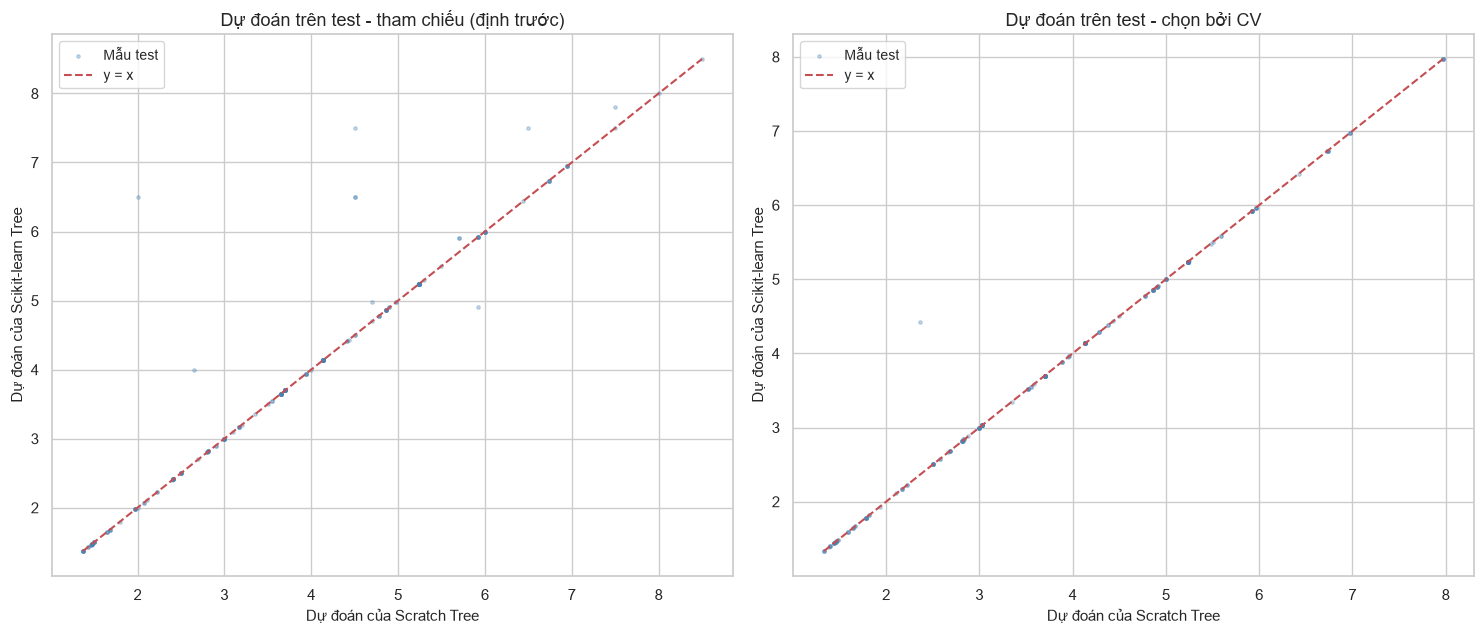

In [42]:
fig, axes = plt.subplots(1, len(COMPARISON_PAIRS), figsize=(7.5 * len(COMPARISON_PAIRS), 6.5))
axes = np.atleast_1d(axes)
for ax, (label, (scratch_name, sklearn_name)) in zip(axes, COMPARISON_PAIRS.items()):
    ps, pk = TEST_LEDGER.predictions[scratch_name], TEST_LEDGER.predictions[sklearn_name]
    ax.scatter(ps, pk, s=6, alpha=0.3, color="steelblue", label="Mẫu test")
    lims = [min(ps.min(), pk.min()), max(ps.max(), pk.max())]
    ax.plot(lims, lims, "r--", linewidth=1.5, label="y = x")
    ax.set_title(f"Dự đoán trên test - {label}")
    ax.set_xlabel("Dự đoán của Scratch Tree")
    ax.set_ylabel("Dự đoán của Scikit-learn Tree")
    ax.legend()
fig.tight_layout()
save_figure(fig, "12_scratch_vs_sklearn_predictions.png")
plt.show()

## 12.2. So sánh split tại root

Tại root có $n$ lớn, hầu như không có hai split đồng hạng, nên đây là điểm kiểm tra sạch nhất cho **công thức impurity** và **cách chọn ngưỡng**. Với Scikit-learn, mức giảm tại root được tính lại từ `tree_.impurity` và `tree_.n_node_samples` theo đúng công thức Phần 5.4.

In [43]:
def sklearn_root_split(model: DecisionTreeRegressor) -> dict:
    tree_ = model.tree_
    if tree_.children_left[0] == -1:
        return {"feature": None, "threshold": None, "gain": 0.0}
    left, right = tree_.children_left[0], tree_.children_right[0]
    n_total = tree_.n_node_samples[0]
    after = (tree_.n_node_samples[left] / n_total) * tree_.impurity[left] + (tree_.n_node_samples[right] / n_total) * tree_.impurity[right]
    return {"feature": FEATURE_NAMES[tree_.feature[0]], "threshold": float(tree_.threshold[0]),
            "gain": float(tree_.impurity[0] - after)}


root_rows = []
for label, (scratch_name, sklearn_name) in COMPARISON_PAIRS.items():
    s_model, k_model = FITTED_MODELS[scratch_name], FITTED_MODELS[sklearn_name]
    sk_root = sklearn_root_split(k_model)
    sc_root = {"feature": FEATURE_NAMES[s_model.root_.feature_index] if not s_model.root_.is_leaf else None,
               "threshold": s_model.root_.threshold, "gain": s_model.root_.gain}
    root_rows.append({
        "cặp": label,
        "feature_scratch": sc_root["feature"], "feature_sklearn": sk_root["feature"],
        "threshold_scratch": sc_root["threshold"], "threshold_sklearn": sk_root["threshold"],
        "gain_scratch": sc_root["gain"], "gain_sklearn": sk_root["gain"],
        "abs_diff_gain": abs(sc_root["gain"] - sk_root["gain"]),
        "same_feature": sc_root["feature"] == sk_root["feature"],
    })
root_comparison_df = pd.DataFrame(root_rows).set_index("cặp")
display(root_comparison_df.T)

cặp,tham chiếu (định trước),chọn bởi CV
feature_scratch,deposit_filled,deposit_filled
feature_sklearn,deposit_filled,deposit_filled
threshold_scratch,3.1500,3.1500
threshold_sklearn,3.1500,3.1500
gain_scratch,1.0167,1.0167
gain_sklearn,1.0167,1.0167
abs_diff_gain,0.0000,0.0000
same_feature,True,True


## 12.3. Thí nghiệm đối chiếu có kiểm soát (chỉ dùng dữ liệu train)

Trên một **mẫu nhỏ của tập train** (không đụng test), ta fit hai cây với cùng tham số và so sánh (i) dự đoán trên chính các mẫu huấn luyện, (ii) dự đoán trên các mẫu train *khác* chưa dùng để fit (nơi sự khác biệt về ngưỡng có thể lộ ra). Với `max_depth=None` và đặc trưng liên tục, cả hai cây đều khớp hoàn toàn dữ liệu huấn luyện nên dự đoán trên train phải trùng.

In [44]:
rng_small = make_rng(12)
n_controlled = min(600, len(X_train))
small_idx = rng_small.choice(len(X_train), size=n_controlled, replace=False)
split_point = n_controlled // 2
fit_idx, probe_idx = small_idx[:split_point], small_idx[split_point:]
X_small, y_small = X_train.iloc[fit_idx], y_train.iloc[fit_idx]
X_other = X_train.iloc[probe_idx]

controlled_rows = []
for depth in (3, 6, None):
    scratch_small = ScratchDecisionTreeRegressor(max_depth=depth).fit(X_small, y_small)
    sklearn_small = DecisionTreeRegressor(max_depth=depth, random_state=RANDOM_STATE).fit(X_small, y_small)
    fit_diff = np.abs(scratch_small.predict(X_small) - sklearn_small.predict(X_small))
    other_diff = np.abs(scratch_small.predict(X_other) - sklearn_small.predict(X_other))
    controlled_rows.append({
        "max_depth": depth_label(depth),
        "leaves (scratch/sklearn)": f"{scratch_small.get_n_leaves()}/{sklearn_small.get_n_leaves()}",
        "depth (scratch/sklearn)": f"{scratch_small.get_depth()}/{sklearn_small.get_depth()}",
        "max |diff| trên mẫu fit": float(fit_diff.max()),
        "share identical trên mẫu fit": float((fit_diff <= IDENTICAL_ATOL).mean()),
        "mean |diff| trên mẫu train khác": float(other_diff.mean()),
        "share identical trên mẫu train khác": float((other_diff <= IDENTICAL_ATOL).mean()),
    })
display(pd.DataFrame(controlled_rows).set_index("max_depth"))


,leaves (scratch/sklearn),depth (scratch/sklearn),max |diff| trên mẫu fit,share identical trên mẫu fit,mean |diff| trên mẫu train khác,share identical trên mẫu train khác
max_depth,,,,,,
3,8/8,3/3,0.0000,1.0000,0.0000,1.0000
6,49/49,6/6,0.0000,1.0000,0.0155,0.9700
None,201/211,16/16,0.0000,1.0000,0.1167,0.7467


## 12.4. Vì sao hai cây có thể khác nhau?

Các nguyên nhân hợp lý (không phải lỗi) cần cân nhắc khi bạn đọc các bảng trên:

1. **Quy tắc xử lý split đồng hạng.** Khi hai (đặc trưng, ngưỡng) cho cùng $\Delta I$, cây tự cài đặt chọn *đặc trưng có chỉ số nhỏ hơn rồi ngưỡng nhỏ hơn* (xác định). Scikit-learn duyệt đặc trưng theo thứ tự ngẫu nhiên (phụ thuộc `random_state`). Với node nhỏ (vài mẫu) đồng hạng khá phổ biến; hai split khác nhau nhưng cùng phân hoạch mẫu huấn luyện sẽ cho cùng dự đoán trên train nhưng **khác nhau ở điểm mới** nằm giữa hai ngưỡng.
2. **Độ chính xác số.** Scikit-learn **chuyển đặc trưng sang `float32`** khi fit, và ngưỡng của nó là trung điểm của các giá trị `float32`; cây tự cài đặt dùng `float64`. Do đó ngưỡng có thể lệch cỡ $10^{-7}$ (tương đối), và một mẫu nằm sát ngưỡng có thể rẽ sang nhánh khác. Ngoài ra phép cộng dồn thực hiện theo thứ tự khác nhau nên sai số làm tròn khác nhau.
3. **Quy tắc dừng.** Cả hai có `max_depth`, `min_samples_split`, `min_samples_leaf`, `min_impurity_decrease` nhưng chi tiết như dung sai khi coi node "đồng nhất", hay cách so sánh `min_impurity_decrease`, được cài đặt khác nhau.
4. **Cách triển khai thuật toán.** Scikit-learn viết bằng Cython, dùng các biến "proxy" của tiêu chí để tăng tốc; kết quả tương đương về mặt toán học nhưng không nhất thiết trùng từng bit.
5. **Khác biệt về tham số hoặc phiên bản thư viện.** Mặc định và hành vi có thể thay đổi giữa các bản Scikit-learn (phiên bản đang dùng được in ở Phần 01).

Cách đọc kết quả: nếu `RMSE`, `MAE`, `R²` của hai cây rất gần nhau, độ sâu/số leaf tương đương, tương quan dự đoán gần 1 và split tại root trùng, thì cây tự cài đặt **hành xử như một cây squared-error chuẩn**. Các khác biệt còn lại nên được giải thích bằng danh sách trên chứ không bị ép phải bằng 0. Cell dưới đây tóm tắt các con số thực tế của lần chạy này.

In [45]:
lines = ["### Tóm tắt so sánh (sinh tự động từ các bảng ở trên)\n"]
for label in COMPARISON_PAIRS:
    c = comparison_df[label]
    root = root_comparison_df.loc[label]
    lines.append(
        f"- **{label}**: RMSE scratch {c['rmse_scratch']:.4f} so với sklearn {c['rmse_sklearn']:.4f} "
        f"(chênh {c['rmse_diff']:+.4f}); R² chênh {c['r2_diff']:+.4f}; "
        f"độ sâu {int(c['depth_scratch'])}/{int(c['depth_sklearn'])}, số leaf {int(c['leaves_scratch'])}/{int(c['leaves_sklearn'])}; "
        f"|dự đoán scratch − sklearn| trung bình {c['mean_abs_pred_diff']:.5f}, lớn nhất {c['max_abs_pred_diff']:.4f}; "
        f"tương quan dự đoán {c['pred_correlation']:.5f}; {c['share_identical_predictions']:.1%} dự đoán trùng (dung sai {IDENTICAL_ATOL:g}). "
        f"Split root: {'cùng' if root['same_feature'] else 'KHÁC'} đặc trưng ({root['feature_scratch']} / {root['feature_sklearn']}), "
        f"chênh lệch gain {root['abs_diff_gain']:.2e}."
    )
lines.append(f"- Thời gian fit (trung vị {TIMING_REPEATS} lần) của cây tự cài đặt: {comparison_df.loc['fit_time_scratch_s'].iloc[-1]:.2f}s so với "
             f"{comparison_df.loc['fit_time_sklearn_s'].iloc[-1]:.3f}s của Scikit-learn ở cấu hình chọn bởi CV — chỉ là số đo trong môi trường này, "
             "phản ánh khác biệt Python/NumPy thuần so với Cython, không phản ánh độ đúng.")
show_md("\n".join(lines))
SECTION_STATUS["12"] = "hoàn thành"

### Tóm tắt so sánh (sinh tự động từ các bảng ở trên)

- **tham chiếu (định trước)**: RMSE scratch 0.8434 so với sklearn 0.7987 (chênh +0.0447); R² chênh -0.0246; độ sâu 8/8, số leaf 134/138; |dự đoán scratch − sklearn| trung bình 0.08005, lớn nhất 4.5000; tương quan dự đoán 0.96341; 94.4% dự đoán trùng (dung sai 1e-09). Split root: cùng đặc trưng (deposit_filled / deposit_filled), chênh lệch gain 2.22e-16.
- **chọn bởi CV**: RMSE scratch 0.7719 so với sklearn 0.7812 (chênh -0.0093); R² chênh +0.0049; độ sâu 8/8, số leaf 73/73; |dự đoán scratch − sklearn| trung bình 0.01055, lớn nhất 2.0686; tương quan dự đoán 0.99585; 99.0% dự đoán trùng (dung sai 1e-09). Split root: cùng đặc trưng (deposit_filled / deposit_filled), chênh lệch gain 2.22e-16.
- Thời gian fit (trung vị 3 lần) của cây tự cài đặt: 0.04s so với 0.003s của Scikit-learn ở cấu hình chọn bởi CV — chỉ là số đo trong môi trường này, phản ánh khác biệt Python/NumPy thuần so với Cython, không phản ánh độ đúng.

<a id="part-13"></a>
# PHẦN 13 — Giải thích dự đoán và feature importance

## 13.1. Đường đi của một mẫu qua Scratch Tree

Ta lấy **mẫu test đầu tiên** (chỉ để minh họa; không dùng nhãn test) và theo dõi nó từ root đến leaf trong cây tự cài đặt đã chọn bằng CV. Với mỗi node trên đường đi, ta thấy điều kiện, giá trị đặc trưng của mẫu, nhánh được chọn, số mẫu huấn luyện và giá trị trung bình của node. Cột `value_change_from_parent` cho biết dự đoán thay đổi bao nhiêu sau mỗi lần rẽ — đây là cách *quy gán theo đường đi* (path attribution) đơn giản, **không phải SHAP** và có thể thiên lệch.

In [46]:
scratch_final = FITTED_MODELS["scratch_tree_cv_selected"]
sklearn_final = FITTED_MODELS["sklearn_tree_cv_selected"]

explain_row = X_test.iloc[[0]]
print("Đặc trưng của mẫu cần giải thích:")
display(explain_row.T.rename(columns={explain_row.index[0]: "giá trị"}))

path = scratch_final.decision_path(explain_row, feature_names=FEATURE_NAMES)
path_df = pd.DataFrame(path)
display_columns = ["depth", "node_id", "feature", "threshold", "feature_value", "goes", "n_samples",
                   "impurity_mse", "node_value", "value_change_from_parent"]
display(path_df[display_columns])

leaf_prediction = path[-1]["node_value"]
assert np.isclose(leaf_prediction, scratch_final.predict(explain_row)[0]), "Dự đoán theo đường đi phải bằng predict()"
print(f"\nLeaf cuối cùng: node #{path[-1]['node_id']} (n={path[-1]['n_samples']} mẫu huấn luyện). "
      f"Dự đoán = trung bình mục tiêu của leaf = {leaf_prediction:.4f}")

# Đối chiếu đường đi trong Scikit-learn Tree (cùng mẫu)
sk_node_ids = sklearn_final.decision_path(explain_row).indices
sk_rows = []
for node_id in sk_node_ids:
    tree_ = sklearn_final.tree_
    is_leaf = tree_.children_left[node_id] == -1
    sk_rows.append({
        "node_id": int(node_id),
        "feature": None if is_leaf else FEATURE_NAMES[tree_.feature[node_id]],
        "threshold": None if is_leaf else float(tree_.threshold[node_id]),
        "n_samples": int(tree_.n_node_samples[node_id]),
        "node_value": float(tree_.value[node_id].ravel()[0]),
    })
print("\nĐường đi của cùng mẫu trong Scikit-learn Tree (id node đánh số theo quy ước riêng của sklearn):")
display(pd.DataFrame(sk_rows))
print(f"Dự đoán Scikit-learn Tree = {sklearn_final.predict(explain_row)[0]:.4f}")

Đặc trưng của mẫu cần giải thích:


,giá trị
area_m2_clean,30.0000
deposit_filled,3.2000
has_deposit_info,0.0000
furniture_code,1.0000
is_central,0.0000
is_suburban,0.0000
has_may_lanh,0.0000
has_tu_lanh,0.0000
has_may_giat,0.0000
has_gac,0.0000


,depth,node_id,feature,threshold,feature_value,goes,n_samples,impurity_mse,node_value,value_change_from_parent
0,0,0,deposit_filled,3.1500,3.2000,phải (>),791,2.6045,3.7432,NaN
1,1,68,deposit_filled,5.1000,3.2000,trái (<=),517,1.9744,4.4773,0.7341
2,2,69,is_sleepbox_ktx,0.5000,0.0000,trái (<=),430,1.5957,4.1771,-0.3002
3,3,70,is_central,0.5000,0.0000,trái (<=),411,1.4104,4.2750,0.0980
4,4,71,area_m2_clean,24.5000,30.0000,phải (>),217,0.8030,3.8016,-0.4734
5,5,87,area_m2_clean,43.5000,30.0000,trái (<=),155,0.6623,4.0365,0.2349
6,6,88,deposit_filled,4.2500,3.2000,trái (<=),150,0.5473,3.9884,-0.0481
7,7,89,has_deposit_info,0.5000,0.0000,trái (<=),133,0.5462,3.9110,-0.0774
8,8,90,NaN,NaN,NaN,LEAF,64,0.9195,4.1375,0.2265



Leaf cuối cùng: node #90 (n=64 mẫu huấn luyện). Dự đoán = trung bình mục tiêu của leaf = 4.1375

Đường đi của cùng mẫu trong Scikit-learn Tree (id node đánh số theo quy ước riêng của sklearn):


,node_id,feature,threshold,n_samples,node_value
0,0,deposit_filled,3.1500,791,3.7432
1,68,deposit_filled,5.1000,517,4.4773
2,69,is_sleepbox_ktx,0.5000,430,4.1771
3,70,is_central,0.5000,411,4.2750
4,71,area_m2_clean,24.5000,217,3.8016
5,87,area_m2_clean,43.5000,155,4.0365
6,88,deposit_filled,4.2500,150,3.9884
7,89,has_deposit_info,0.5000,133,3.9110
8,90,NaN,NaN,64,4.1375


Dự đoán Scikit-learn Tree = 4.1375


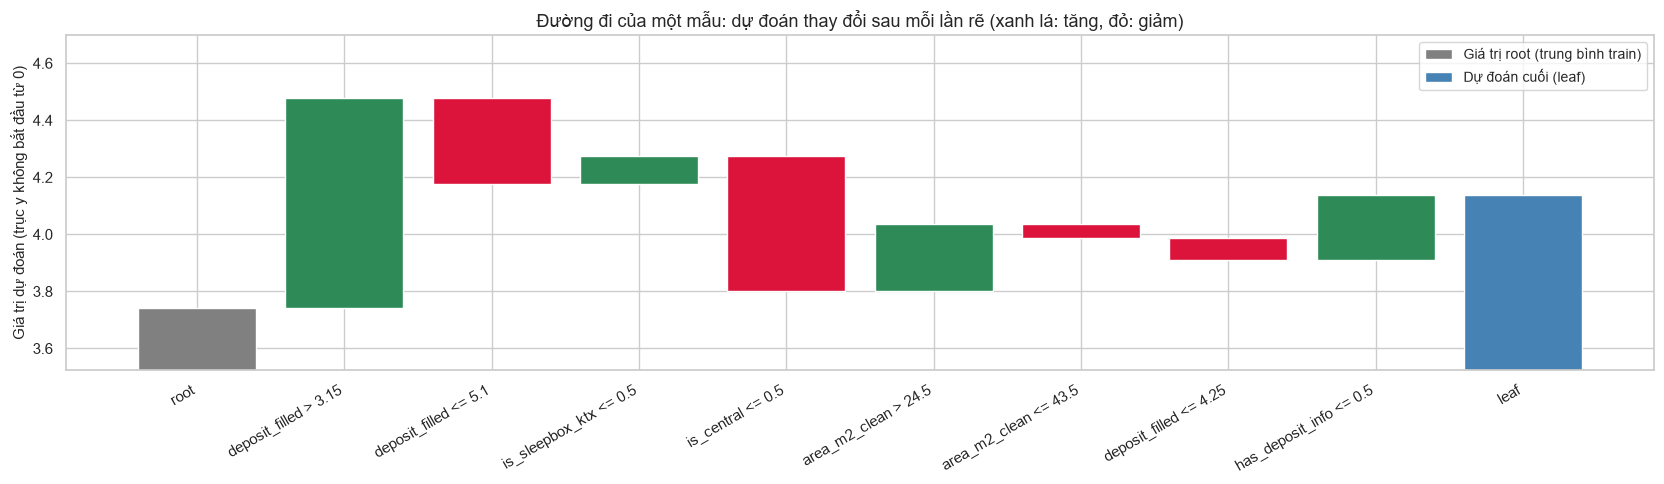

In [47]:
steps = path_df.copy()
start_value = float(steps.loc[0, "node_value"])
changes = steps["value_change_from_parent"].fillna(0.0).to_numpy()[1:]
step_labels = [f"{r.feature} {'<=' if r.goes.startswith('trái') else '>'} {r.threshold:.3g}" for r in steps.iloc[:-1].itertuples()]

fig, ax = plt.subplots(figsize=(max(9, 1.6 * len(changes) + 4), 5))
running = start_value
ax.bar(0, start_value, color="gray", label="Giá trị root (trung bình train)")
for i, delta in enumerate(changes, start=1):
    ax.bar(i, delta, bottom=running, color="seagreen" if delta >= 0 else "crimson")
    running += delta
ax.bar(len(changes) + 1, running, color="steelblue", label="Dự đoán cuối (leaf)")
levels = start_value + np.concatenate([[0.0], np.cumsum(changes)])
pad = max(0.1 * (levels.max() - levels.min()), 1e-3 * max(abs(levels).max(), 1.0))
ax.set_ylim(levels.min() - 3 * pad, levels.max() + 3 * pad)   # phóng to quanh đường đi để thấy rõ từng bước
ax.set_xticks(range(len(changes) + 2))
ax.set_xticklabels(["root"] + step_labels + ["leaf"], rotation=30, ha="right")
ax.set_ylabel("Giá trị dự đoán (trục y không bắt đầu từ 0)")
ax.set_title("Đường đi của một mẫu: dự đoán thay đổi sau mỗi lần rẽ (xanh lá: tăng, đỏ: giảm)")
ax.legend()
fig.tight_layout()
save_figure(fig, "13_prediction_path_waterfall.png")
plt.show()

## 13.2. Feature importance

Ba góc nhìn, với ý nghĩa khác nhau:

| Loại | Đo cái gì | Tính trên |
|---|---|---|
| **Impurity-based (Scratch)** | Tổng $\Delta I_w$ mà đặc trưng đóng góp qua mọi split, chuẩn hóa | Dữ liệu train (lúc xây cây) |
| **Impurity-based (Scikit-learn)** | Cùng định nghĩa, tính bởi Scikit-learn | Dữ liệu train |
| **Permutation importance** | RMSE **tăng** bao nhiêu khi xáo trộn ngẫu nhiên một đặc trưng | Tập *validation* (fold 0 của CV) — **không** dùng test |

Cho permutation importance, ta fit một cây Scikit-learn với tham số đã chọn trên **phần train của fold 0** rồi đo trên **phần validation của fold 0**. Cách này tránh dùng tập train (dễ thiên lệch với cây overfit) và cũng không động đến test.

Cần nhớ: importance **phản ánh hành vi của mô hình**, không chứng minh tác động nhân quả; các đặc trưng **tương quan với nhau** có thể chia sẻ hoặc thay thế mức quan trọng (nếu hai đặc trưng gần như tương đương, cây có thể chọn đặc trưng này ở node này và đặc trưng kia ở node khác); impurity-based importance **có thể thiên lệch** về đặc trưng có nhiều giá trị khác nhau (nhiều ngưỡng ứng viên hơn).

In [48]:
scratch_importances = scratch_final.get_feature_importances()
sklearn_importances = sklearn_final.feature_importances_

tree_fold0 = DecisionTreeRegressor(**sklearn_selected_params).fit(X_pool, y_pool)
permutation = permutation_importance(
    tree_fold0, X_probe, y_probe, scoring="neg_root_mean_squared_error",
    n_repeats=10, random_state=RANDOM_STATE,
)

scratch_importance_df = pd.DataFrame({
    "feature": FEATURE_NAMES, "importance": scratch_importances,
}).sort_values("importance", ascending=False).reset_index(drop=True)

sklearn_importance_df = pd.DataFrame({
    "feature": FEATURE_NAMES,
    "impurity_importance": sklearn_importances,
    "permutation_importance_mean_rmse_increase": permutation.importances_mean,
    "permutation_importance_std": permutation.importances_std,
}).sort_values("impurity_importance", ascending=False).reset_index(drop=True)

importance_compare_df = pd.DataFrame({
    "feature": FEATURE_NAMES,
    "scratch_importance": scratch_importances,
    "sklearn_importance": sklearn_importances,
})
importance_compare_df["abs_diff"] = (importance_compare_df["scratch_importance"] - importance_compare_df["sklearn_importance"]).abs()
importance_compare_df = importance_compare_df.sort_values("scratch_importance", ascending=False).reset_index(drop=True)
display(importance_compare_df)
display(sklearn_importance_df)

spearman_importance = importance_compare_df[["scratch_importance", "sklearn_importance"]].corr(method="spearman").iloc[0, 1]
print(f"\nTương quan hạng (Spearman) giữa hai bảng importance: {spearman_importance:.4f}")
print(f"Chênh lệch tuyệt đối lớn nhất giữa hai importance: {importance_compare_df['abs_diff'].max():.4f}")

,feature,scratch_importance,sklearn_importance,abs_diff
0,deposit_filled,0.7118,0.7118,0.0000
1,area_m2_clean,0.0871,0.0871,0.0000
2,is_central,0.0764,0.0688,0.0077
3,is_sleepbox_ktx,0.0630,0.0630,0.0000
4,furniture_code,0.0224,0.0224,0.0000
5,is_suburban,0.0119,0.0196,0.0077
6,has_may_lanh,0.0070,0.0070,0.0000
7,has_deposit_info,0.0059,0.0059,0.0000
8,is_studio_duplex,0.0051,0.0051,0.0000
9,has_may_giat,0.0037,0.0037,0.0000


,feature,impurity_importance,permutation_importance_mean_rmse_increase,permutation_importance_std
0,deposit_filled,0.7118,0.7830,0.0961
1,area_m2_clean,0.0871,0.2277,0.0468
2,is_central,0.0688,0.1866,0.0418
3,is_sleepbox_ktx,0.0630,0.2392,0.0525
4,furniture_code,0.0224,0.0259,0.0137
5,is_suburban,0.0196,0.0355,0.0152
6,has_may_lanh,0.0070,0.0114,0.0146
7,has_deposit_info,0.0059,0.0000,0.0063
8,is_studio_duplex,0.0051,-0.0107,0.0046
9,has_may_giat,0.0037,-0.0000,0.0001



Tương quan hạng (Spearman) giữa hai bảng importance: 1.0000
Chênh lệch tuyệt đối lớn nhất giữa hai importance: 0.0077


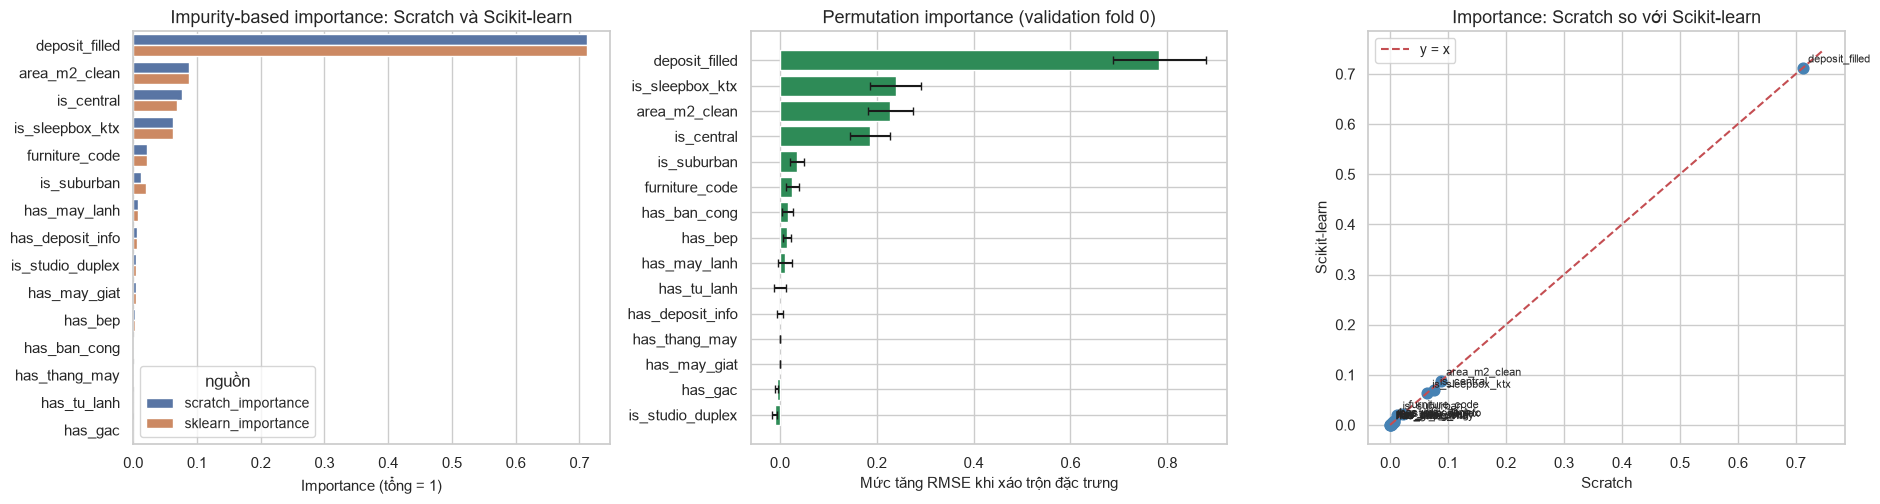

In [49]:
fig, axes = plt.subplots(1, 3, figsize=(19, 5.2))
order_features = importance_compare_df["feature"].tolist()
bar_df = importance_compare_df.melt(id_vars="feature", value_vars=["scratch_importance", "sklearn_importance"],
                                    var_name="nguồn", value_name="importance")
sns.barplot(data=bar_df, y="feature", x="importance", hue="nguồn", order=order_features, ax=axes[0])
axes[0].set_title("Impurity-based importance: Scratch và Scikit-learn")
axes[0].set_xlabel("Importance (tổng = 1)")
axes[0].set_ylabel("")

perm_sorted = sklearn_importance_df.sort_values("permutation_importance_mean_rmse_increase", ascending=True)
axes[1].barh(perm_sorted["feature"], perm_sorted["permutation_importance_mean_rmse_increase"],
             xerr=perm_sorted["permutation_importance_std"], color="seagreen", capsize=3)
axes[1].set_title("Permutation importance (validation fold 0)")
axes[1].set_xlabel("Mức tăng RMSE khi xáo trộn đặc trưng")

scatter_df = importance_compare_df
axes[2].scatter(scatter_df["scratch_importance"], scatter_df["sklearn_importance"], s=60, color="steelblue")
for row in scatter_df.itertuples():
    axes[2].annotate(row.feature, (row.scratch_importance, row.sklearn_importance), fontsize=8, xytext=(4, 4), textcoords="offset points")
lims = [0, max(scatter_df[["scratch_importance", "sklearn_importance"]].max()) * 1.05]
axes[2].plot(lims, lims, "r--", label="y = x")
axes[2].set_title("Importance: Scratch so với Scikit-learn")
axes[2].set_xlabel("Scratch")
axes[2].set_ylabel("Scikit-learn")
axes[2].legend()
fig.tight_layout()
save_figure(fig, "13_feature_importance.png")
plt.show()

## 13.3. Hiển thị cây

Bên trái là cây Scikit-learn vẽ bằng `plot_tree` (chỉ dùng cho mô hình Scikit-learn); bên phải là cây tự cài đặt vẽ bằng hàm `plot_scratch_tree` từ cấu trúc node của chính ta. Cả hai chỉ hiển thị 3 tầng trên cùng để dễ đọc.

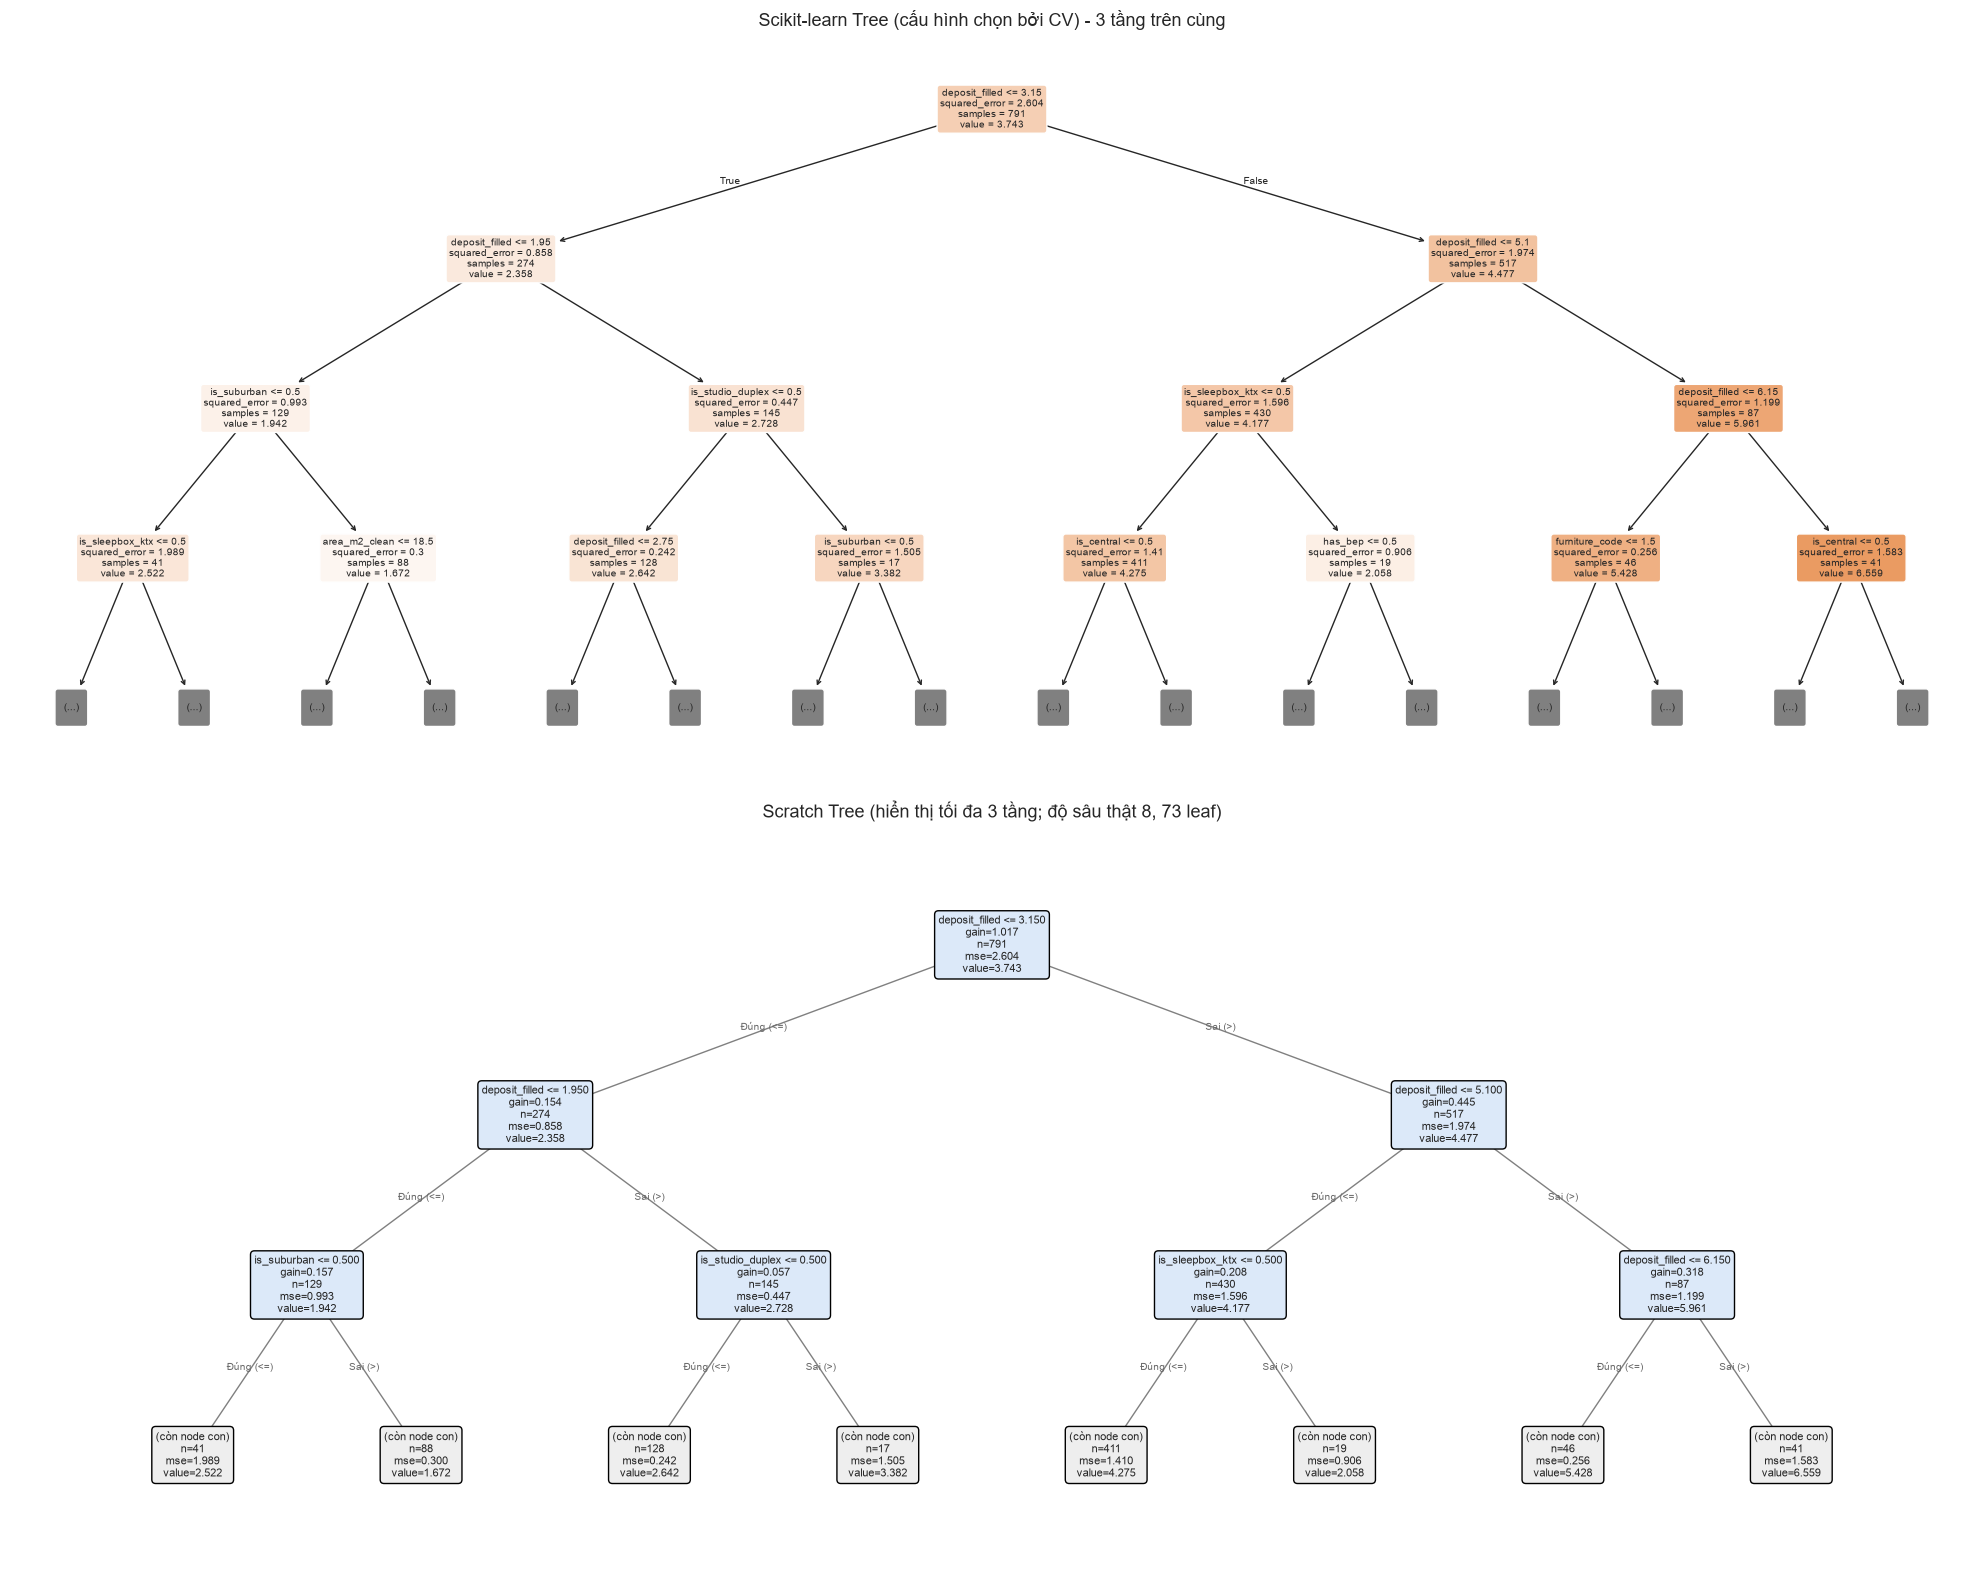

In [50]:
fig, axes = plt.subplots(2, 1, figsize=(20, 16))
plot_tree(sklearn_final, max_depth=3, feature_names=FEATURE_NAMES, filled=True, rounded=True,
          fontsize=7, precision=3, ax=axes[0])
axes[0].set_title("Scikit-learn Tree (cấu hình chọn bởi CV) - 3 tầng trên cùng")
plot_scratch_tree(scratch_final, feature_names=FEATURE_NAMES, max_display_depth=3, ax=axes[1], fontsize=8)
fig.tight_layout()
save_figure(fig, "13_tree_visualizations.png")
plt.show()
SECTION_STATUS["13"] = "hoàn thành"

<a id="part-14"></a>
# PHẦN 14 — Lưu kết quả cho các notebook sau

Cấu trúc thư mục (dưới `PROJECT_ROOT`, được in ở Phần 01):

```
results/
├── tables/     baseline_metrics.csv, decision_tree_cv_results.csv, decision_tree_depth_experiment.csv,
│               scratch_tree_feature_importance.csv, sklearn_tree_feature_importance.csv, và một số bảng bổ sung
├── figures/    các biểu đồ PNG đã lưu ngay khi vẽ
├── models/     sklearn_tree_cv_selected.joblib, scratch_tree_cv_selected.json
└── metadata/   dataset_metadata.json, experiment_config.json, split_indices.json
```

**Cách các notebook sau dùng lại:**

- `experiment_config.json` chứa `random_state`, `test_size`, `cv_folds`, tham số cây đã chọn, môi trường chạy.
- `split_indices.json` chứa **chỉ số dòng gốc** của train/test, để notebook Ensemble dùng *đúng cùng* phép chia (đọc `df`, rồi `df.loc[train_index]`).
- `baseline_metrics.csv` có cùng các cột (`model, family, params, rmse, mae, mse, r2, ...`) mà notebook Ensemble nên thêm dòng của mình vào để so sánh.

**Về an toàn khi lưu mô hình:** cây tự cài đặt được lưu bằng **JSON** (trung lập, đọc được bằng mắt, không thực thi code khi đọc). Mô hình Scikit-learn lưu bằng Joblib; **chỉ mở file joblib/pickle từ nguồn bạn tin cậy**, vì định dạng này có thể thực thi mã tùy ý khi tải.

In [51]:
def to_jsonable(obj):
    """Chuyển numpy/pandas/NaN sang kiểu JSON an toàn."""
    if isinstance(obj, dict):
        return {str(k): to_jsonable(v) for k, v in obj.items()}
    if isinstance(obj, (list, tuple)):
        return [to_jsonable(v) for v in obj]
    if isinstance(obj, np.ndarray):
        return to_jsonable(obj.tolist())
    if isinstance(obj, (np.integer,)):
        return int(obj)
    if isinstance(obj, (np.floating, float)):
        value = float(obj)
        return value if np.isfinite(value) else None
    if isinstance(obj, (np.bool_,)):
        return bool(obj)
    if isinstance(obj, Path):
        return str(obj)
    return obj


def write_json(path: Path, payload) -> Path:
    with open(path, "w", encoding="utf-8") as handle:
        json.dump(to_jsonable(payload), handle, indent=2, ensure_ascii=False)
    return path


saved_files = []

# ---- Bảng ---------------------------------------------------------------------------------
baseline_metrics_out = pd.DataFrame(BASELINE_RECORDS).sort_values("rmse").reset_index(drop=True)
tables_to_save = {
    "baseline_metrics.csv": baseline_metrics_out,
    "decision_tree_cv_results.csv": cv_results_df,
    "decision_tree_depth_experiment.csv": depth_experiment_df,
    "scratch_tree_feature_importance.csv": scratch_importance_df,
    "sklearn_tree_feature_importance.csv": sklearn_importance_df,
    "variance_experiment.csv": variance_df,
    "unit_test_results.csv": unit_test_results_df,
    "scratch_vs_sklearn_comparison.csv": comparison_df.reset_index(names="metric"),
    "test_ledger.csv": TEST_LEDGER.to_frame(),
}
if scratch_cv_comparison_df is not None:
    tables_to_save["scratch_cv_comparison.csv"] = scratch_cv_comparison_df

test_predictions_out = pd.DataFrame({"row_index": X_test.index.to_numpy(), "y_true": y_test.to_numpy()})
for name, predictions in TEST_LEDGER.predictions.items():
    test_predictions_out[f"pred_{name}"] = predictions
tables_to_save["test_predictions_baseline.csv"] = test_predictions_out

for filename, table in tables_to_save.items():
    path = TABLE_DIR / filename
    table.to_csv(path, index=False)
    saved_files.append(path)

# ---- Metadata -----------------------------------------------------------------------------
selected_record = next(r for r in BASELINE_RECORDS if r["model"] == "sklearn_tree_cv_selected")
experiment_config = {
    "notebook": "01_Baseline_DecisionTree_Scratch.ipynb",
    "created_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "random_state": RANDOM_STATE, "test_size": TEST_SIZE, "cv_folds": CV_FOLDS,
    "cv_splitter": {"type": "KFold", "shuffle": True, "random_state": RANDOM_STATE, "applied_to": "train split"},
    "split_function": "sklearn.model_selection.train_test_split(X, y, test_size=test_size, random_state=random_state)",
    "target_column": TARGET_COLUMN, "feature_names": FEATURE_NAMES,
    "data_path": None if DATA_PATH is None else str(DATA_PATH),
    "dataset_name": dataset_info["dataset_name"],
    "n_train": len(X_train), "n_test": len(X_test),
    "depth_grid": [depth_label(d) for d in DEPTH_GRID], "min_samples_leaf_grid": MIN_SAMPLES_LEAF_GRID,
    "reference_tree_params": REFERENCE_TREE_PARAMS,
    "selected_tree_params": SELECTED_TREE_PARAMS,
    "one_standard_error_tree_params": ONE_SE_TREE_PARAMS,
    "selected_cv": {k: best_row[k] for k in ("mean_val_rmse", "std_val_rmse", "mean_val_mae", "mean_val_r2", "mean_n_leaves")},
    "selected_test_rmse_sklearn_tree": selected_record["rmse"],
    "test_usage_ledger": TEST_LEDGER.to_frame().to_dict(orient="records"),
    "environment": ENVIRONMENT_INFO,
    "section_status_at_save_time": dict(SECTION_STATUS),
}
metadata_to_save = {
    "dataset_metadata.json": dataset_metadata,
    "experiment_config.json": experiment_config,
    "split_indices.json": {"train_index": X_train.index.to_numpy(), "test_index": X_test.index.to_numpy(),
                           "note": "Chỉ số dòng gốc của DataFrame df (RangeIndex) - dùng để tái tạo đúng cùng phép chia."},
}
for filename, payload in metadata_to_save.items():
    saved_files.append(write_json(METADATA_DIR / filename, payload))

# ---- Mô hình ------------------------------------------------------------------------------
sklearn_model_path = MODEL_DIR / "sklearn_tree_cv_selected.joblib"
joblib.dump(FITTED_MODELS["sklearn_tree_cv_selected"], sklearn_model_path)
scratch_model_path = write_json(MODEL_DIR / "scratch_tree_cv_selected.json", FITTED_MODELS["scratch_tree_cv_selected"].to_dict())
saved_files += [sklearn_model_path, scratch_model_path]

# ---- Kiểm tra sau khi lưu ------------------------------------------------------------------
reloaded_scratch = ScratchDecisionTreeRegressor.from_dict(json.loads(scratch_model_path.read_text(encoding="utf-8")))
reloaded_sklearn = joblib.load(sklearn_model_path)
assert np.allclose(reloaded_scratch.predict(X_test), TEST_LEDGER.predictions["scratch_tree_cv_selected"]), "JSON round-trip sai"
assert np.allclose(reloaded_sklearn.predict(X_test), TEST_LEDGER.predictions["sklearn_tree_cv_selected"]), "joblib round-trip sai"

figure_files = sorted(FIGURE_DIR.glob("*.png"))
required_tables = ["baseline_metrics.csv", "decision_tree_cv_results.csv", "decision_tree_depth_experiment.csv",
                   "scratch_tree_feature_importance.csv", "sklearn_tree_feature_importance.csv"]
required_metadata = ["dataset_metadata.json", "experiment_config.json"]
for filename in required_tables:
    assert (TABLE_DIR / filename).is_file(), f"Thiếu {filename}"
for filename in required_metadata:
    assert (METADATA_DIR / filename).is_file(), f"Thiếu {filename}"

summary = pd.DataFrame({
    "file": [str(p.relative_to(PROJECT_ROOT)) for p in saved_files + figure_files],
    "kích thước (KB)": [p.stat().st_size / 1024 for p in saved_files + figure_files],
})
display(summary)
print(f"\nĐã lưu {len(saved_files)} file dữ liệu/mô hình và có {len(figure_files)} biểu đồ PNG. "
      "Round-trip JSON và joblib cho dự đoán giống hệt: OK.")
SECTION_STATUS["14"] = "hoàn thành"

,file,kích thước (KB)
0,results\tables\baseline_metrics.csv,2.4297
1,results\tables\decision_tree_cv_results.csv,3.8164
2,results\tables\decision_tree_depth_experiment.csv,3.6621
3,results\tables\scratch_tree_feature_importance...,0.5371
4,results\tables\sklearn_tree_feature_importance...,1.1914
5,results\tables\variance_experiment.csv,0.8359
6,results\tables\unit_test_results.csv,1.6680
7,results\tables\scratch_vs_sklearn_comparison.csv,1.0723
8,results\tables\test_ledger.csv,0.5801
9,results\tables\scratch_cv_comparison.csv,1.0947



Đã lưu 16 file dữ liệu/mô hình và có 26 biểu đồ PNG. Round-trip JSON và joblib cho dự đoán giống hệt: OK.


<a id="part-15"></a>
# PHẦN 15 — Research Conclusion

Phần này **sinh kết luận từ các biến kết quả đã tính** (bảng test, CV, thí nghiệm độ sâu, phương sai, so sánh). Nguyên tắc:

- Mọi con số định lượng được lấy trực tiếp từ kết quả của lần chạy hiện tại; nếu một thí nghiệm chưa chạy, câu trả lời tương ứng ghi rõ *"chưa chạy"*.
- Không kết luận từ một metric duy nhất: mỗi câu trả lời dùng đồng thời sai số, độ biến thiên giữa fold, thời gian và độ phức tạp (độ sâu/số leaf) khi có.
- Các ngưỡng dùng để gọi tên hiện tượng (ví dụ "tương đương", "overfit") là **heuristic** được đặt tường minh ở đầu cell, không phải chuẩn thống kê.
- Mọi kết luận chỉ áp dụng cho dataset, phép chia ngẫu nhiên và cấu hình của lần chạy này (xem giới hạn ở Phần 04).

In [52]:
EQUIVALENCE_REL_TOL = 0.01      # |RMSE scratch - RMSE sklearn| / RMSE sklearn < 1% -> gọi là "gần như tương đương"
RISES_AGAIN_REL = 0.01          # val RMSE ở độ sâu lớn nhất > 1% so với giá trị nhỏ nhất -> "tăng trở lại"


def have(*names) -> bool:
    return all(name in globals() for name in names)


def rmse_of(model_name):
    return float(baseline_df.set_index("model").loc[model_name, "rmse"])


sections = []

# ---- Câu 1: Scratch Tree có đúng không? -------------------------------------------------------
if have("unit_test_results_df"):
    n_ok = int((unit_test_results_df["status"] == "PASS").sum())
    n_all = len(unit_test_results_df)
    q1 = (f"Bộ kiểm thử đơn vị: **{n_ok}/{n_all} test đạt** (bao gồm 15 trường hợp bắt buộc, đối chiếu bản tối ưu với bản ngây thơ, "
          "đẳng thức tổng mức giảm impurity = MSE root − MSE train, XOR, bất biến đơn điệu, ổn định số học và round-trip JSON). ")
    if have("demo_tree"):
        q1 += "Cây cũng tái tạo đúng ví dụ tính tay (ngưỡng 2.5, mức giảm 9). "
    q1 += "Điều này chứng minh cây hoạt động đúng **trên các trường hợp đã kiểm thử**, không phải trên mọi đầu vào có thể có."
else:
    q1 = "*Chưa chạy Phần 07.*"
sections.append(("1. Scratch Tree có hoạt động đúng trên ví dụ kiểm thử không?", q1))

# ---- Câu 2: So với Scikit-learn -----------------------------------------------------------------
if have("comparison_df", "root_comparison_df"):
    parts = []
    for label in COMPARISON_PAIRS:
        c, root = comparison_df[label], root_comparison_df.loc[label]
        rel = abs(c["rmse_diff"]) / c["rmse_sklearn"]
        verdict = "gần như tương đương" if rel < EQUIVALENCE_REL_TOL else "có khác biệt đáng kể"
        parts.append(
            f"- *{label}*: RMSE test {c['rmse_scratch']:.4f} (scratch) so với {c['rmse_sklearn']:.4f} (sklearn), chênh {rel:.2%} → **{verdict}**; "
            f"độ sâu {int(c['depth_scratch'])}/{int(c['depth_sklearn'])}, leaf {int(c['leaves_scratch'])}/{int(c['leaves_sklearn'])}; "
            f"tương quan dự đoán {c['pred_correlation']:.4f}, {c['share_identical_predictions']:.1%} dự đoán trùng; "
            f"split root {'cùng đặc trưng' if root['same_feature'] else 'khác đặc trưng'}, chênh lệch gain {root['abs_diff_gain']:.1e}; "
            f"thời gian fit {c['fit_time_scratch_s']:.2f}s so với {c['fit_time_sklearn_s']:.3f}s.")
    q2 = "\n".join(parts)
    if scratch_cv_comparison_df is not None:
        q2 += (f"\n- Trên cross-validation (cùng các fold), chênh lệch RMSE validation giữa hai cài đặt lớn nhất là "
               f"{scratch_cv_comparison_df['abs_diff_val_rmse'].max():.4f} trên {len(scratch_cv_comparison_df)} cấu hình.")
else:
    q2 = "*Chưa chạy Phần 12.*"
sections.append(("2. Scratch Tree đạt kết quả thế nào so với Scikit-learn?", q2))

# ---- Câu 3: Cấu hình chọn bởi CV ----------------------------------------------------------------
if have("SELECTED_TREE_PARAMS", "best_row", "one_se_row"):
    q3 = (f"Cấu hình có RMSE validation trung bình nhỏ nhất: `{SELECTED_TREE_PARAMS}` với RMSE CV = {best_row['mean_val_rmse']:.4f} "
          f"± {best_row['std_val_rmse']:.4f} (độ lệch chuẩn giữa {CV_FOLDS} fold), R² CV = {best_row['mean_val_r2']:.4f}, "
          f"khoảng {best_row['mean_n_leaves']:.0f} leaf. ")
    if ONE_SE_TREE_PARAMS == SELECTED_TREE_PARAMS:
        q3 += "Cấu hình đơn giản nhất nằm trong 1 sai số chuẩn (one-standard-error rule) **trùng** với cấu hình này. "
    else:
        q3 += (f"Theo quy tắc một sai số chuẩn, cấu hình đơn giản hơn còn chấp nhận được là `{ONE_SE_TREE_PARAMS}` "
               f"(RMSE CV {one_se_row['mean_val_rmse']:.4f}, ~{one_se_row['mean_n_leaves']:.0f} leaf). ")
    if "sklearn_tree_cv_selected" in baseline_df["model"].values:
        q3 += (f"Đánh giá test **một lần** cho cấu hình chọn: RMSE = {rmse_of('sklearn_tree_cv_selected'):.4f} (sklearn), "
               f"{rmse_of('scratch_tree_cv_selected'):.4f} (scratch).")
    edge = []
    if SELECTED_TREE_PARAMS["max_depth"] == max([d for d in DEPTH_GRID if d is not None]):
        edge.append("`max_depth` chọn nằm ở biên lớn nhất của lưới số nguyên")
    if SELECTED_TREE_PARAMS["min_samples_leaf"] == max(MIN_SAMPLES_LEAF_GRID):
        edge.append("`min_samples_leaf` nằm ở biên lớn nhất của lưới")
    if edge:
        q3 += " *Lưu ý:* " + " và ".join(edge) + ", nên lưới có thể chưa bao phủ cấu hình tốt nhất."
else:
    q3 = "*Chưa chạy Phần 10.*"
sections.append(("3. Cấu hình cây nào được chọn bằng cross-validation?", q3))

# ---- Câu 4: Underfitting / overfitting ---------------------------------------------------------
if have("depth_experiment_df"):
    under = depth_experiment_df.loc[depth_experiment_df["diagnosis"].str.startswith("underfit"), "max_depth_label"].tolist()
    over = depth_experiment_df.loc[depth_experiment_df["diagnosis"].str.startswith("overfit"), "max_depth_label"].tolist()
    q4 = (f"Theo chẩn đoán heuristic (ngưỡng ở Phần 11): dấu hiệu **underfit** ở max_depth = {', '.join(under) if under else '(không có)'}; "
          f"dấu hiệu **overfit** ở max_depth = {', '.join(over) if over else '(không có)'}. ")
    if "sklearn_tree_unrestricted" in baseline_df["model"].values:
        u = baseline_df.set_index("model").loc["sklearn_tree_unrestricted"]
        if u["train_rmse"] < 1e-9:
            ratio_text = "cây khớp hoàn toàn dữ liệu train, tỷ lệ test/train không xác định"
        else:
            ratio_text = f"tỷ lệ test/train {u['rmse'] / u['train_rmse']:.1f}"
        q4 += (f"Cây không giới hạn độ sâu có RMSE train {u['train_rmse']:.4f} nhưng RMSE test {u['rmse']:.4f} "
               f"({ratio_text}), {int(u['n_leaves'])} leaf. ")
    if "sklearn_tree_cv_selected" in baseline_df["model"].values:
        s = baseline_df.set_index("model").loc["sklearn_tree_cv_selected"]
        q4 += (f"Cây chọn bởi CV có RMSE train {s['train_rmse']:.4f} và test {s['rmse']:.4f} "
               f"(tỷ lệ test/train {s['rmse'] / max(s['train_rmse'], 1e-12):.2f}).")
else:
    q4 = "*Chưa chạy Phần 11.*"
sections.append(("4. Cây có biểu hiện underfitting hoặc overfitting không?", q4))

# ---- Câu 5: Ảnh hưởng của độ sâu ----------------------------------------------------------------
if have("depth_experiment_df", "variance_df"):
    d = depth_experiment_df
    train_monotone = bool((np.diff(d["train_rmse_full_fit"].to_numpy()) <= 1e-9).all())
    best_i = int(d["cv_val_rmse"].idxmin())
    val_deepest, val_best = float(d["cv_val_rmse"].iloc[-1]), float(d["cv_val_rmse"].iloc[best_i])
    rises = val_deepest > (1 + RISES_AGAIN_REL) * val_best
    q5 = (f"RMSE train đi từ {d['train_rmse_full_fit'].iloc[0]:.4f} (max_depth={d['max_depth_label'].iloc[0]}) xuống "
          f"{d['train_rmse_full_fit'].iloc[-1]:.4f} (max_depth={d['max_depth_label'].iloc[-1]}); "
          f"{'không tăng khi độ sâu tăng' if train_monotone else 'KHÔNG đơn điệu (cần kiểm tra thêm)'}. "
          f"RMSE validation nhỏ nhất {val_best:.4f} tại max_depth={d['max_depth_label'].iloc[best_i]}, còn ở max_depth={d['max_depth_label'].iloc[-1]} là "
          f"{val_deepest:.4f} → {'**tăng trở lại** (dạng chữ U điển hình)' if rises else 'không tăng trở lại rõ rệt (>1%) trong lưới này'}. ")
    v = variance_df
    var_up = bool((np.diff(v["variance"].to_numpy()) > 0).all())
    bias_down = bool((np.diff(v["bias2_plus_noise"].to_numpy()) < 0).all())
    q5 += (f"Thí nghiệm huấn luyện lại trên mẫu con (fold 0, {VARIANCE_N_REPEATS} lần): variance đi từ {v['variance'].iloc[0]:.4f} "
           f"(max_depth={v['max_depth_label'].iloc[0]}) đến {v['variance'].iloc[-1]:.4f} (max_depth={v['max_depth_label'].iloc[-1]}), "
           f"{'tăng đơn điệu' if var_up else 'không tăng đơn điệu'} theo độ sâu; thành phần bias² + nhiễu đi từ {v['bias2_plus_noise'].iloc[0]:.4f} đến "
           f"{v['bias2_plus_noise'].iloc[-1]:.4f}, {'giảm đơn điệu' if bias_down else 'không giảm đơn điệu'}. "
           "(Nhớ rằng đây là ước lượng có giới hạn: mẫu con chồng lấn nên variance thường bị đánh giá thấp, và nhiễu bất khả quy nằm lẫn trong bias².)")
else:
    q5 = "*Chưa chạy Phần 11.*"
sections.append(("5. Độ sâu cây ảnh hưởng thế nào đến train error và validation error (và bias/variance)?", q5))

# ---- Câu 6: So với Dummy và Linear -----------------------------------------------------------------
if have("baseline_df"):
    b = baseline_df.set_index("model")
    rows = []
    for name in ("dummy_mean", "linear_regression", "sklearn_tree_cv_selected", "scratch_tree_cv_selected"):
        if name in b.index:
            r = b.loc[name]
            rows.append(f"`{name}`: RMSE {r['rmse']:.4f}, MAE {r['mae']:.4f}, R² {r['r2']:.4f}, fit {r['fit_time_s']:.3f}s")
    q6 = "- " + "\n- ".join(rows)
    if {"dummy_mean", "linear_regression", "sklearn_tree_cv_selected"}.issubset(b.index):
        tree_rmse, lin_rmse, dum_rmse = b.loc["sklearn_tree_cv_selected", "rmse"], b.loc["linear_regression", "rmse"], b.loc["dummy_mean", "rmse"]
        q6 += (f"\n\nCây chọn bởi CV giảm RMSE {1 - tree_rmse / dum_rmse:.1%} so với Dummy và "
               f"{'giảm' if tree_rmse < lin_rmse else 'tăng'} {abs(1 - tree_rmse / lin_rmse):.1%} so với Linear Regression. "
               f"Hạng theo RMSE test (toàn bộ bảng): {' < '.join(baseline_df['model'])}. "
               "Cây không cần giả định tuyến tính nhưng phải trả giá bằng hàm dự đoán bậc thang, độ bất ổn (Câu 7) và số leaf lớn hơn nhiều số tham số của mô hình tuyến tính.")
else:
    q6 = "*Chưa chạy Phần 09–10.*"
sections.append(("6. Mô hình cây so với DummyRegressor và LinearRegression ra sao?", q6))

# ---- Câu 7: Giới hạn của một cây đơn lẻ ------------------------------------------------------------
if have("variance_df", "cv_results_df"):
    v = variance_df
    deepest, shallow = v.iloc[-1], v.iloc[0]
    q7 = (f"- *Độ bất ổn giữa các lần huấn luyện lại:* độ lệch chuẩn dự đoán trung bình theo mẫu là {shallow['mean_prediction_std']:.4f} "
          f"(max_depth={shallow['max_depth_label']}) so với {deepest['mean_prediction_std']:.4f} (max_depth={deepest['max_depth_label']}); "
          f"phần variance chiếm {deepest['variance_share_of_mse']:.1%} MSE của một cây ở độ sâu lớn nhất (so với {shallow['variance_share_of_mse']:.1%} ở độ sâu nhỏ nhất).\n"
          f"- *Độ biến thiên giữa fold:* với cấu hình đã chọn, độ lệch chuẩn RMSE validation giữa các fold là {best_row['std_val_rmse']:.4f}; "
          f"trên toàn lưới, giá trị này nằm trong khoảng [{cv_results_df['std_val_rmse'].min():.4f}, {cv_results_df['std_val_rmse'].max():.4f}].\n"
          "- *Hàm dự đoán dạng bậc thang* (Phần 08): không trơn, không ngoại suy (ngoài khoảng train dự đoán là hằng số của leaf ngoài cùng, Test 15).\n"
          "- *Tham lam:* mỗi split chỉ tối ưu cục bộ (XOR, Test 21), nên cây không đảm bảo tối ưu toàn cục.\n"
          f"- *Giới hạn của dữ liệu:* mục tiêu bị chặn trên ({dataset_metadata['share_of_rows_at_target_max']:.2%} dòng ở giá trị lớn nhất) và có cấu trúc không gian; "
          "phép chia ngẫu nhiên cho ước lượng lạc quan về khả năng tổng quát hóa sang vùng địa lý mới.")
else:
    q7 = "*Chưa chạy Phần 10–11.*"
sections.append(("7. Những giới hạn nào khiến một cây đơn lẻ khó đạt độ ổn định cao?", q7))

# ---- Câu 8: Vì sao cần Bagging và Random Forest -------------------------------------------------------
q8 = ("Về lý thuyết, nếu $B$ mô hình có phương sai $\\sigma^2$ và tương quan đôi một $\\rho$ thì phương sai của trung bình là "
      "$\\rho\\sigma^2+\\frac{1-\\rho}{B}\\sigma^2$: trung bình hóa **chỉ loại được phần phương sai không tương quan**, nên cần các cây vừa *sâu/ít bias* "
      "vừa *càng ít tương quan càng tốt* — đó chính là lý do của **Bagging** (huấn luyện trên các mẫu bootstrap) và **Random Forest** (thêm chọn ngẫu nhiên "
      "đặc trưng, tức `max_features`, mà cây tự cài đặt ở đây chưa hỗ trợ và sẽ được bổ sung ở notebook sau). ")
if have("variance_df"):
    v = variance_df.iloc[-1]
    q8 += (f"Bằng chứng thực nghiệm từ notebook này: ở max_depth={v['max_depth_label']}, RMSE trung bình của từng cây trên tập thăm dò là "
           f"{v['rmse_single_tree']:.4f} trong khi RMSE của dự đoán trung bình {VARIANCE_N_REPEATS} cây (chỉ tính đại số, chưa phải Bagging hoàn chỉnh) là "
           f"{v['rmse_of_mean_prediction']:.4f}. Mọi phương pháp Ensemble sau này sẽ được so sánh với baseline trong `results/tables/baseline_metrics.csv` bằng cùng split, "
           "cùng fold và cùng quy ước test-một-lần.")
sections.append(("8. Vì sao cần nghiên cứu Bagging và Random Forest trong notebook tiếp theo?", q8))

conclusion_md = "## Trả lời các câu hỏi nghiên cứu (số liệu lấy từ lần chạy này)\n\n"
for title, body in sections:
    conclusion_md += f"**{title}**\n\n{body}\n\n"
show_md(conclusion_md)

## Trả lời các câu hỏi nghiên cứu (số liệu lấy từ lần chạy này)

**1. Scratch Tree có hoạt động đúng trên ví dụ kiểm thử không?**

Bộ kiểm thử đơn vị: **25/25 test đạt** (bao gồm 15 trường hợp bắt buộc, đối chiếu bản tối ưu với bản ngây thơ, đẳng thức tổng mức giảm impurity = MSE root − MSE train, XOR, bất biến đơn điệu, ổn định số học và round-trip JSON). Cây cũng tái tạo đúng ví dụ tính tay (ngưỡng 2.5, mức giảm 9). Điều này chứng minh cây hoạt động đúng **trên các trường hợp đã kiểm thử**, không phải trên mọi đầu vào có thể có.

**2. Scratch Tree đạt kết quả thế nào so với Scikit-learn?**

- *tham chiếu (định trước)*: RMSE test 0.8434 (scratch) so với 0.7987 (sklearn), chênh 5.60% → **có khác biệt đáng kể**; độ sâu 8/8, leaf 134/138; tương quan dự đoán 0.9634, 94.4% dự đoán trùng; split root cùng đặc trưng, chênh lệch gain 2.2e-16; thời gian fit 0.10s so với 0.004s.
- *chọn bởi CV*: RMSE test 0.7719 (scratch) so với 0.7812 (sklearn), chênh 1.19% → **có khác biệt đáng kể**; độ sâu 8/8, leaf 73/73; tương quan dự đoán 0.9958, 99.0% dự đoán trùng; split root cùng đặc trưng, chênh lệch gain 2.2e-16; thời gian fit 0.04s so với 0.003s.
- Trên cross-validation (cùng các fold), chênh lệch RMSE validation giữa hai cài đặt lớn nhất là 0.0312 trên 6 cấu hình.

**3. Cấu hình cây nào được chọn bằng cross-validation?**

Cấu hình có RMSE validation trung bình nhỏ nhất: `{'max_depth': 8, 'min_samples_split': 2, 'min_samples_leaf': 5, 'min_impurity_decrease': 0.0}` với RMSE CV = 0.8416 ± 0.1280 (độ lệch chuẩn giữa 5 fold), R² CV = 0.7260, khoảng 70 leaf. Cấu hình đơn giản nhất nằm trong 1 sai số chuẩn (one-standard-error rule) **trùng** với cấu hình này. Đánh giá test **một lần** cho cấu hình chọn: RMSE = 0.7812 (sklearn), 0.7719 (scratch).

**4. Cây có biểu hiện underfitting hoặc overfitting không?**

Theo chẩn đoán heuristic (ngưỡng ở Phần 11): dấu hiệu **underfit** ở max_depth = 1, 2, 3, 4; dấu hiệu **overfit** ở max_depth = 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, None. Cây không giới hạn độ sâu có RMSE train 0.1091 nhưng RMSE test 0.9335 (tỷ lệ test/train 8.6), 513 leaf. Cây chọn bởi CV có RMSE train 0.6754 và test 0.7812 (tỷ lệ test/train 1.16).

**5. Độ sâu cây ảnh hưởng thế nào đến train error và validation error (và bias/variance)?**

RMSE train đi từ 1.2601 (max_depth=1) xuống 0.1091 (max_depth=None); không tăng khi độ sâu tăng. RMSE validation nhỏ nhất 0.9105 tại max_depth=7, còn ở max_depth=None là 1.0135 → **tăng trở lại** (dạng chữ U điển hình). Thí nghiệm huấn luyện lại trên mẫu con (fold 0, 30 lần): variance đi từ 0.0630 (max_depth=2) đến 0.5361 (max_depth=None), tăng đơn điệu theo độ sâu; thành phần bias² + nhiễu đi từ 1.2067 đến 0.5929, không giảm đơn điệu. (Nhớ rằng đây là ước lượng có giới hạn: mẫu con chồng lấn nên variance thường bị đánh giá thấp, và nhiễu bất khả quy nằm lẫn trong bias².)

**6. Mô hình cây so với DummyRegressor và LinearRegression ra sao?**

- `dummy_mean`: RMSE 1.7288, MAE 1.4352, R² -0.0011, fit 0.001s
- `linear_regression`: RMSE 0.8390, MAE 0.6516, R² 0.7642, fit 0.004s
- `sklearn_tree_cv_selected`: RMSE 0.7812, MAE 0.5267, R² 0.7956, fit 0.003s
- `scratch_tree_cv_selected`: RMSE 0.7719, MAE 0.5198, R² 0.8004, fit 0.043s

Cây chọn bởi CV giảm RMSE 54.8% so với Dummy và giảm 6.9% so với Linear Regression. Hạng theo RMSE test (toàn bộ bảng): scratch_tree_cv_selected < sklearn_tree_cv_selected < sklearn_tree_reference < linear_regression < scratch_tree_reference < sklearn_tree_unrestricted < dummy_mean. Cây không cần giả định tuyến tính nhưng phải trả giá bằng hàm dự đoán bậc thang, độ bất ổn (Câu 7) và số leaf lớn hơn nhiều số tham số của mô hình tuyến tính.

**7. Những giới hạn nào khiến một cây đơn lẻ khó đạt độ ổn định cao?**

- *Độ bất ổn giữa các lần huấn luyện lại:* độ lệch chuẩn dự đoán trung bình theo mẫu là 0.2241 (max_depth=2) so với 0.5599 (max_depth=None); phần variance chiếm 47.5% MSE của một cây ở độ sâu lớn nhất (so với 5.0% ở độ sâu nhỏ nhất).
- *Độ biến thiên giữa fold:* với cấu hình đã chọn, độ lệch chuẩn RMSE validation giữa các fold là 0.1280; trên toàn lưới, giá trị này nằm trong khoảng [0.0502, 0.1457].
- *Hàm dự đoán dạng bậc thang* (Phần 08): không trơn, không ngoại suy (ngoài khoảng train dự đoán là hằng số của leaf ngoài cùng, Test 15).
- *Tham lam:* mỗi split chỉ tối ưu cục bộ (XOR, Test 21), nên cây không đảm bảo tối ưu toàn cục.
- *Giới hạn của dữ liệu:* mục tiêu bị chặn trên (0.40% dòng ở giá trị lớn nhất) và có cấu trúc không gian; phép chia ngẫu nhiên cho ước lượng lạc quan về khả năng tổng quát hóa sang vùng địa lý mới.

**8. Vì sao cần nghiên cứu Bagging và Random Forest trong notebook tiếp theo?**

Về lý thuyết, nếu $B$ mô hình có phương sai $\sigma^2$ và tương quan đôi một $\rho$ thì phương sai của trung bình là $\rho\sigma^2+\frac{1-\rho}{B}\sigma^2$: trung bình hóa **chỉ loại được phần phương sai không tương quan**, nên cần các cây vừa *sâu/ít bias* vừa *càng ít tương quan càng tốt* — đó chính là lý do của **Bagging** (huấn luyện trên các mẫu bootstrap) và **Random Forest** (thêm chọn ngẫu nhiên đặc trưng, tức `max_features`, mà cây tự cài đặt ở đây chưa hỗ trợ và sẽ được bổ sung ở notebook sau). Bằng chứng thực nghiệm từ notebook này: ở max_depth=None, RMSE trung bình của từng cây trên tập thăm dò là 1.0626 trong khi RMSE của dự đoán trung bình 30 cây (chỉ tính đại số, chưa phải Bagging hoàn chỉnh) là 0.7700. Mọi phương pháp Ensemble sau này sẽ được so sánh với baseline trong `results/tables/baseline_metrics.csv` bằng cùng split, cùng fold và cùng quy ước test-một-lần.



## 15.1. Đối chiếu với các câu hỏi nghiên cứu ban đầu

| RQ | Phần cung cấp bằng chứng |
|---|---|
| **RQ1** — chọn đặc trưng và ngưỡng như thế nào? | Phần 05 (công thức, ví dụ tính tay), Phần 06 (`find_best_split`), Phần 08 (in cấu trúc cây, bảng node) |
| **RQ2** — vì sao MSE giảm sai số? | Phần 05.4: $\Delta I$ = phương sai giữa hai nhóm ≥ 0; Phần 07 (Test 19: tổng $\Delta I_w$ = MSE root − MSE train) |
| **RQ3** — tự cài đặt có tương đương Scikit-learn? | Phần 07 (test đối chiếu), Phần 10.4 (CV cùng fold), Phần 12 (so sánh test, root split, thí nghiệm có kiểm soát) |
| **RQ4** — độ sâu ảnh hưởng thế nào đến bias, variance, overfitting? | Phần 10 (CV theo độ sâu), Phần 11 (đường cong train/validation, phân rã MSE) |
| **RQ5** — vì sao một cây đơn là baseline quan trọng? | Phần 09–10 (so với Dummy/Linear), Phần 11 (variance), Câu 7–8 ở trên, Phần 14 (lưu baseline để so sánh) |

## 15.2. Giới hạn của nghiên cứu này

- Một dataset duy nhất, một phép chia ngẫu nhiên, một seed; chưa có khoảng tin cậy cho chênh lệch giữa các mô hình trên test.
- Phép chia ngẫu nhiên lạc quan với dữ liệu có cấu trúc không gian (Phần 04).
- Ước lượng phương sai dùng mẫu con chồng lấn và một fold (Phần 11.3).
- Cây tự cài đặt chưa có `max_features`, `sample_weight`, pruning; thời gian của nó không đại diện cho khả năng mở rộng.
- Notebook chưa đánh giá khả năng giải thích cục bộ nâng cao (SHAP) — dành cho notebook explainability riêng.

In [53]:
SECTION_STATUS["15"] = "hoàn thành"
expected_sections = [f"{i:02d}" for i in range(1, 16)]
status_df = pd.DataFrame({
    "phần": expected_sections,
    "trạng thái": [SECTION_STATUS.get(s, "CHƯA CHẠY") for s in expected_sections],
})
display(status_df.set_index("phần"))
print("\nSổ ghi sử dụng nhãn test (mỗi mô hình đúng một lần, không dùng để chọn tham số):")
display(TEST_LEDGER.to_frame())

,trạng thái
phần,
01,hoàn thành
02,hoàn thành
03,hoàn thành
04,hoàn thành
05,hoàn thành
06,hoàn thành
07,hoàn thành (25/25 test đạt)
08,hoàn thành
09,hoàn thành



Sổ ghi sử dụng nhãn test (mỗi mô hình đúng một lần, không dùng để chọn tham số):


,model,purpose
0,dummy_mean,cấu hình định trước (không chọn theo test)
1,linear_regression,cấu hình định trước (không chọn theo test)
2,scratch_tree_reference,cấu hình định trước (không chọn theo test)
3,sklearn_tree_reference,cấu hình định trước (không chọn theo test)
4,sklearn_tree_unrestricted,cấu hình định trước (không chọn theo test)
5,sklearn_tree_cv_selected,cấu hình chọn bởi cross-validation (đánh giá t...
6,scratch_tree_cv_selected,cấu hình chọn bởi cross-validation (đánh giá t...


<a id="part-16"></a>
# PHẦN 16 — Tài liệu tham khảo

1. Scikit-learn User Guide — *Decision Trees*. <https://scikit-learn.org/stable/modules/tree.html>
2. Scikit-learn API — `sklearn.tree.DecisionTreeRegressor`. <https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeRegressor.html>
3. Scikit-learn User Guide — *Cross-validation: evaluating estimator performance* <https://scikit-learn.org/stable/modules/cross_validation.html> và *Metrics and scoring: quantifying the quality of predictions* <https://scikit-learn.org/stable/modules/model_evaluation.html>
4. Hastie, T., Tibshirani, R., Friedman, J. (2009). *The Elements of Statistical Learning: Data Mining, Inference, and Prediction*, 2nd ed., Springer (ISBN 9780387848570). Các chương liên quan: §9.2 (Tree-Based Methods), Chương 7 (Model Assessment and Selection, gồm phân rã bias–variance), Chương 15 (Random Forests).
5. Breiman, L., Friedman, J. H., Olshen, R. A., Stone, C. J. (1984). *Classification and Regression Trees*. Wadsworth & Brooks/Cole Advanced Books & Software.
6. GDG on Campus HUST (Gen 6) — Đề tài C1: *Nghiên cứu Decision Tree và Ensemble Learning trên dữ liệu thị trường phòng trọ TP.HCM (Nhà Tốt 2026)*.


In [54]:
SECTION_STATUS["16"] = "hoàn thành"
print("Notebook kết thúc. Kết quả đã được lưu trong:", RESULTS_DIR)

Notebook kết thúc. Kết quả đã được lưu trong: C:\Users\XC\Downloads\notebook 6\results
